# 294. Two short linked HP words instead of one long one: a kill test on Pfam seed pairs

**Result:** no. By the rule set before the run the answer was "neither PASS nor KILL",
because its KILL condition can be read three ways (section 4a). By the sharper rule set
after that run (section 4b), it is a KILL. At 20–30% identity and exactly FPR 0.001, the
best linked setting finds 6.7 percentage points more true pairs than a single 8-letter
seed (95% interval 3.2 to 8.9, families resampled), all of it below the 10 points asked
for. The same seed plus a second extended segment, with no second exact word (B3), does as
well (linked minus B3: −1.7, interval −3.0 to 0.5). The gain comes from scoring a second
segment across an insertion, not from the second word in the key. The kmerseek index
stays as it is. Section 4d (added 2026-10-17) puts each key design next to its chance key
matches counted on Swiss-Prot: no design as cheap as B2's 8-letter word gains 10 points
(the best gains +1.8, 95% interval −1.5 to +4.4), so the KILL stands.
Section 4e (added 2026-10-17) measures two upper bounds at 20–30% identity: 92.6% of pairs
carry an exact 8-letter HP match, and scoring each whole alignment with a 2×2 HP log-odds
matrix finds 85.4% of pairs, against 47.6% for B3. Given each pair's alignment, most of
the missing pairs carry a seed and need their score added up across gaps; more seeds alone
cannot add 10 points.
Section 4f (added 2026-10-17) repeats 4b against a second null, built from unrelated real
proteins of another Pfam clan: every recall rises (B2 +8.4 points, the linked pair +10.8),
so the shuffled null is the stricter one; against the new null the linked pair's gain over
B2 is +9.1 (6.6 to 11.2), unclear rather than KILL, and still no larger than B3's. The test
of kmerseek's own chaining (part 2) waits on a Sherlock job.

**Question.** [Notebook 232](232_mismatch_tolerant_seed_extend.ipynb) found that the longest
exact run of matching hydrophobic/polar (HP) classes between true homologs at 20–30%
identity is about 12 residues, so one exact HP word of 20 or more letters rarely survives
between them. Does a key made of two short exact words, each of which only has to survive
6–10 residues, find more true pairs than 232's single 10-letter seed at the same
false-positive rate?

**Words used here**

- *HP alphabet*: each residue is written as H (hydrophobic: `ACFILMVWY`) or P (polar:
  `DEGHKNPQRST`), the 2-letter Thomas–Dill split used in notebooks 230–232
  (`hp_thomas_dill2`). X ends a word.
- *Seed*: a run of aligned columns whose HP classes all match, as a BLAST word hit.
  *Extension*: from the seed, walk along the alignment without gaps, scoring +1 per column
  whose HP classes match and −2 per column where they differ; a gap column stops the walk.
  The seed's score is the best total reached (232's scoring).
- *Anchor*: one short exact HP word (6, 7, 8 or 10 letters) shared by both sequences.
  *Gap*: the number of residues between the end of the first anchor and the start of the
  second, counted in each sequence. *Window*: the largest gap allowed (8, 16 or 32).
- *Key* (a linked word pair; Sahlin 2021 calls it a strobemer, see
  [`294_prior_art.md`](294_prior_art.md)): two anchors plus a gap rule. The gap is stored
  exactly (`exact`: query gap = target gap), stored in 3-residue bins (`binned3`), or not
  stored (`none`: both gaps only have to fit the window, so the key can step over an
  insertion or deletion).
- *How keys are picked*: every anchor pair inside the window (`all`, many keys per
  position), or one partner per position (`rand`): for each first anchor, the second is the
  word in the window with the smallest hash of the two words combined (Sahlin's randstrobe
  rule). Each sequence picks on its own, so the two pick the same partner only when their
  windows agree. One key per position is what an index can afford to store.
- *Comparison*: one query–target pair, real or shuffled, scored only on its own alignment.
  A seed or anchor counts only where it sits on aligned columns, as in 232.
- *Null*: the true pair with the target's residues shuffled along its alignment row (gaps
  stay put, so composition and gap pattern are kept). *Threshold*: the score that 0.1% of
  null comparisons exceed. *False-positive rate (FPR)*: the share of null comparisons above
  the threshold; it is at or below 0.001 here and is printed for every setting.
  *Recall*: the share of true pairs above the threshold. Higher recall is better.
- *B1*: 232's 10-letter seed with extension. *B2*: an 8-letter seed with the same
  extension, so linking is charged against a shorter single seed as well as a longer one.
  *B3* (added 2026-10-15): B2's seed plus the best second gap-free segment containing any
  matching column within 32 residues, scored like a linked key, to tell a second exact word
  apart from a second extended segment.
- *Linked-pair score*: each shared key is extended with the same step from both anchors.
  A key's score is the best total of at most two non-overlapping gap-free segments that
  together contain both anchors. The pair's score is its best key. The no-extension score
  is the number of shared keys.
- *Bootstrap interval*: resample with replacement 1,000 times, each true pair with its own
  shuffled targets, recompute threshold and recall; the middle 95% of values. Section 4a
  resamples pairs one by one; section 4b resamples whole Pfam families.
- *Gate 1*: a check, before anything new, that this code reproduces notebook 232's numbers.

**Data, all from notebook 232**

- *True pairs*: 60,000 pairs of Pfam 38.2 seed-alignment members with at least 50 aligned
  columns, sampled from `~/data/pfam/230_pfam_seed_pair_alignments.parquet` (polars sample,
  seed 0). Per identity bin: <20% 6,655; 20–30% 15,130; 30–40% 13,872; 40–60% 16,862;
  ≥60% 7,481. Identity is identical residues over aligned columns; as in 232, a bin
  includes its upper edge (exactly 20% falls in <20%, exactly 60% in 40–60%).
- *Null*: two shuffles per pair, 120,000 null comparisons, 60,000 in each half. That is
  above the 20,000 the 0.001 threshold needs to rest on at least 20 events, so the null was
  not enlarged.
- *Threshold rule*: 232's: the 99.9th percentile of the pooled null scores, taking the
  higher of two neighbouring values; recall counts true pairs scoring strictly above it.

**Rule, fixed before the run** (task brief, 2026-10-14). The setting is chosen on a random
half of the pairs (by recall at 20–30% identity); every reported number comes from the
other half.

- PASS: in the 20–30% identity bin, the chosen linked-pair setting recovers at least 10
  percentage points more true pairs than the better of B1 and B2 at FPR 0.001, and the two
  bootstrap 95% intervals do not overlap.
- KILL: no linked-pair setting beats the better of B1 and B2 in any identity bin outside
  the bootstrap interval.
- Anything else: report, and do not touch the index.

**Rule set after the first run** (2026-10-15, after section 4a's numbers were seen, because
the KILL condition above can be read three ways): one paired gain of the chosen setting over
the better single seed at 20–30% identity, at exactly FPR 0.001, with families resampled.
PASS if its whole 95% interval is at or above 10 points; KILL if the whole interval is below
10; unclear otherwise. Section 4b gives it, and says it is not a pre-registered test.

**Decision this informs.** Whether kmerseek's index should store linked HP word pairs
instead of single k-mers. On a pass the next step would be a one-page design note, not
code.

Code: [`linked_pairs_utils.py`](linked_pairs_utils.py) (scoring, tested against brute force
in `tests/test_linked_pairs_utils.py`); scores from
`scripts/linked_pairs_on_alignments.py`; Swiss-Prot key rates from
`scripts/linked_pairs_key_spectrum.py`. Sections 1 to 4f part 1 run no kmerseek; they
are Python on the laptop. Section 4f part 2 runs kmerseek on Sherlock
(`scripts/294_kmerseek_chaining.sbatch`).

In [1]:
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.patches import Rectangle

sys.path.insert(0, str(Path.cwd()))
import hp_conservation_utils as hc
import linked_pairs_utils as lp
import pubfig as pf
import seed_extend_utils as se

pf.use_style()
pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(220)

FIG = Path("../figures")
SCORES = Path("/Users/olga/data/pfam/294_linked_pairs_scores.parquet")
SPECTRUM = Path("/Users/olga/data/pfam/294_linked_pairs_key_spectrum_swissprot.parquet")
NB232 = Path("/Users/olga/data/pfam/232_seed_extend_scores.parquet")
ALN = Path("/Users/olga/data/pfam/230_pfam_seed_pair_alignments.parquet")
FPR = 1e-3
N_BOOT = 1000
SPLIT_SEED = 292  # kept from the first run, when this notebook was numbered 292; it fixes the halves
SPROT_FASTA = Path(
    "/Users/olga/data/uniprot/uniprot_sprot.fasta.gz"
)  # the FASTA the spectrum script read
BINS = lp.BINS

# One colour per meaning, kept across all three figures.
COLOR = {
    "B1": pf.OKABE_ITO["blue"],  # 232's 10-residue seed
    "B2": pf.OKABE_ITO[
        "sky_blue"
    ],  # 8-residue seed; B3 (same seed + second segment) shares it, open marker
    "linked": pf.OKABE_ITO["vermillion"],  # chosen linked pair, with extension
    "linked_count": pf.OKABE_ITO["orange"],  # chosen linked pair, key count only
    "exact": pf.OKABE_ITO["bluish_green"],  # Fig. 3 gap rules
    "binned3": pf.OKABE_ITO["reddish_purple"],
    "none": pf.OKABE_ITO["black"],
}
TREAT_LABEL = {
    "exact": "gap stored exactly",
    "binned3": "gap in 3-residue bins",
    "none": "gap not stored",
}


def plain(setting: str) -> str:
    m, a, g, t = next(x for x in lp.ALL_SETTINGS if lp.setting_name(*x) == setting)
    pick = "every pair of" if m == "all" else "randstrobe pairs of"
    return f"{pick} {a}-letter anchors, gap up to {g}, {TREAT_LABEL[t]}"


MODE_LABEL = {
    "all": "every anchor pair in the window",
    "rand": "one partner per position (randstrobe)",
}

d = hc.add_identity_bin(pl.read_parquet(SCORES))
n_pairs = d.filter(pl.col("kind") == "real").height
print(f"{n_pairs:_} true pairs, {d.height - n_pairs:_} null comparisons")
print(
    d.filter(pl.col("kind") == "real")
    .group_by("identity_bin")
    .len()
    .sort("identity_bin")
)

LINKED = [lp.setting_name(*s) for s in lp.ALL_SETTINGS]
COLS = (
    ["B1_ext", "B2_ext", "B3_ext", "seed10_count", "seed8_count"]
    + [f"{s}_ext" for s in LINKED]
    + [f"{s}_count" for s in LINKED]
)

60_000 true pairs, 120_000 null comparisons
shape: (5, 2)
┌──────────────┬───────┐
│ identity_bin ┆ len   │
│ ---          ┆ ---   │
│ enum         ┆ u32   │
╞══════════════╪═══════╡
│ <20%         ┆ 6655  │
│ 20-30%       ┆ 15130 │
│ 30-40%       ┆ 13872 │
│ 40-60%       ┆ 16862 │
│ >=60%        ┆ 7481  │
└──────────────┴───────┘


## 1. Gate 1: notebook 232's baseline, reproduced

B1 rescored from the alignments with this notebook's code, next to the scores 232 stored.
The rule for going on: every per-bin recall equal to 232's.

share of the 180,000 comparisons whose score equals 232's stored score:
shape: (1, 3)
┌──────────┬──────────┬────────┐
│ B1 equal ┆ B2 equal ┆ len    │
│ ---      ┆ ---      ┆ ---    │
│ f64      ┆ f64      ┆ u32    │
╞══════════╪══════════╪════════╡
│ 1.0      ┆ 1.0      ┆ 180000 │
└──────────┴──────────┴────────┘
shape: (5, 5)
┌──────────────┬─────────┬───────────┬─────────┬───────────┐
│ identity_bin ┆ B1 here ┆ B1 in 232 ┆ B2 here ┆ B2 in 232 │
│ ---          ┆ ---     ┆ ---       ┆ ---     ┆ ---       │
│ str          ┆ f64     ┆ f64       ┆ f64     ┆ f64       │
╞══════════════╪═════════╪═══════════╪═════════╪═══════════╡
│ <20%         ┆ 0.119   ┆ 0.119     ┆ 0.13    ┆ 0.13      │
│ 20-30%       ┆ 0.355   ┆ 0.355     ┆ 0.377   ┆ 0.377     │
│ 30-40%       ┆ 0.635   ┆ 0.635     ┆ 0.658   ┆ 0.658     │
│ 40-60%       ┆ 0.882   ┆ 0.882     ┆ 0.892   ┆ 0.892     │
│ >=60%        ┆ 0.986   ┆ 0.986     ┆ 0.987   ┆ 0.987     │
└──────────────┴─────────┴───────────┴─────────┴───────────

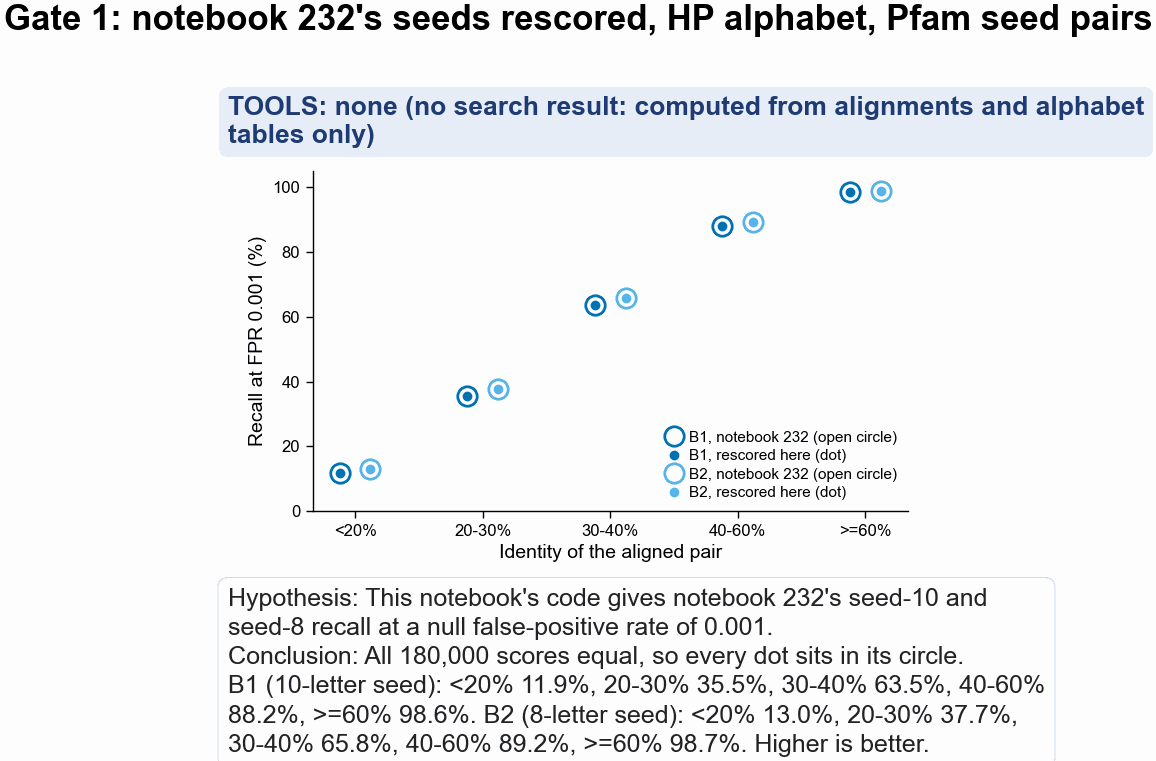

In [2]:
real_all, null_all, bin_all, pidx_all = lp.score_arrays(d, COLS)
thr_all, rate_all, rec_all = lp.threshold_and_recall(real_all, null_all, bin_all, FPR)

s232 = hc.add_identity_bin(
    pl.read_parquet(NB232).filter(
        (pl.col("dataset") == "pfam")
        & (pl.col("alphabet") == lp.ALPHABET)
        & (pl.col("penalty") == 2.0)
        & pl.col("seed").is_in([8, 10])
    )
)
r232 = se.recall_at_null_quantile(s232, ["seed"], FPR)
same_scores = d.join(
    s232.pivot(on="seed", index=["query", "target", "kind"], values="score"),
    on=["query", "target", "kind"],
).select(
    (pl.col("B1_ext") == pl.col("10")).mean().alias("B1 equal"),
    (pl.col("B2_ext") == pl.col("8")).mean().alias("B2 equal"),
    pl.len(),
)
print("share of the 180,000 comparisons whose score equals 232's stored score:")
print(same_scores)
gate1 = pl.DataFrame(
    {
        "identity_bin": BINS,
        "B1 here": rec_all[:, COLS.index("B1_ext")].round(3),
        "B1 in 232": [
            r232.filter((pl.col("seed") == 10) & (pl.col("identity_bin") == b))[
                "recall"
            ][0]
            for b in BINS
        ],
        "B2 here": rec_all[:, COLS.index("B2_ext")].round(3),
        "B2 in 232": [
            r232.filter((pl.col("seed") == 8) & (pl.col("identity_bin") == b))[
                "recall"
            ][0]
            for b in BINS
        ],
    }
).with_columns(pl.col("B1 in 232").round(3), pl.col("B2 in 232").round(3))
print(gate1)
print(
    f"thresholds: B1 {thr_all[0]:.0f}, B2 {thr_all[1]:.0f}; achieved null rate B1 {rate_all[0]:.5f}, B2 {rate_all[1]:.5f}"
)
gate1_ok = (gate1["B1 here"] == gate1["B1 in 232"]).all() and (
    gate1["B2 here"] == gate1["B2 in 232"]
).all()
print("Gate 1 reproduced to the digit:", gate1_ok)
assert gate1_ok

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55, layout=None)
x = np.arange(len(BINS))
for name, col232, colhere, dx in [
    ("B1", "B1 in 232", "B1 here", -0.12),
    ("B2", "B2 in 232", "B2 here", 0.12),
]:
    ax.plot(
        x + dx,
        100 * gate1[col232],
        color=COLOR[name],
        marker="o",
        ms=7,
        mfc="none",
        mew=1,
        lw=0,
        label=f"{name}, notebook 232 (open circle)",
    )
    ax.plot(
        x + dx,
        100 * gate1[colhere],
        color=COLOR[name],
        marker="o",
        ms=2.5,
        lw=0,
        label=f"{name}, rescored here (dot)",
    )
ax.set_xticks(x, BINS)
ax.set_xlabel("Identity of the aligned pair")
ax.set_ylabel("Recall at FPR 0.001 (%)")
ax.set_ylim(0, 105)
ax.legend(loc="lower right", fontsize=5.5)
hc.finish_figure(
    fig,
    FIG / "294_gate1_reproduce_nb232_pfam_seed.png",
    tools=hc.NO_TOOL,
    hypothesis="This notebook's code gives notebook 232's seed-10 and seed-8 recall at a null false-positive rate of 0.001.",
    conclusion=(
        f"All 180,000 scores equal, so every dot sits in its circle. B1 (10-letter seed): "
        + ", ".join(f"{b} {100 * v:.1f}%" for b, v in zip(BINS, gate1["B1 here"]))
        + ". B2 (8-letter seed): "
        + ", ".join(f"{b} {100 * v:.1f}%" for b, v in zip(BINS, gate1["B2 here"]))
        + ". Higher is better."
    ),
    title="Gate 1: notebook 232's seeds rescored, HP alphabet, Pfam seed pairs",
    wrap=70,
)

## 2. The sweep, on the selection half

72 linked-pair settings (2 ways to pick keys × 4 anchor lengths × 3 window sizes × 3 gap
rules), each scored with extension. Recall at 20–30% identity at the 0.001 threshold, on a
random half of the true pairs and their own shuffled nulls. The setting with the highest
value is chosen here and only evaluated in section 4. Every square is one setting; the
chosen one is outlined. Settings whose threshold is 0 (the table's `threshold` column) never
reach an FPR of 0.001: almost no null comparison has a shared key, so any shared key counts.
Their FPR is lower than B1's and B2's, and their recall is not comparable.

selection half 30_000 pairs, report half 30_000 pairs


selection half, 20-30% bin: B1 0.384, B2 0.375
chosen: all_a6_g32_none; best one-partner-per-position setting: rand_a6_g32_none
shape: (72, 8)
┌──────────────────────┬──────┬────────┬─────────┬──────────┬───────────┬───────────┬──────────────┐
│ setting              ┆ mode ┆ anchor ┆ gap_max ┆ gap_rule ┆ threshold ┆ null_rate ┆ recall_20_30 │
│ ---                  ┆ ---  ┆ ---    ┆ ---     ┆ ---      ┆ ---       ┆ ---       ┆ ---          │
│ str                  ┆ str  ┆ i64    ┆ i64     ┆ str      ┆ f64       ┆ f64       ┆ f64          │
╞══════════════════════╪══════╪════════╪═════════╪══════════╪═══════════╪═══════════╪══════════════╡
│ all_a6_g32_none      ┆ all  ┆ 6      ┆ 32      ┆ none     ┆ 29.0      ┆ 0.00097   ┆ 0.464        │
│ all_a7_g32_none      ┆ all  ┆ 7      ┆ 32      ┆ none     ┆ 28.0      ┆ 0.00098   ┆ 0.46         │
│ all_a6_g16_none      ┆ all  ┆ 6      ┆ 16      ┆ none     ┆ 27.0      ┆ 0.00097   ┆ 0.446        │
│ all_a8_g32_none      ┆ all  ┆ 8      ┆ 32      

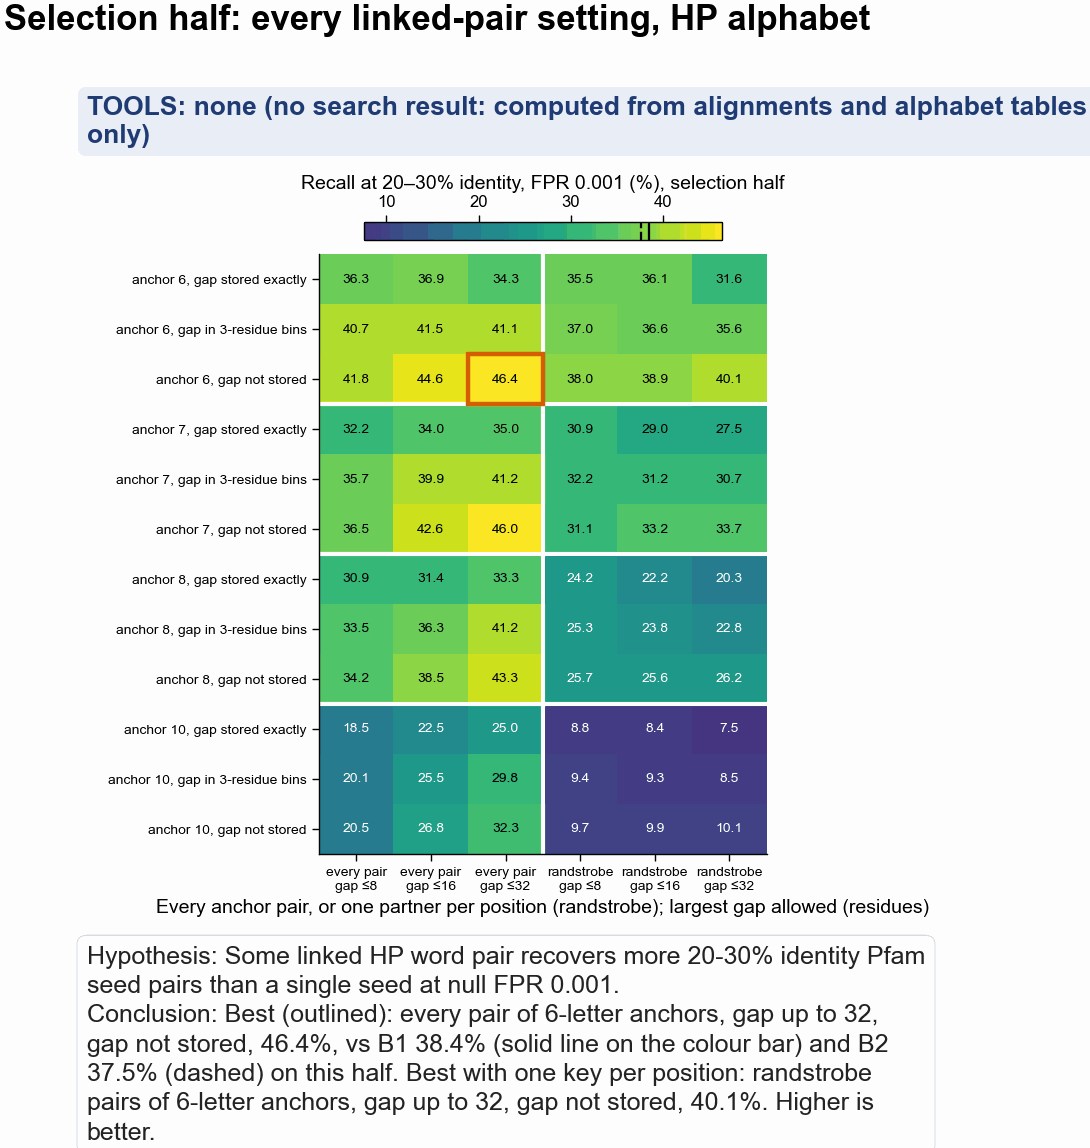

In [3]:
rng = np.random.default_rng(SPLIT_SEED)
perm = rng.permutation(np.unique(pidx_all))
select_ids = np.sort(perm[: perm.size // 2])
is_select = np.isin(pidx_all, select_ids)
print(
    f"selection half {is_select.sum():_} pairs, report half {(~is_select).sum():_} pairs"
)

real_s, null_s, bin_s = real_all[is_select], null_all[is_select], bin_all[is_select]
thr_s, rate_s, rec_s = lp.threshold_and_recall(real_s, null_s, bin_s, FPR)
b2030 = BINS.index("20-30%")
sweep = pl.DataFrame(
    {
        "setting": LINKED,
        "mode": [s[0] for s in lp.ALL_SETTINGS],
        "anchor": [s[1] for s in lp.ALL_SETTINGS],
        "gap_max": [s[2] for s in lp.ALL_SETTINGS],
        "gap_rule": [s[3] for s in lp.ALL_SETTINGS],
        "threshold": [thr_s[COLS.index(f"{s}_ext")] for s in LINKED],
        "null_rate": [rate_s[COLS.index(f"{s}_ext")] for s in LINKED],
        "recall_20_30": [rec_s[b2030, COLS.index(f"{s}_ext")] for s in LINKED],
    }
).sort("recall_20_30", descending=True)
CHOSEN = sweep["setting"][0]
CHOSEN_RAND = sweep.filter(pl.col("mode") == "rand")["setting"][0]
base_sel = {n: rec_s[b2030, COLS.index(f"{n}_ext")] for n in ["B1", "B2"]}
print(f"selection half, 20-30% bin: B1 {base_sel['B1']:.3f}, B2 {base_sel['B2']:.3f}")
print(f"chosen: {CHOSEN}; best one-partner-per-position setting: {CHOSEN_RAND}")
print(sweep.with_columns(pl.col("recall_20_30").round(3), pl.col("null_rate").round(5)))

# heatmap: rows = anchor length x gap rule, columns = key choice x window
rows_ = [(a, t) for a in lp.ANCHOR_LENGTHS for t in lp.TREATMENTS]
cols_ = [(m, g) for m in lp.MODES for g in lp.GAP_MAXES]
H = np.array(
    [
        [
            sweep.filter(pl.col("setting") == lp.setting_name(m, a, g, t))[
                "recall_20_30"
            ][0]
            for (m, g) in cols_
        ]
        for (a, t) in rows_
    ]
)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 105, layout=None)
cmap = mpl.colors.ListedColormap(plt.cm.viridis(np.linspace(0.15, 1, 256)))
im = ax.imshow(
    H * 100, cmap=cmap, aspect="auto", vmin=H.min() * 100, vmax=H.max() * 100
)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = 100 * H[i, j]
        ax.text(
            j,
            i,
            f"{v:.1f}",
            ha="center",
            va="center",
            fontsize=5,
            color="white" if v < (H.min() + H.max()) * 50 else "black",
        )
for m, a, g, t in [s for s in lp.ALL_SETTINGS if lp.setting_name(*s) == CHOSEN]:
    ax.add_patch(
        Rectangle(
            (cols_.index((m, g)) - 0.5, rows_.index((a, t)) - 0.5),
            1,
            1,
            fill=False,
            ec=COLOR["linked"],
            lw=1.6,
            clip_on=False,
            zorder=10,
        )
    )
ax.set_xticks(
    range(len(cols_)),
    [f"{'every pair' if m == 'all' else 'randstrobe'}\ngap ≤{g}" for m, g in cols_],
    fontsize=5,
)
ax.set_xlabel(
    "Every anchor pair, or one partner per position (randstrobe); largest gap allowed (residues)"
)
ax.set_yticks(
    range(len(rows_)), [f"anchor {a}, {TREAT_LABEL[t]}" for a, t in rows_], fontsize=5
)
for k in range(1, len(lp.ANCHOR_LENGTHS)):
    ax.axhline(k * len(lp.TREATMENTS) - 0.5, color="white", lw=1.5)
ax.axvline(len(lp.GAP_MAXES) - 0.5, color="white", lw=1.5)
cb = fig.colorbar(im, ax=ax, location="top", shrink=0.8, pad=0.02)
cb.set_label("Recall at 20–30% identity, FPR 0.001 (%), selection half")
for n, ls_ in [("B1", "-"), ("B2", "--")]:
    cb.ax.axvline(100 * base_sel[n], color="black", lw=0.8, ls=ls_)
hc.finish_figure(
    fig,
    FIG / "294_sweep_recall_20_30_selection_half_pfam_seed.png",
    tools=hc.NO_TOOL,
    hypothesis="Some linked HP word pair recovers more 20-30% identity Pfam seed pairs than a single seed at null FPR 0.001.",
    conclusion=(
        f"Best (outlined): {plain(CHOSEN)}, {100 * sweep['recall_20_30'][0]:.1f}%, vs B1 {100 * base_sel['B1']:.1f}% (solid line on the colour bar) and B2 {100 * base_sel['B2']:.1f}% (dashed) on this half. "
        f"Best with one key per position: {plain(CHOSEN_RAND)}, {100 * sweep.filter(pl.col('setting') == CHOSEN_RAND)['recall_20_30'][0]:.1f}%. Higher is better."
    ),
    title="Selection half: every linked-pair setting, HP alphabet",
    wrap=75,
    header_y=0.955,
)

## 3. What one key looks like on a real pair

One true pair from the report half at 20–30% identity, picked by a rule written before
looking: among pairs where the chosen setting scores above its threshold and B1 and B2 both
do not, keep those whose best key spans an insertion or deletion (query gap ≠ target gap),
then take the shortest alignment. Rows per block: query residues, query HP classes (H =
`ACFILMVWY`, P = `DEGHKNPQRST`), `|` where the two classes match, target HP classes, target
residues. The two boxes are the anchors of the best-scoring key; the line under them is
the gap; the black bar marks the longest run of matching HP classes, the longest exact HP
word the two share; the arrow marks the alignment column with an insertion.

The cell also lists which Pfam families the pairs found only by the linked key come from,
and how hydrophobic they are, because a key built from 6-letter HP words could favour
hydrophobic, membrane-spanning stretches.

report-half 20-30% pairs found by the chosen setting but by neither B1 nor B2: 709 of 7_512
634 of them have a best key across an insertion or deletion


hydrophobic share of the query (ACFILMVWY), report-half 20-30% pairs:
shape: (2, 4)
┌──────────────────────┬─────────┬────────┬────────────────────────────┐
│ found_only_by_linked ┆ n_pairs ┆ median ┆ share_with_60pct_or_more_H │
│ ---                  ┆ ---     ┆ ---    ┆ ---                        │
│ bool                 ┆ u32     ┆ f64    ┆ f64                        │
╞══════════════════════╪═════════╪════════╪════════════════════════════╡
│ false                ┆ 6803    ┆ 0.43   ┆ 0.031                      │
│ true                 ┆ 709     ┆ 0.432  ┆ 0.025                      │
└──────────────────────┴─────────┴────────┴────────────────────────────┘
Pfam families with the most pairs found only by the linked key:
shape: (10, 3)
┌─────────┬─────────────────┬─────┐
│ family  ┆ family_id       ┆ len │
│ ---     ┆ ---             ┆ --- │
│ str     ┆ str             ┆ u32 │
╞═════════╪═════════════════╪═════╡
│ PF00136 ┆ DNA_pol_B       ┆ 2   │
│ PF00443 ┆ UCH             ┆ 2   │
│

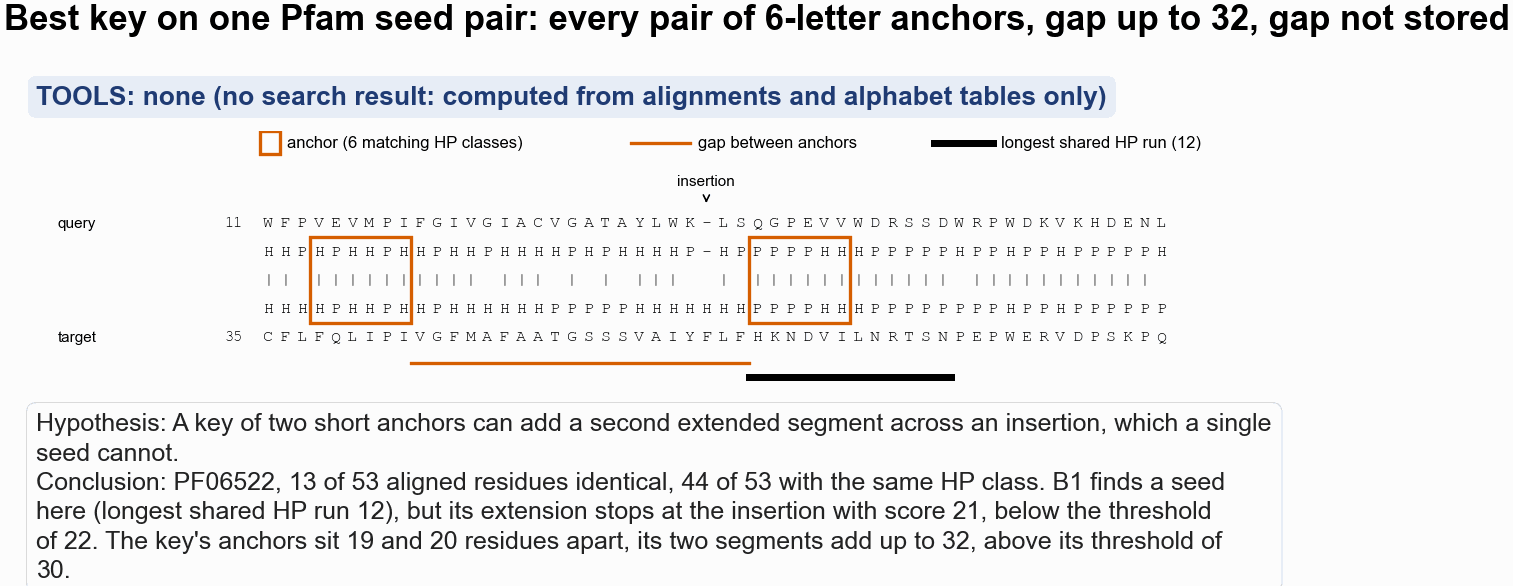

In [4]:
m_c, a_c, g_c, t_c = next(s for s in lp.ALL_SETTINGS if lp.setting_name(*s) == CHOSEN)
c_ext = COLS.index(f"{CHOSEN}_ext")
rep = ~is_select
thr_rep, _, _ = lp.threshold_and_recall(real_all[rep], null_all[rep], bin_all[rep], FPR)
cand = (
    rep
    & (bin_all == b2030)
    & (real_all[:, c_ext] > thr_rep[c_ext])
    & (real_all[:, COLS.index("B1_ext")] <= thr_rep[COLS.index("B1_ext")])
    & (real_all[:, COLS.index("B2_ext")] <= thr_rep[COLS.index("B2_ext")])
)
print(
    f"report-half 20-30% pairs found by the chosen setting but by neither B1 nor B2: {cand.sum():_} "
    f"of {(rep & (bin_all == b2030)).sum():_}"
)
aln = (
    pl.read_parquet(ALN)
    .filter(pl.col("lali") >= 50)
    .sample(n=60_000, seed=0, shuffle=True)
    .with_row_index("pair_index")
    .filter(pl.col("pair_index").is_in(pidx_all[cand].tolist()))
)
ex_rows = []
for r in aln.iter_rows(named=True):
    k = lp.best_key(r["qaln"], r["taln"], m_c, a_c, g_c, t_c)
    if k and k["gap_query"] != k["gap_target"]:
        ex_rows.append({**r, **k})
ex = (
    pl.DataFrame(ex_rows)
    .with_columns(pl.col("qaln").str.len_chars().alias("aln_len"))
    .sort("aln_len", "pair_index")
)
print(f"{ex.height} of them have a best key across an insertion or deletion")
all_2030 = (
    pl.read_parquet(ALN)
    .filter(pl.col("lali") >= 50)
    .sample(n=60_000, seed=0, shuffle=True)
    .with_row_index("pair_index")
    .filter(pl.col("pair_index").is_in(pidx_all[rep & (bin_all == b2030)].tolist()))
)
H_SET = set("ACFILMVWY")


def h_share(aln_str):
    res = [c for c in aln_str.upper() if c != "-"]
    return sum(c in H_SET for c in res) / len(res)


all_2030 = all_2030.with_columns(
    pl.col("qaln")
    .map_elements(h_share, return_dtype=pl.Float64)
    .alias("query_h_share"),
    pl.col("pair_index").is_in(pidx_all[cand].tolist()).alias("found_only_by_linked"),
)
print("hydrophobic share of the query (ACFILMVWY), report-half 20-30% pairs:")
print(
    all_2030.group_by("found_only_by_linked")
    .agg(
        pl.len().alias("n_pairs"),
        pl.col("query_h_share").median().round(3).alias("median"),
        (pl.col("query_h_share") >= 0.6)
        .mean()
        .round(3)
        .alias("share_with_60pct_or_more_H"),
    )
    .sort("found_only_by_linked")
)
print("Pfam families with the most pairs found only by the linked key:")
print(
    all_2030.filter(pl.col("found_only_by_linked"))
    .group_by("family", "family_id")
    .len()
    .sort(["len", "family"], descending=[True, False])
    .head(10)
)
E = ex.row(0, named=True)
row_scores = real_all[np.flatnonzero(pidx_all == E["pair_index"])[0]]
assert E["score"] == row_scores[c_ext], "best_key disagrees with the stored score"

tab = lp.TABLES[lp.ALPHABET]
q, t = E["qaln"], E["taln"]
qc, tc = (
    tab[np.frombuffer(q.encode(), np.uint8)],
    tab[np.frombuffer(t.encode(), np.uint8)],
)
match = (qc == tc) & (qc != lp.GAP) & (tc != lp.GAP)
run = np.diff(np.concatenate(([0], match.astype(int), [0])))
starts, ends = np.flatnonzero(run == 1), np.flatnonzero(run == -1)
lr = int(np.argmax(ends - starts))
run_s, run_e = starts[lr], ends[lr]
aligned = (np.frombuffer(q.encode(), np.uint8) != ord("-")) & (
    np.frombuffer(t.encode(), np.uint8) != ord("-")
)
n_ident = sum(1 for x, y in zip(q, t) if x == y and x != "-")
hp = lambda c: "".join(
    "-" if ch == "-" else ("H" if v == 0 else ("P" if v == 1 else "X"))
    for ch, v in zip(c, tab[np.frombuffer(c.encode(), np.uint8)])
)
q_hp, t_hp = hp(q), hp(t)
mline = "".join("|" if mm else " " for mm in match)
q0 = int(E["query"].split("/")[1].split("-")[0])
t0 = int(E["target"].split("/")[1].split("-")[0])
print(
    f"{E['family']}: {E['query']} vs {E['target']}; {n_ident} of {int(aligned.sum())} aligned columns identical "
    f"({100 * E['seqid_ali']:.0f}%), {int(match.sum())} of {int(aligned.sum())} with matching HP classes"
)
print(
    f"best key: anchors of {a_c} at alignment columns {E['c1']} and {E['c2']}; gap {E['gap_query']} residues in the query, "
    f"{E['gap_target']} in the target; key score {E['score']:.0f} (threshold {thr_rep[c_ext]:.0f}); {E['n_keys']} shared keys"
)
print(
    f"B1 score {row_scores[COLS.index('B1_ext')]:.0f}, B2 score {row_scores[COLS.index('B2_ext')]:.0f} (threshold {thr_rep[COLS.index('B1_ext')]:.0f}); "
    f"longest shared HP run {run_e - run_s} residues"
)
print(
    "Rows: query residues, query HP, | where the HP classes match, target HP, target residues; numbers are residue positions"
)
qi, ti = q0, t0
for s_ in range(0, len(q), 70):
    qs, ts = q[s_ : s_ + 70], t[s_ : s_ + 70]
    print(f"query  {qi:>4} {qs}")
    print(f"            {q_hp[s_:s_ + 70]}")
    print(f"            {mline[s_:s_ + 70]}")
    print(f"            {t_hp[s_:s_ + 70]}")
    print(f"target {ti:>4} {ts}")
    print()
    qi += sum(ch != "-" for ch in qs)
    ti += sum(ch != "-" for ch in ts)

W = 70
nblk = int(np.ceil(len(q) / W))
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 16 + 22 * nblk, layout=None)
ax.set_axis_off()
ax.set_xlim(-12, W + 1)
ax.set_ylim(-nblk * 7.2 + 1.4, 3.2)
mono = dict(family="monospace", fontsize=6, va="center")


def resnum(s, start, upto):
    return start + sum(1 for ch in s[:upto] if ch != "-")


ax.add_patch(Rectangle((0, 2.4), 1.2, 0.8, fill=False, ec=COLOR["linked"], lw=1.2))
ax.text(1.6, 2.8, f"anchor ({a_c} matching HP classes)", fontsize=6, va="center")
ax.plot([22, 25.5], [2.8, 2.8], color=COLOR["linked"], lw=1.2)
ax.text(26, 2.8, "gap between anchors", fontsize=6, va="center")
ax.plot([40, 43.5], [2.8, 2.8], color="black", lw=2.5)
ax.text(44, 2.8, f"longest shared HP run ({run_e - run_s})", fontsize=6, va="center")
for b in range(nblk):
    s, e = b * W, min((b + 1) * W, len(q))
    y0 = -b * 7.2
    for k_, (lab, txt) in enumerate(
        [
            (f"{resnum(q, q0, s)}", q[s:e]),
            ("", q_hp[s:e]),
            ("", mline[s:e]),
            ("", t_hp[s:e]),
            (f"{resnum(t, t0, s)}", t[s:e]),
        ]
    ):
        y = y0 - k_
        ax.text(-1, y, lab, ha="right", **{**mono, "fontsize": 5.5})
        for i, ch in enumerate(txt):
            ax.text(i + 0.5, y, ch, ha="center", **mono)
    ax.text(-12, y0, "query", fontsize=5.5, va="center")
    ax.text(-12, y0 - 4, "target", fontsize=5.5, va="center")
    for cstart in (E["c1"], E["c2"]):
        lo, hi = max(cstart, s), min(cstart + a_c, e)
        if lo < hi:
            ax.add_patch(
                Rectangle(
                    (lo - s, y0 - 3.5),
                    hi - lo,
                    3.0,
                    fill=False,
                    ec=COLOR["linked"],
                    lw=1.2,
                )
            )
    lo, hi = max(E["c1"] + a_c, s), min(E["c2"], e)
    if lo < hi:
        ax.plot([lo - s, hi - s], [y0 - 4.9, y0 - 4.9], color=COLOR["linked"], lw=1.2)
    lo, hi = max(run_s, s), min(run_e, e)
    if lo < hi:
        ax.plot([lo - s, hi - s], [y0 - 5.4, y0 - 5.4], color="black", lw=2.5)
    for col_ in range(max(E["c1"] + a_c, s), min(E["c2"], e)):
        if q[col_] == "-" or t[col_] == "-":
            ax.annotate(
                "insertion",
                xy=(col_ - s + 0.5, y0 + 0.5),
                xytext=(col_ - s + 0.5, y0 + 1.3),
                ha="center",
                fontsize=5.5,
                arrowprops=dict(arrowstyle="->", lw=0.6, color="black"),
            )
hc.finish_figure(
    fig,
    FIG / "294_example_linked_key_pfam_seed_pair.png",
    tools=hc.NO_TOOL,
    hypothesis="A key of two short anchors can add a second extended segment across an insertion, which a single seed cannot.",
    conclusion=(
        f"{E['family']}, {n_ident} of {int(aligned.sum())} aligned residues identical, {int(match.sum())} of {int(aligned.sum())} with the same HP class. "
        f"B1 finds a seed here (longest shared HP run {run_e - run_s}), but its extension stops at the insertion with score {row_scores[COLS.index('B1_ext')]:.0f}, below the threshold of {thr_rep[COLS.index('B1_ext')]:.0f}. "
        f"The key's anchors sit {E['gap_query']} and {E['gap_target']} residues apart, its two segments add up to {E['score']:.0f}, above its threshold of {thr_rep[c_ext]:.0f}."
    ),
    title=f"Best key on one Pfam seed pair: {plain(CHOSEN)}",
    wrap=110,
)

## 4. The verdict, on the report half

### 4a. The rule set before the run

Recall at the 0.001 threshold (232's rule: strictly above the threshold, so the null rate
is at or below 0.001), with bootstrap intervals that resample pairs one by one. The KILL
condition, "no setting beats the better of B1 and B2 outside the bootstrap interval", is
checked for all 72 settings in three readings: (1) the setting's interval lies wholly above
both baselines' intervals; (2) the setting's own value lies above them; (3) a paired
bootstrap of the setting minus the better baseline excludes 0. The readings disagree, which
is why section 4b restates the rule.

shape: (25, 9)
┌──────────────┬───────────────────────┬───────────┬───────────┬──────────────┬──────────────┬────────┬────────┬─────────┐
│ score        ┆ column                ┆ threshold ┆ null_rate ┆ identity_bin ┆ n_true_pairs ┆ recall ┆ ci_low ┆ ci_high │
│ ---          ┆ ---                   ┆ ---       ┆ ---       ┆ ---          ┆ ---          ┆ ---    ┆ ---    ┆ ---     │
│ str          ┆ str                   ┆ f64       ┆ f64       ┆ str          ┆ i64          ┆ f64    ┆ f64    ┆ f64     │
╞══════════════╪═══════════════════════╪═══════════╪═══════════╪══════════════╪══════════════╪════════╪════════╪═════════╡
│ B1           ┆ B1_ext                ┆ 22.0      ┆ 0.0008    ┆ <20%         ┆ 3256         ┆ 0.116  ┆ 0.096  ┆ 0.141   │
│ B1           ┆ B1_ext                ┆ 22.0      ┆ 0.0008    ┆ 20-30%       ┆ 7512         ┆ 0.356  ┆ 0.323  ┆ 0.397   │
│ B1           ┆ B1_ext                ┆ 22.0      ┆ 0.0008    ┆ 30-40%       ┆ 7024         ┆ 0.633  ┆ 0.6    ┆ 0.669   │
│

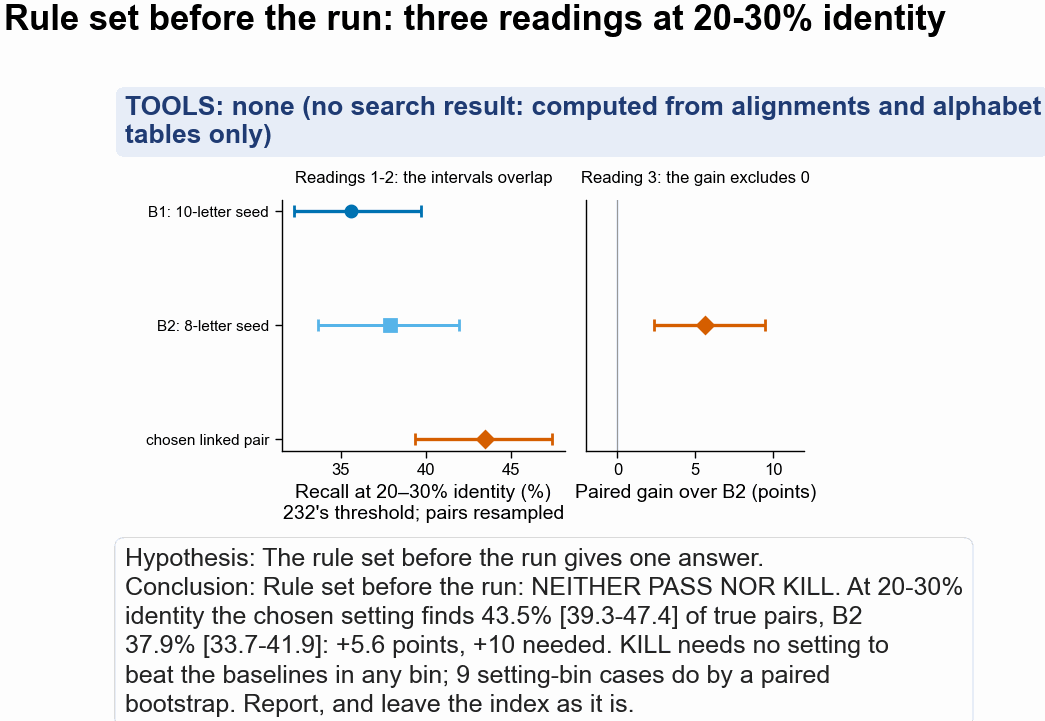

In [5]:
real_r, null_r, bin_r = real_all[rep], null_all[rep], bin_all[rep]
# every linked setting is bootstrapped too: the KILL rule is about any setting, in any bin
EXT = ["B1_ext", "B2_ext"] + [f"{x}_ext" for x in LINKED] + [f"{CHOSEN}_count"]
idx = [COLS.index(c) for c in EXT]
thr_r, rate_r, rec_r = lp.threshold_and_recall(
    real_r[:, idx], null_r[:, :, idx], bin_r, FPR
)
boot = lp.bootstrap_recall(
    real_r[:, idx], null_r[:, :, idx], bin_r, FPR, N_BOOT, seed=1
)
lo, hi = np.percentile(boot, 2.5, axis=0), np.percentile(boot, 97.5, axis=0)
SHOW = {
    "B1": "B1_ext",
    "B2": "B2_ext",
    "linked": f"{CHOSEN}_ext",
    "linked_count": f"{CHOSEN}_count",
    "randstrobe": f"{CHOSEN_RAND}_ext",
}
J = {n: EXT.index(c) for n, c in SHOW.items()}
res = pl.DataFrame(
    [
        {
            "score": n,
            "column": SHOW[n],
            "threshold": thr_r[j],
            "null_rate": rate_r[j],
            "identity_bin": b,
            "n_true_pairs": int((bin_r == i).sum()),
            "recall": rec_r[i, j],
            "ci_low": lo[i, j],
            "ci_high": hi[i, j],
        }
        for n, j in J.items()
        for i, b in enumerate(BINS)
    ]
)
print(
    res.with_columns(
        pl.col("recall", "ci_low", "ci_high").round(3), pl.col("null_rate").round(5)
    )
)

jB1, jB2, jL = J["B1"], J["B2"], J["linked"]
best_base = jB1 if rec_r[b2030, jB1] >= rec_r[b2030, jB2] else jB2
base_name = "B1" if best_base == jB1 else "B2"
gain = rec_r[b2030, jL] - rec_r[b2030, best_base]
pass_rule = gain >= 0.10 and lo[b2030, jL] > hi[b2030, best_base]
base_hi = np.maximum(
    hi[:, jB1], hi[:, jB2]
)  # upper end of the better baseline's interval, per bin
lin = [EXT.index(f"{x}_ext") for x in LINKED]
# reading 1 (the one PASS uses): the setting's interval lies wholly above the baselines' intervals
beats_strict = [
    (LINKED[k], BINS[i])
    for k, j in enumerate(lin)
    for i in range(len(BINS))
    if lo[i, j] > base_hi[i]
]
# reading 2: the setting's own value lies above the baselines' intervals
beats_loose = [
    (LINKED[k], BINS[i])
    for k, j in enumerate(lin)
    for i in range(len(BINS))
    if rec_r[i, j] > base_hi[i]
]
# reading 3: a paired bootstrap of the setting minus the better baseline (same resamples) excludes 0
better = [jB1 if rec_r[i, jB1] >= rec_r[i, jB2] else jB2 for i in range(len(BINS))]
beats_paired = [
    (LINKED[k], BINS[i])
    for k, j in enumerate(lin)
    for i in range(len(BINS))
    if np.percentile(boot[:, i, j] - boot[:, i, better[i]], 2.5) > 0
]
print(
    "All 72 linked settings, report half, against the better of B1 and B2 in each identity bin:"
)
print(
    f"  setting-bin cases whose interval lies wholly above both baselines' intervals: {len(beats_strict)}"
)
print(
    f"  setting-bin cases whose value lies above both baselines' intervals: {len(beats_loose)}"
)
print(
    f"  setting-bin cases whose paired gain over the better baseline excludes 0: {len(beats_paired)}"
)
cases = (
    pl.DataFrame(beats_loose, schema=["setting", "identity_bin"], orient="row")
    .with_columns(pl.lit("value above both intervals").alias("reading"))
    .vstack(
        pl.DataFrame(
            beats_paired, schema=["setting", "identity_bin"], orient="row"
        ).with_columns(pl.lit("paired gain excludes 0").alias("reading"))
    )
)
print(cases.sort("reading", "setting", "identity_bin"))
if pass_rule:
    VERDICT_PRE = "PASS"
elif not (beats_strict or beats_loose or beats_paired):
    VERDICT_PRE = "KILL"
else:
    VERDICT_PRE = "NEITHER PASS NOR KILL"
diff_boot = boot[:, b2030, jL] - boot[:, b2030, best_base]
d_lo, d_hi = np.percentile(diff_boot, [2.5, 97.5])
verdict_pre_line = (
    f"Rule set before the run: {VERDICT_PRE}. At 20-30% identity the chosen setting finds {100 * rec_r[b2030, jL]:.1f}% "
    f"[{100 * lo[b2030, jL]:.1f}-{100 * hi[b2030, jL]:.1f}] of true pairs, {base_name} {100 * rec_r[b2030, best_base]:.1f}% "
    f"[{100 * lo[b2030, best_base]:.1f}-{100 * hi[b2030, best_base]:.1f}]: +{100 * gain:.1f} points, +10 needed. "
    f"KILL needs no setting to beat the baselines in any bin; {len(beats_paired)} setting-bin cases do by a paired bootstrap. Report, and leave the index as it is."
)
print(verdict_pre_line)
print(
    f"Only the strictest reading (one interval wholly above another) would call it KILL; the other two do not. Not PASS under any reading."
)
print(
    f"Gain of the chosen setting over {base_name} at 20-30%, paired bootstrap (same resamples): {100 * gain:.1f} points, 95% interval {100 * d_lo:.1f} to {100 * d_hi:.1f}"
)
names = list(J)
jR = J["randstrobe"]
r_lo, r_hi = np.percentile(boot[:, b2030, jR] - boot[:, b2030, best_base], [2.5, 97.5])
print(
    f"Randstrobe setting over {base_name} at 20-30%, paired: {100 * (rec_r[b2030, jR] - rec_r[b2030, best_base]):.1f} points, 95% interval {100 * r_lo:.1f} to {100 * r_hi:.1f}"
)
# why the single-setting intervals are wide: recall at 20-30% one score step either side of the threshold
for n in ["B2", "linked"]:
    j = J[n]
    col = real_r[:, idx[j]][bin_r == b2030]
    nul = null_r[:, :, idx[j]].ravel()
    print(
        f"{n}: "
        + "; ".join(
            f"threshold {t:.0f}: recall {100 * (col > t).mean():.1f}%, null rate {(nul > t).mean():.5f}"
            for t in (thr_r[j] - 1, thr_r[j], thr_r[j] + 1)
        )
    )

# the three readings at 20-30% identity: each score's interval, and the paired gain
fig, axes = pf.figure(
    pf.ONE_COLUMN_MM, 50, ncols=2, layout=None, gridspec_kw={"width_ratios": [1.3, 1]}
)
ax = axes[0]
for y, (n, mk, filled) in enumerate(
    [("linked", "D", True), ("B2", "s", True), ("B1", "o", True)]
):
    j = J[n]
    ax.errorbar(
        100 * rec_r[b2030, j],
        y,
        xerr=[
            [100 * (rec_r[b2030, j] - lo[b2030, j])],
            [100 * (hi[b2030, j] - rec_r[b2030, j])],
        ],
        color=COLOR[n],
        marker=mk,
        ms=4,
        lw=1.2,
        capsize=2,
    )
ax.set_yticks(
    range(3),
    ["chosen linked pair", "B2: 8-letter seed", "B1: 10-letter seed"],
    fontsize=5.5,
)
ax.set_xlabel("Recall at 20–30% identity (%)\n232's threshold; pairs resampled")
ax.set_title("Readings 1-2: the intervals overlap", fontsize=6)
ax = axes[1]
ax.errorbar(
    100 * gain,
    0,
    xerr=[[100 * (gain - d_lo)], [100 * (d_hi - gain)]],
    color=COLOR["linked"],
    marker="D",
    ms=4,
    lw=1.2,
    capsize=2,
)
ax.axvline(0, color="0.6", lw=0.5)
ax.set_yticks([])
ax.set_xlim(-2, 12)
ax.set_xlabel("Paired gain over B2 (points)")
ax.set_title("Reading 3: the gain excludes 0", fontsize=6)
hc.finish_figure(
    fig,
    FIG / "294_rule_before_run_three_readings_pfam_seed.png",
    tools=hc.NO_TOOL,
    hypothesis="The rule set before the run gives one answer.",
    conclusion=verdict_pre_line,
    title="Rule set before the run: three readings at 20-30% identity",
    wrap=70,
)

### 4b. The rule set after the first run (2026-10-15)

This rule was written on 2026-10-15, after the numbers in 4a had been seen, because the
rule above could be read three ways. Its result is not a pre-registered test; it says
what the data already collected can and cannot rule out.

- *One number*: the gain in recall at 20–30% identity of the chosen setting over the better
  single seed (B1 or B2, whichever is higher on this half), from the same resamples
  (a paired bootstrap).
- *At exactly FPR 0.001*: scores are whole numbers, so 232's threshold calls fewer than
  0.1% of null comparisons, by a different amount for each score. Here recall is read off
  the line between the two thresholds either side of 0.001, which is what breaking ties at
  random to call exactly 0.1% of the null gives.
- *Resampled by family*: pairs from one Pfam family share sequence, so the bootstrap draws
  whole families (with all their pairs and shuffled targets), 1,000 times.
- *Cut-off*: 10 percentage points, the gain the original rule asked for.
  PASS if the whole 95% interval is at or above 10. KILL if the whole interval is below
  10: a gain worth an index change is ruled out. Unclear if it crosses 10: more pairs are
  needed.
- *B3 control*: B2's 8-letter seed plus the best second gap-free segment that contains any
  matching column within 32 residues of the seed, scored as up to two segments exactly like
  a linked key. If the linked key does no better than B3, the gain comes from scoring a
  second segment, not from the second exact word.

The recall figure shows every score with family-resampled intervals; the decision figure
shows the paired gains against the 10-point line.

report half: 30_000 true pairs in 18_617 Pfam families (largest family 6 pairs)
Recall at exactly FPR 0.001, family-resampled 95% intervals:
shape: (30, 9)
┌──────────────┬───────────────────────┬───────────┬──────────────────────┬──────────────┬──────────────┬──────────────────┬────────┬─────────┐
│ score        ┆ column                ┆ threshold ┆ share_of_ties_called ┆ identity_bin ┆ n_true_pairs ┆ recall_exact_fpr ┆ ci_low ┆ ci_high │
│ ---          ┆ ---                   ┆ ---       ┆ ---                  ┆ ---          ┆ ---          ┆ ---              ┆ ---    ┆ ---     │
│ str          ┆ str                   ┆ f64       ┆ f64                  ┆ str          ┆ i64          ┆ f64              ┆ f64    ┆ f64     │
╞══════════════╪═══════════════════════╪═══════════╪══════════════════════╪══════════════╪══════════════╪══════════════════╪════════╪═════════╡
│ B1           ┆ B1_ext                ┆ 22.0      ┆ 0.706                ┆ <20%         ┆ 3256         ┆ 0.129            ┆

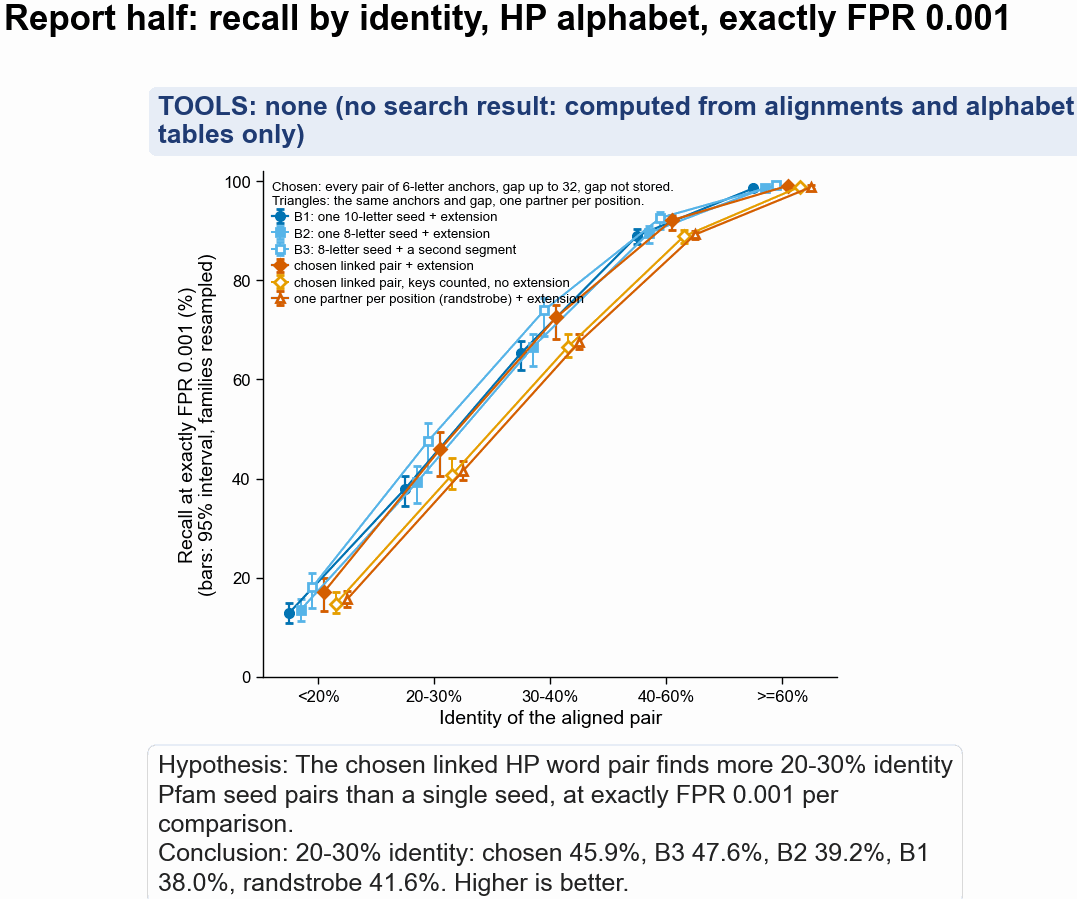

In [6]:
fam_codes = (
    d.filter(pl.col("kind") == "real")
    .sort("pair_index")
    .select(pl.col("family").cast(pl.Categorical).to_physical())
    .to_series()
    .to_numpy()
)
assert (np.sort(pidx_all) == pidx_all).all()  # score_arrays sorts by pair_index too
fam_r = fam_codes[rep]
NEW = {
    "B1": "B1_ext",
    "B2": "B2_ext",
    "B3": "B3_ext",
    "linked": f"{CHOSEN}_ext",
    "linked_count": f"{CHOSEN}_count",
    "randstrobe": f"{CHOSEN_RAND}_ext",
}
JN = {n: i for i, n in enumerate(NEW)}
idx_n = [COLS.index(c) for c in NEW.values()]
rr, nr = real_r[:, idx_n], null_r[:, :, idx_n]
thr_n, w_n, rec_n = lp.recall_at_exact_fpr(rr, nr, bin_r, FPR)
boot_n = lp.bootstrap_recall_by_group(rr, nr, bin_r, fam_r, FPR, N_BOOT, seed=2)
lo_n, hi_n = np.percentile(boot_n, 2.5, axis=0), np.percentile(boot_n, 97.5, axis=0)
print(
    f"report half: {rr.shape[0]:_} true pairs in {np.unique(fam_r).size:_} Pfam families "
    f"(largest family {np.bincount(fam_r).max()} pairs)"
)
res_n = pl.DataFrame(
    [
        {
            "score": n,
            "column": NEW[n],
            "threshold": thr_n[j],
            "share_of_ties_called": w_n[j],
            "identity_bin": b,
            "n_true_pairs": int((bin_r == i).sum()),
            "recall_exact_fpr": rec_n[i, j],
            "ci_low": lo_n[i, j],
            "ci_high": hi_n[i, j],
        }
        for n, j in JN.items()
        for i, b in enumerate(BINS)
    ]
)
print("Recall at exactly FPR 0.001, family-resampled 95% intervals:")
print(
    res_n.with_columns(
        pl.col("recall_exact_fpr", "ci_low", "ci_high", "share_of_ties_called").round(3)
    )
)

DELTA = 0.10
best_n = "B1" if rec_n[b2030, JN["B1"]] >= rec_n[b2030, JN["B2"]] else "B2"


def paired(a, b):
    g = rec_n[b2030, JN[a]] - rec_n[b2030, JN[b]]
    lo_, hi_ = np.percentile(
        boot_n[:, b2030, JN[a]] - boot_n[:, b2030, JN[b]], [2.5, 97.5]
    )
    return g, lo_, hi_


def call(lo_, hi_):
    return "PASS" if lo_ >= DELTA else ("KILL" if hi_ < DELTA else "UNCLEAR")


COMPARE = [
    ("linked", best_n, "chosen linked pair minus the better single seed", True),
    (
        "randstrobe",
        best_n,
        "randstrobe (one key per position) minus the better single seed",
        True,
    ),
    ("linked", "B3", "chosen linked pair minus B3 (seed + second segment)", False),
    ("B3", best_n, "B3 minus the better single seed", False),
]
gains = pl.DataFrame(
    [
        {
            "comparison": lab,
            "gain": g,
            "ci_low": l,
            "ci_high": h,
            "call_vs_10_points": (
                call(l, h)
                if decides
                else (
                    "control: interval excludes 0"
                    if l > 0 or h < 0
                    else "control: interval includes 0"
                )
            ),
        }
        for a_, b_, lab, decides in COMPARE
        for g, l, h in [paired(a_, b_)]
    ]
)
print(
    f"Paired gains at 20-30% identity, exact FPR 0.001, family-resampled (better single seed here: {best_n}):"
)
print(gains.with_columns((pl.col("gain", "ci_low", "ci_high") * 100).round(1)))
VERDICT = gains["call_vs_10_points"][0]
g0, l0, h0 = gains.row(0)[1:4]
gb3, lb3, hb3 = gains.row(2)[1:4]
verdict_line = (
    f"Verdict (rule set after the first run): {VERDICT}. At 20-30% identity and exactly FPR 0.001 the chosen setting "
    f"finds {100 * g0:+.1f} points more true pairs than {best_n} (95% interval {100 * l0:+.1f} to {100 * h0:+.1f}, families resampled); "
    f"the whole interval is {'below' if h0 < DELTA else 'not below'} the 10-point cut-off. "
    f"Against B3, the same 8-letter seed plus a second segment with no second exact word, the gain is {100 * gb3:+.1f} ({100 * lb3:+.1f} to {100 * hb3:+.1f})."
)
print(verdict_line)

# recall by identity bin
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 76, layout=None)
x = np.arange(len(BINS))
style = {
    "B1": ("B1: one 10-letter seed + extension", "o", True, "B1"),
    "B2": ("B2: one 8-letter seed + extension", "s", True, "B2"),
    "B3": ("B3: 8-letter seed + a second segment", "s", False, "B2"),
    "linked": ("chosen linked pair + extension", "D", True, "linked"),
    "linked_count": (
        "chosen linked pair, keys counted, no extension",
        "D",
        False,
        "linked_count",
    ),
    "randstrobe": (
        "one partner per position (randstrobe) + extension",
        "^",
        False,
        "linked",
    ),
}
off = dict(zip(style, np.linspace(-0.25, 0.25, len(style))))
for n, (lab, mk, filled, ckey) in style.items():
    j = JN[n]
    ax.errorbar(
        x + off[n],
        100 * rec_n[:, j],
        yerr=[100 * (rec_n[:, j] - lo_n[:, j]), 100 * (hi_n[:, j] - rec_n[:, j])],
        color=COLOR[ckey],
        marker=mk,
        ms=3,
        mfc=COLOR[ckey] if filled else "white",
        lw=0.8,
        capsize=1.5,
        label=lab,
    )
ax.set_xticks(x, BINS)
ax.set_xlabel("Identity of the aligned pair")
ax.set_ylabel(
    "Recall at exactly FPR 0.001 (%)\n(bars: 95% interval, families resampled)"
)
ax.set_ylim(0, 102)
ax.legend(
    loc="upper left",
    fontsize=4.8,
    title=f"Chosen: {plain(CHOSEN)}.\nTriangles: the same anchors and gap, one partner per position.",
    title_fontsize=4.8,
    alignment="left",
)
hc.finish_figure(
    fig,
    FIG / "294_recall_by_identity_report_half_pfam_seed.png",
    tools=hc.NO_TOOL,
    hypothesis="The chosen linked HP word pair finds more 20-30% identity Pfam seed pairs than a single seed, at exactly FPR 0.001 per comparison.",
    conclusion=(
        f"20-30% identity: chosen {100 * rec_n[b2030, JN['linked']]:.1f}%, B3 {100 * rec_n[b2030, JN['B3']]:.1f}%, "
        f"B2 {100 * rec_n[b2030, JN['B2']]:.1f}%, B1 {100 * rec_n[b2030, JN['B1']]:.1f}%, randstrobe {100 * rec_n[b2030, JN['randstrobe']]:.1f}%. Higher is better."
    ),
    title="Report half: recall by identity, HP alphabet, exactly FPR 0.001",
    wrap=70,
)

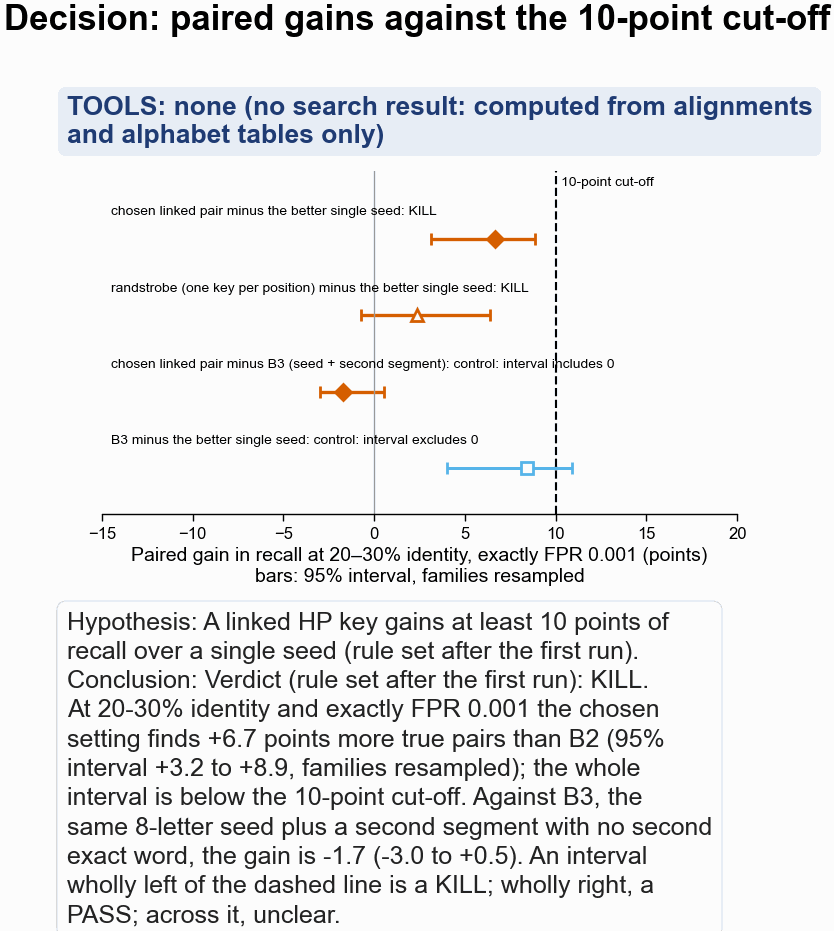

In [7]:
# decision figure: paired gains against the 10-point line
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 58, layout=None)
ys = np.arange(len(COMPARE))[::-1]
for y, (row, (a_, b_, lab, decides)) in zip(
    ys, zip(gains.iter_rows(named=True), COMPARE)
):
    col = COLOR["linked"] if a_ != "B3" else COLOR["B2"]
    mk = {"linked": "D", "randstrobe": "^", "B3": "s"}[a_]
    filled = a_ == "linked"
    ax.errorbar(
        100 * row["gain"],
        y,
        xerr=[
            [100 * (row["gain"] - row["ci_low"])],
            [100 * (row["ci_high"] - row["gain"])],
        ],
        color=col,
        marker=mk,
        ms=4,
        mfc=col if filled else "white",
        lw=1.2,
        capsize=2,
    )
    ax.text(
        -14.5, y + 0.28, f"{lab}: {row['call_vs_10_points']}", fontsize=5, va="bottom"
    )
ax.axvline(100 * DELTA, color="black", ls="--", lw=0.8)
ax.axvline(0, color="0.6", lw=0.5)
ax.text(100 * DELTA + 0.3, ys[0] + 0.75, "10-point cut-off", fontsize=5, va="center")
ax.set_xlim(-15, 20)
ax.set_ylim(-0.6, len(COMPARE) - 0.1)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlabel(
    "Paired gain in recall at 20–30% identity, exactly FPR 0.001 (points)\nbars: 95% interval, families resampled"
)
hc.finish_figure(
    fig,
    FIG / "294_decision_paired_gain_vs_10_points_pfam_seed.png",
    tools=hc.NO_TOOL,
    hypothesis="A linked HP key gains at least 10 points of recall over a single seed (rule set after the first run).",
    conclusion=verdict_line
    + " An interval wholly left of the dashed line is a KILL; wholly right, a PASS; across it, unclear.",
    title="Decision: paired gains against the 10-point cut-off",
    wrap=58,
)

### 4c. Against phmmer and MMseqs2 on the same pairs

[Notebook 233](233_extended_kmerseek_vs_aligners_on_pairs.ipynb) ran phmmer 3.4 (each pair
on its own, `-Z 20000`, so the E-value is what a proteome-sized database would give) and
MMseqs2 18 (`-s 7.5`, all 116,176 domain sequences against themselves) on these same 60,000
Pfam pairs. A pair is found by an aligner at E ≤ 0.01. The HP scores here use 232's threshold
(null rate at or below 0.001 per comparison), not the exact-FPR read-out of section 4b, so
they sit up to 2.4 points below the values there. The comparison favours the HP scores twice.
First, the HP scores are computed on Pfam's own curated alignment of each pair, while
phmmer and MMseqs2 have to find the alignment themselves. Second, the aligners' E-values
account for a whole database, the HP threshold only for one pair's own alignment, so the
HP threshold is the more lenient one. The two aligners are not held to the same cut-off
either: phmmer's E-values assume 20,000 sequences, MMseqs2's are computed against 116,176,
so MMseqs2's E ≤ 0.01 is about 5.8 times stricter. FoldSeek needs structures and was not
run on these Pfam sequences, so this notebook has no FoldSeek comparison.

report half: 30_000 true pairs; aligner rows missing (no hit at E <= 10, counted as not found): phmmer 3_762, MMseqs2 5_563
Share of true pairs found (%), HP scores at 232's threshold, aligners at E <= 0.01:
shape: (5, 8)
┌──────────────┬─────────┬──────┬──────┬────────┬────────────┬────────┬─────────┐
│ identity_bin ┆ n_pairs ┆ B2   ┆ B3   ┆ linked ┆ randstrobe ┆ phmmer ┆ MMseqs2 │
│ ---          ┆ ---     ┆ ---  ┆ ---  ┆ ---    ┆ ---        ┆ ---    ┆ ---     │
│ enum         ┆ u32     ┆ f64  ┆ f64  ┆ f64    ┆ f64        ┆ f64    ┆ f64     │
╞══════════════╪═════════╪══════╪══════╪════════╪════════════╪════════╪═════════╡
│ <20%         ┆ 3256    ┆ 12.8 ┆ 17.1 ┆ 15.3   ┆ 14.6       ┆ 18.8   ┆ 8.4     │
│ 20-30%       ┆ 7512    ┆ 37.9 ┆ 46.2 ┆ 43.5   ┆ 40.0       ┆ 75.4   ┆ 55.2    │
│ 30-40%       ┆ 7024    ┆ 65.4 ┆ 73.1 ┆ 70.6   ┆ 66.5       ┆ 98.0   ┆ 91.9    │
│ 40-60%       ┆ 8549    ┆ 89.1 ┆ 92.2 ┆ 91.3   ┆ 88.7       ┆ 99.9   ┆ 99.4    │
│ >=60%        ┆ 3659    ┆ 98.6 ┆ 99.1 ┆

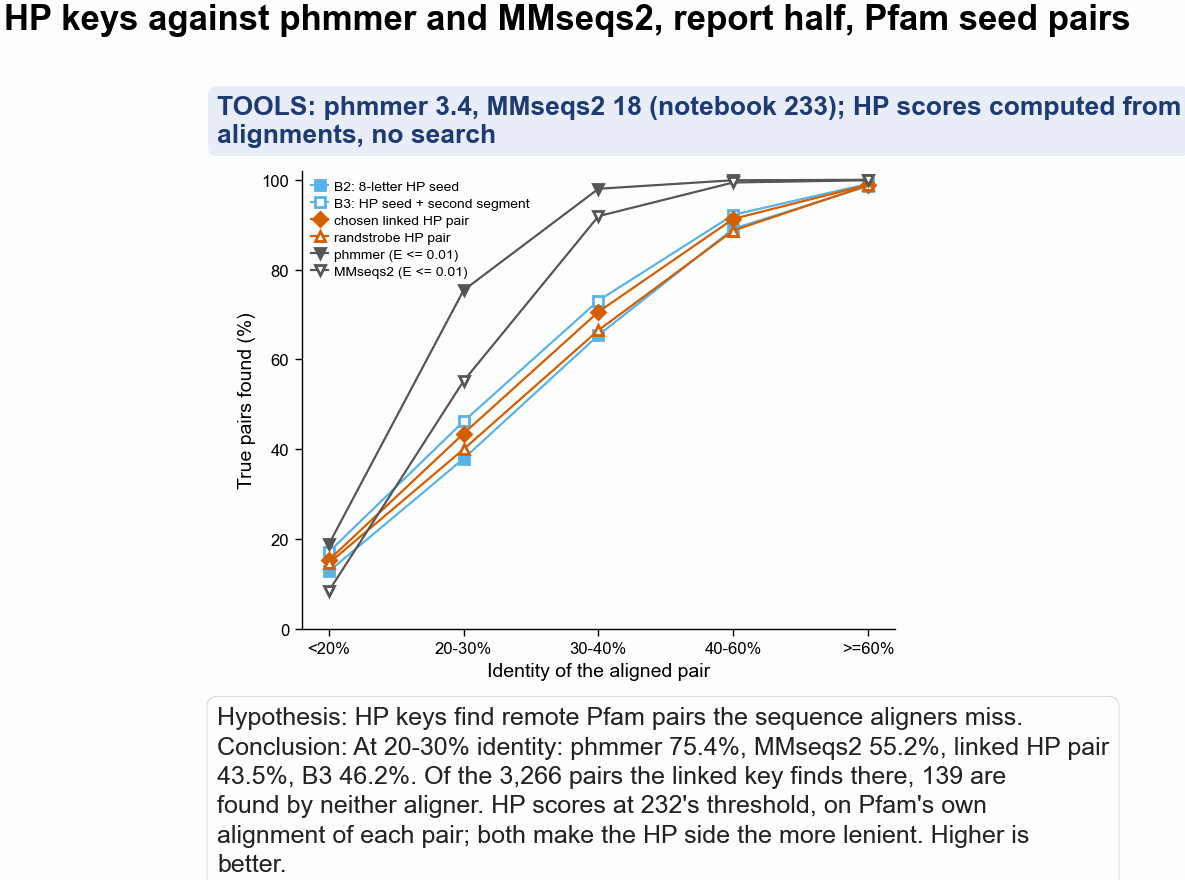

In [8]:
AL = Path("/Users/olga/data/pfam/233_aligner_check/233_aligner_pair_evalues.parquet")
E_CUT = 0.01
al = (
    pl.read_parquet(AL)
    .filter(pl.col("dataset") == "pfam")
    .select("query", "target", "phmmer_evalue", "mmseqs_evalue")
)
cmp_cols = {
    "B2": "B2_ext",
    "B3": "B3_ext",
    "linked": f"{CHOSEN}_ext",
    "randstrobe": f"{CHOSEN_RAND}_ext",
}
rep_pairs = d.filter(
    (pl.col("kind") == "real") & pl.col("pair_index").is_in(pidx_all[rep].tolist())
)
thr_c = {n: thr_r[EXT.index(c)] if c in EXT else None for n, c in cmp_cols.items()}
thr_c["B3"] = thr_n[JN["B3"]]
found = (
    rep_pairs.join(al, on=["query", "target"], how="left")
    .with_columns(
        *[(pl.col(c) > thr_c[n]).alias(n) for n, c in cmp_cols.items()],
        (pl.col("phmmer_evalue") <= E_CUT).fill_null(False).alias("phmmer"),
        (pl.col("mmseqs_evalue") <= E_CUT).fill_null(False).alias("MMseqs2"),
    )
    .with_columns((pl.col("phmmer") | pl.col("MMseqs2")).alias("phmmer or MMseqs2"))
)
SHOWN = ["B2", "B3", "linked", "randstrobe", "phmmer", "MMseqs2"]
tab_c = (
    found.group_by("identity_bin")
    .agg(
        pl.len().alias("n_pairs"),
        *[(100 * pl.col(c).mean()).round(1).alias(c) for c in SHOWN],
    )
    .sort("identity_bin")
)
print(
    f"report half: {found.height:_} true pairs; aligner rows missing (no hit at E <= 10, counted as not found): "
    f"phmmer {found['phmmer_evalue'].is_null().sum():_}, MMseqs2 {found['mmseqs_evalue'].is_null().sum():_}"
)
print(
    "Share of true pairs found (%), HP scores at 232's threshold, aligners at E <= 0.01:"
)
print(tab_c)
b23 = found.filter(pl.col("identity_bin") == "20-30%")
only = pl.DataFrame(
    [
        {
            "HP score": n,
            "found": int(b23[n].sum()),
            "found by neither phmmer nor MMseqs2": int(
                (b23[n] & ~b23["phmmer or MMseqs2"]).sum()
            ),
            "found, MMseqs2 not": int((b23[n] & ~b23["MMseqs2"]).sum()),
        }
        for n in ["B2", "B3", "linked", "randstrobe"]
    ]
)
print(f"20-30% identity, {b23.height:_} pairs:")
print(only)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70, layout=None)
x = np.arange(len(BINS))
sty = {
    "B2": (COLOR["B2"], "s", True),
    "B3": (COLOR["B2"], "s", False),
    "linked": (COLOR["linked"], "D", True),
    "randstrobe": (COLOR["linked"], "^", False),
    "phmmer": ("#555555", "v", True),
    "MMseqs2": ("#555555", "v", False),
}
lab = {
    "B2": "B2: 8-letter HP seed",
    "B3": "B3: HP seed + second segment",
    "linked": "chosen linked HP pair",
    "randstrobe": "randstrobe HP pair",
    "phmmer": "phmmer (E <= 0.01)",
    "MMseqs2": "MMseqs2 (E <= 0.01)",
}
for n, (col, mk, filled) in sty.items():
    ax.plot(
        x,
        tab_c[n],
        color=col,
        marker=mk,
        ms=3.5,
        mfc=col if filled else "white",
        lw=0.8,
        label=lab[n],
    )
ax.set_xticks(x, BINS)
ax.set_xlabel("Identity of the aligned pair")
ax.set_ylabel("True pairs found (%)")
ax.set_ylim(0, 102)
ax.legend(loc="upper left", fontsize=5)
lk = only.filter(pl.col("HP score") == "linked").row(0, named=True)
hc.finish_figure(
    fig,
    FIG / "294_hp_keys_vs_phmmer_mmseqs2_pfam_seed.png",
    tools="phmmer 3.4, MMseqs2 18 (notebook 233); HP scores computed from alignments, no search",
    hypothesis="HP keys find remote Pfam pairs the sequence aligners miss.",
    conclusion=(
        f"At 20-30% identity: phmmer {tab_c.filter(pl.col('identity_bin') == '20-30%')['phmmer'][0]:.1f}%, MMseqs2 {tab_c.filter(pl.col('identity_bin') == '20-30%')['MMseqs2'][0]:.1f}%, "
        f"linked HP pair {tab_c.filter(pl.col('identity_bin') == '20-30%')['linked'][0]:.1f}%, B3 {tab_c.filter(pl.col('identity_bin') == '20-30%')['B3'][0]:.1f}%. "
        f"Of the {lk['found']:,} pairs the linked key finds there, {lk['found by neither phmmer nor MMseqs2']} are found by neither aligner. HP scores at 232's threshold, on Pfam's own alignment of each pair; both make the HP side the more lenient. Higher is better."
    ),
    title="HP keys against phmmer and MMseqs2, report half, Pfam seed pairs",
    wrap=75,
)

### 4d. Key designs compared at their chance cost (added 2026-10-17)

The chosen key (every pair of 6-letter HP words up to 32 residues apart, gap not stored)
gives 3,896 chance key matches between two unrelated 131-residue proteins, against 70 for
B2's 8-letter word (section 5). The recall in sections 4a and 4b is scored on each pair's
own alignment, so a chance key match anywhere else on the two proteins is never paid for:
a key that matches by chance more often costs nothing there. This section puts every key
design next to its chance cost, and tests keys that store the gap.

**Designs.** All use the `hp_thomas_dill2` alphabet and the extension above (+1 per
matching HP class, −2 per mismatch, a gap column stops it).

1. *Gap stored exactly*: two a-letter words up to 32 residues apart; the key is (first
   word, gap, second word) and two keys match only when all three agree. a = 6, 7, 8.
2. *Gap in 7-residue bins*: the same, but the key stores which bin the gap falls in. The
   gap counts the residues between the two words, from 0 (the words touch) to 32, so the
   bins are 0–6, 7–13, 14–20, 21–27 and 28–32. (The brief listed them as 1–7 … 29–32,
   counting from 1.) Two gaps in one bin differ by at most 6 residues, so the key matches
   across an insertion or deletion of up to 6 residues between the words, unless the two
   gaps fall either side of a bin edge. a = 6, 7, 8.
3. *One word*: one k-letter seed with extension, k = 8, 10, 12, 14, 16. k = 8 is B2 and
   k = 10 is B1.
4. *Gap not stored*: the chosen key, and the randstrobe (one partner per position) of
   section 4b, copied unchanged.

*Chance key matches*: the expected number of key matches between two unrelated
131-residue proteins, over every pair of positions, from key frequencies counted on
Swiss-Prot (`scripts/linked_pairs_key_spectrum.py --cost-out`, the same count section 5
makes). Lower is cheaper.

**Rule, fixed before any number in this section was computed** (task brief, 2026-10-17).
The chance costs of the gap-stored keys were already printed in section 5 when it was
written.

- *Statistic*: the paired gain in recall at 20–30% identity over B2, on the report half,
  at exactly FPR 0.001 (read off the line between the two thresholds either side), with
  1,000 bootstrap resamples of whole Pfam families: the same resamples as section 4b.
- *Cheaper than B2*: chance key matches counted on Swiss-Prot at or below 70. *Costlier*:
  above 70. B2 itself is the reference and is not a candidate.
- PASS: a design cheaper than B2 whose whole 95% interval is at or above +10 points.
- KILL: every design cheaper than B2 has its whole 95% interval below +10 points.
- Anything else: unclear.
- A costlier design cannot PASS, whatever its recall: its extra recall could be bought
  with chance matches that the per-pair null never charges for.

In [9]:
D4_SCORES = Path(
    "/Users/olga/data/pfam/294_gap_designs_scores.parquet"
)  # scripts/linked_pairs_on_alignments.py --designs
D4_COST = Path(
    "/Users/olga/data/pfam/294_key_cost_by_design.parquet"
)  # scripts/linked_pairs_key_spectrum.py --cost-out
assert (CHOSEN, CHOSEN_RAND) == (
    "all_a6_g32_none",
    "rand_a6_g32_none",
), "lp.DESIGNS lists these two by name"
d4_new = pl.read_parquet(D4_SCORES).drop(
    "family", "query", "target", "seqid_ali", "q_len", "t_len"
)
d4 = d.join(d4_new, on=["pair_index", "kind"], how="inner", suffix="_4d")
assert d4.height == d.height == 180_000
d4_checks = {
    "one 8-letter word = B2": (d4["word8_ext"] == d4["B2_ext"]).all(),
    "one 10-letter word = B1": (d4["word10_ext"] == d4["B1_ext"]).all(),
    "longest run >= 8 exactly when an 8-letter seed is shared": (
        (d4["longest_run"] >= 8) == (d4["seed8_count"] > 0)
    ).all(),
    "longest run >= 10 exactly when a 10-letter seed is shared": (
        (d4["longest_run"] >= 10) == (d4["seed10_count"] > 0)
    ).all(),
}
for a_ in lp.DESIGN_ANCHORS:
    nm = lp.setting_name("all", a_, lp.DESIGN_GAP_MAX, "exact")
    d4_checks[f"gap stored exactly, {a_}-letter words, rescored = stored"] = (
        d4[f"{nm}_ext"] == d4[f"{nm}_ext_4d"]
    ).all() and (d4[f"{nm}_count"] == d4[f"{nm}_count_4d"]).all()
print("rescored on all 180,000 comparisons with lp.score_pair_designs (same shuffles):")
for k_, v_ in d4_checks.items():
    print(f"  {k_}: {v_}")
assert all(d4_checks.values())


def d4_label(design):
    m, ln, g_, tr = design
    if m == "word":
        return f"one {ln}-letter word" + {8: " (B2)", 10: " (B1)"}.get(ln, "")
    if m == "rand":
        return f"two {ln}-letter words, one partner per position (randstrobe)"
    rule = {
        "exact": "gap stored exactly",
        "binned7": "gap in 7-residue bins",
        "none": "gap not stored (chosen key)",
    }[tr]
    return f"two {ln}-letter words, {rule}"


def d4_family(design):
    m, _, _, tr = design
    return {"word": "one word", "rand": "randstrobe"}.get(m) or {
        "exact": "gap stored exactly",
        "binned7": "gap in 7-residue bins",
        "none": "gap not stored",
    }[tr]


D4_COL = {}
for des in lp.DESIGNS:
    nm = lp.design_name(*des)
    D4_COL[nm] = {"word8": "B2_ext", "word10": "B1_ext"}.get(nm, f"{nm}_ext")
d4_names = list(D4_COL)
real4, null4, bin4, pidx4 = lp.score_arrays(d4, list(D4_COL.values()))
assert (pidx4 == pidx_all).all()
rep4 = ~np.isin(pidx4, select_ids)
assert (rep4 == rep).all()
thr4, w4, rec4 = lp.recall_at_exact_fpr(real4[rep4], null4[rep4], bin4[rep4], FPR)
boot4 = lp.bootstrap_recall_by_group(
    real4[rep4], null4[rep4], bin4[rep4], fam_r, FPR, N_BOOT, seed=2
)
lo4, hi4 = np.percentile(boot4, 2.5, axis=0), np.percentile(boot4, 97.5, axis=0)
# the four scores section 4b also reports must come out the same, resample for resample
same4b = all(
    np.array_equal(boot4[:, :, d4_names.index(n4)], boot_n[:, :, JN[n4b]])
    and np.array_equal(rec4[:, d4_names.index(n4)], rec_n[:, JN[n4b]])
    for n4, n4b in [
        ("word8", "B2"),
        ("word10", "B1"),
        (CHOSEN, "linked"),
        (CHOSEN_RAND, "randstrobe"),
    ]
)
print(
    f"B2, B1, the chosen key and the randstrobe give section 4b's recall and bootstrap resamples exactly: {same4b}"
)
assert same4b

cost4 = pl.read_parquet(D4_COST)
L_MED_4D = cost4["median_length"][0]
assert cost4["design"].to_list() == d4_names
spec4 = pl.read_parquet(SPECTRUM)
cross = []
for des in lp.DESIGNS:
    m, ln, g_, tr = des
    sel = (
        (pl.col("mode") == m)
        & (pl.col("anchor") == ln)
        & (pl.col("gap_max") == g_)
        & (pl.col("treatment") == tr)
    )
    if m == "word":
        sel = (pl.col("mode") == "word") & (pl.col("anchor") == ln)
    old = spec4.filter(sel)
    if old.height:
        new_ = cost4.filter(pl.col("design") == lp.design_name(*des))["chance_matches"][
            0
        ]
        cross.append((lp.design_name(*des), old["expected_chance_matches"][0], new_))
max_rel = max(abs(n_ - o_) / o_ for _, o_, n_ in cross)
print(
    f"{len(cross)} designs are also in section 5's table; largest relative difference between the two counts: {max_rel:.1e}"
)
assert max_rel < 1e-9

j_b2 = d4_names.index("word8")
B2_COST = cost4.filter(pl.col("design") == "word8")["chance_matches"][0]
CHEAP_MAX = 70.0
rows4 = []
for i, des in enumerate(lp.DESIGNS):
    nm = d4_names[i]
    gain_b = boot4[:, b2030, i] - boot4[:, b2030, j_b2]
    g_lo, g_hi = np.percentile(gain_b, [2.5, 97.5])
    cm = cost4.filter(pl.col("design") == nm)["chance_matches"][0]
    if nm == "word8":
        cls_, call_ = "reference", "reference"
    elif cm <= CHEAP_MAX:
        cls_ = "cheaper"
        call_ = "PASS" if g_lo >= DELTA else ("KILL" if g_hi < DELTA else "UNCLEAR")
    else:
        cls_, call_ = "costlier", "cannot PASS"
    rows4.append(
        {
            "design": d4_label(des),
            "family": d4_family(des),
            "name": nm,
            "chance_matches": cm,
            "recall": rec4[b2030, i],
            "recall_lo": lo4[b2030, i],
            "recall_hi": hi4[b2030, i],
            "gain": rec4[b2030, i] - rec4[b2030, j_b2],
            "gain_lo": g_lo,
            "gain_hi": g_hi,
            "cost_vs_B2": cls_,
            "verdict": call_,
        }
    )
t4 = pl.DataFrame(rows4).sort(["chance_matches", "name"])
near = t4.filter(
    (pl.col("chance_matches") > CHEAP_MAX)
    & (pl.col("chance_matches") <= B2_COST)
    & (pl.col("name") != "word8")
)
print(
    f"B2's own count is {B2_COST:.1f}; designs between 70 and {B2_COST:.1f}, where the rule's 70 and B2's own count would disagree: {near.height}"
)
print(
    "Report half, 20-30% identity, exactly FPR 0.001, 95% intervals with Pfam families resampled; sorted by chance matches:"
)
with pl.Config(
    fmt_str_lengths=80, tbl_width_chars=260
):  # only for this table: long design names
    print(
        t4.select(
            pl.col("design"),
            pl.col("chance_matches")
            .round(1)
            .alias("chance matches counted on Swiss-Prot"),
            pl.format(
                "{} [{} to {}]",
                *[
                    (100 * pl.col(c)).round(1)
                    for c in ["recall", "recall_lo", "recall_hi"]
                ],
            ).alias("recall at 20-30% (%)"),
            pl.format(
                "{} [{} to {}]",
                *[(100 * pl.col(c)).round(1) for c in ["gain", "gain_lo", "gain_hi"]],
            ).alias("gain over B2 (points)"),
            pl.col("cost_vs_B2").alias("cost vs B2"),
            pl.col("verdict"),
        )
    )
cheap4 = t4.filter(pl.col("cost_vs_B2") == "cheaper")
if (cheap4["verdict"] == "PASS").any():
    VERDICT_4D = "PASS"
elif (cheap4["verdict"] == "KILL").all():
    VERDICT_4D = "KILL"
else:
    VERDICT_4D = "UNCLEAR"
best_cheap = cheap4.sort(["gain", "name"], descending=[True, False]).row(0, named=True)
best_any = (
    t4.filter(pl.col("name") != "word8")
    .sort(["gain", "name"], descending=[True, False])
    .row(0, named=True)
)
verdict_4d_line = (
    f"Section 4d verdict: {VERDICT_4D}. {cheap4.height} designs are cheaper than B2; the best of them, {best_cheap['design']}, "
    f"gains {100 * best_cheap['gain']:+.1f} points over B2 (95% interval {100 * best_cheap['gain_lo']:+.1f} to {100 * best_cheap['gain_hi']:+.1f}) "
    f"at {best_cheap['chance_matches']:.1f} chance matches. The largest gain of any design, {100 * best_any['gain']:+.1f} "
    f"({100 * best_any['gain_lo']:+.1f} to {100 * best_any['gain_hi']:+.1f}), is {best_any['design']}, at {best_any['chance_matches']:,.0f} chance matches."
)
print(verdict_4d_line)

rescored on all 180,000 comparisons with lp.score_pair_designs (same shuffles):
  one 8-letter word = B2: True
  one 10-letter word = B1: True
  longest run >= 8 exactly when an 8-letter seed is shared: True
  longest run >= 10 exactly when a 10-letter seed is shared: True
  gap stored exactly, 6-letter words, rescored = stored: True
  gap stored exactly, 7-letter words, rescored = stored: True
  gap stored exactly, 8-letter words, rescored = stored: True


B2, B1, the chosen key and the randstrobe give section 4b's recall and bootstrap resamples exactly: True
7 designs are also in section 5's table; largest relative difference between the two counts: 0.0e+00
B2's own count is 70.4; designs between 70 and 70.4, where the rule's 70 and B2's own count would disagree: 0
Report half, 20-30% identity, exactly FPR 0.001, 95% intervals with Pfam families resampled; sorted by chance matches:
shape: (13, 6)
┌───────────────────────────────────────────────────────────┬──────────────────────────────────────┬──────────────────────┬────────────────────────┬────────────┬─────────────┐
│ design                                                    ┆ chance matches counted on Swiss-Prot ┆ recall at 20-30% (%) ┆ gain over B2 (points)  ┆ cost vs B2 ┆ verdict     │
│ ---                                                       ┆ ---                                  ┆ ---                  ┆ ---                    ┆ ---        ┆ ---         │
│ str                 

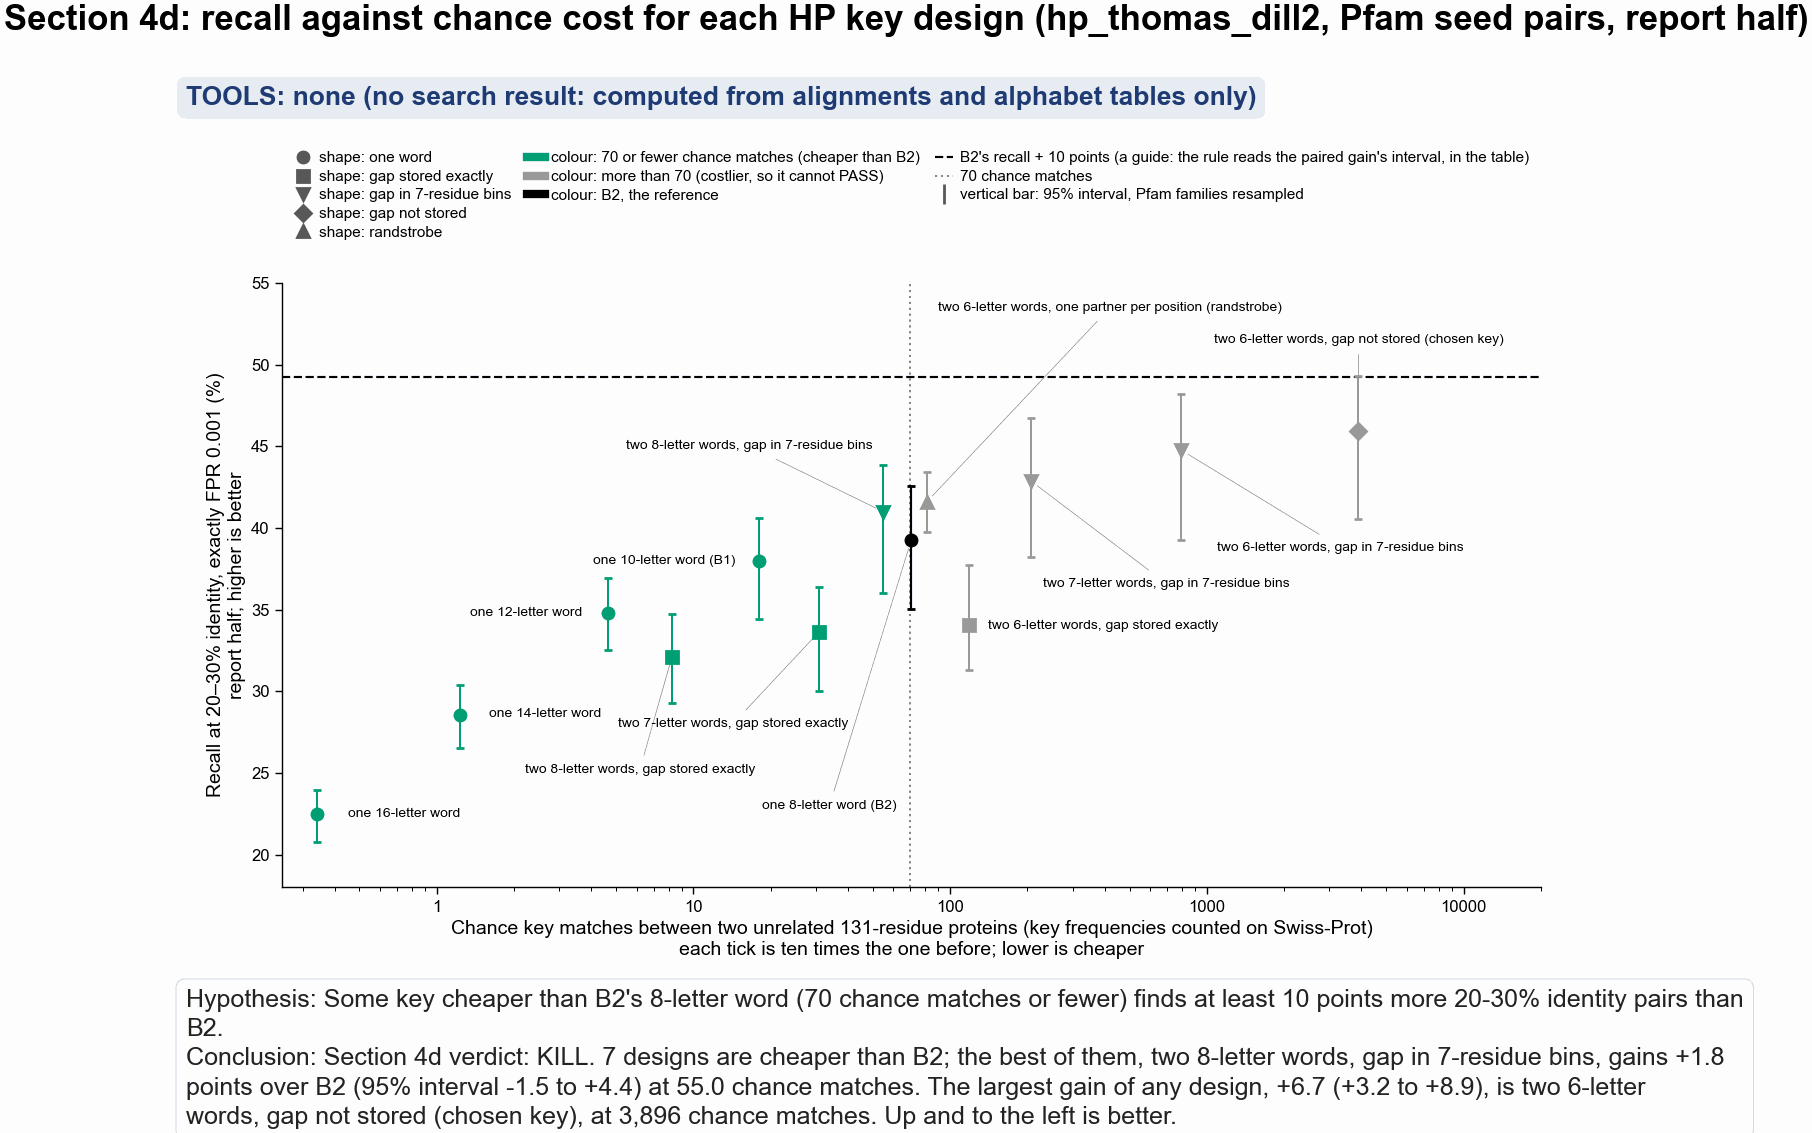

In [10]:
# recall at 20-30% identity against chance cost, one mark per design
# where each point's label sits (data coordinates) and its alignment; a label away from
# its point gets a thin grey line to it
D4_LABEL_POS = {
    "word16": (0.45, 22.5, "left"),
    "word14": (1.6, 28.6, "left"),
    "word12": (3.7, 34.8, "right"),
    "word10": (14.5, 38.0, "right"),
    "all_a8_g32_exact": (2.2, 25.2, "left"),
    "all_a7_g32_exact": (40.0, 28.0, "right"),
    "all_a8_g32_binned7": (50.0, 45.0, "right"),
    "rand_a6_g32_none": (90.0, 53.5, "left"),
    "word8": (62.0, 23.0, "right"),
    "all_a6_g32_exact": (140.0, 34.0, "left"),
    "all_a7_g32_binned7": (230.0, 36.6, "left"),
    "all_a6_g32_binned7": (1100.0, 38.8, "left"),
    "all_a6_g32_none": (3896.0, 51.5, "center"),
}
from matplotlib.lines import Line2D

D4_SHAPE = {
    "one word": "o",
    "gap stored exactly": "s",
    "gap in 7-residue bins": "v",
    "gap not stored": "D",
    "randstrobe": "^",
}
D4_COLOUR = {
    "cheaper": pf.OKABE_ITO["bluish_green"],
    "costlier": "#999999",
    "reference": "black",
}
fig, axd = plt.subplot_mosaic(
    [["legend"], ["main"]],
    figsize=(pf.TWO_COLUMN_MM * pf.MM, 110 * pf.MM),
    height_ratios=[0.2, 1],
)
blank = Line2D([], [], lw=0, label=" ")
h4 = [
    Line2D([], [], color="0.35", marker=mk, lw=0, ms=4, label=f"shape: {fam}")
    for fam, mk in D4_SHAPE.items()
] + [
    Line2D(
        [],
        [],
        color=D4_COLOUR["cheaper"],
        lw=3,
        label="colour: 70 or fewer chance matches (cheaper than B2)",
    ),
    Line2D(
        [],
        [],
        color=D4_COLOUR["costlier"],
        lw=3,
        label="colour: more than 70 (costlier, so it cannot PASS)",
    ),
    Line2D(
        [], [], color=D4_COLOUR["reference"], lw=3, label="colour: B2, the reference"
    ),
    blank,
    blank,
    Line2D(
        [],
        [],
        color="black",
        ls="--",
        lw=0.8,
        label="B2's recall + 10 points (a guide: the rule reads the paired gain's interval, in the table)",
    ),
    Line2D([], [], color="0.5", ls=":", lw=0.8, label="70 chance matches"),
    Line2D(
        [],
        [],
        color="0.35",
        marker="|",
        ms=7,
        lw=0,
        label="vertical bar: 95% interval, Pfam families resampled",
    ),
    blank,
    blank,
]
axd["legend"].set_axis_off()
axd["legend"].legend(handles=h4, loc="center", ncol=3, fontsize=5.5, frameon=False)
ax = axd["main"]
for r_ in t4.iter_rows(named=True):
    col = D4_COLOUR[r_["cost_vs_B2"]]
    ax.errorbar(
        r_["chance_matches"],
        100 * r_["recall"],
        yerr=[
            [100 * (r_["recall"] - r_["recall_lo"])],
            [100 * (r_["recall_hi"] - r_["recall"])],
        ],
        color=col,
        marker=D4_SHAPE[r_["family"]],
        ms=4,
        mfc=col,
        lw=0.8,
        capsize=1.5,
        zorder=3,
    )
b2_rec = t4.filter(pl.col("name") == "word8")["recall"][0]
ax.axhline(100 * (b2_rec + DELTA), color="black", ls="--", lw=0.8)
ax.axvline(CHEAP_MAX, color="0.5", ls=":", lw=0.8)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel(
    f"Chance key matches between two unrelated {L_MED_4D:.0f}-residue proteins (key frequencies counted on Swiss-Prot)\n"
    "each tick is ten times the one before; lower is cheaper"
)
ax.set_ylabel(
    "Recall at 20–30% identity, exactly FPR 0.001 (%)\nreport half; higher is better"
)
ax.set_xlim(0.25, 2e4)
ax.set_ylim(18, 55)
for r_ in t4.iter_rows(named=True):
    tx, ty, ha = D4_LABEL_POS[r_["name"]]
    near_point = abs(ty - 100 * r_["recall"]) < 0.5
    ax.annotate(
        r_["design"],
        (r_["chance_matches"], 100 * r_["recall"]),
        xytext=(tx, ty),
        textcoords="data",
        fontsize=5,
        ha=ha,
        va="center",
        color="black",
        arrowprops=(
            None
            if near_point
            else dict(arrowstyle="-", lw=0.3, color="0.6", shrinkA=1, shrinkB=3)
        ),
    )
hc.finish_figure(
    fig,
    FIG / "294_recall_vs_chance_cost.png",
    tools=hc.NO_TOOL,
    title="Section 4d: recall against chance cost for each HP key design (hp_thomas_dill2, Pfam seed pairs, report half)",
    hypothesis="Some key cheaper than B2's 8-letter word (70 chance matches or fewer) finds at least 10 points more 20-30% identity pairs than B2.",
    conclusion=verdict_4d_line + " Up and to the left is better.",
    wrap=140,
)

report half, 20-30% identity, 7_512 true pairs; one k-letter word with extension:
shape: (5, 6)
┌─────┬────────────────┬────────────┬────────┬─────────┬─────────────────────────────────┐
│ k   ┆ chance_matches ┆ recall (%) ┆ ci_low ┆ ci_high ┆ share of 20-30% pairs with an … │
│ --- ┆ ---            ┆ ---        ┆ ---    ┆ ---     ┆ ---                             │
│ i64 ┆ f64            ┆ f64        ┆ f64    ┆ f64     ┆ f64                             │
╞═════╪════════════════╪════════════╪════════╪═════════╪═════════════════════════════════╡
│ 8   ┆ 70.433637      ┆ 39.2       ┆ 35.0   ┆ 42.6    ┆ 92.6                            │
│ 10  ┆ 17.94188       ┆ 38.0       ┆ 34.4   ┆ 40.6    ┆ 77.5                            │
│ 12  ┆ 4.636015       ┆ 34.8       ┆ 32.5   ┆ 36.9    ┆ 56.6                            │
│ 14  ┆ 1.230058       ┆ 28.6       ┆ 26.6   ┆ 30.4    ┆ 37.8                            │
│ 16  ┆ 0.342429       ┆ 22.5       ┆ 20.8   ┆ 23.9    ┆ 24.4                        

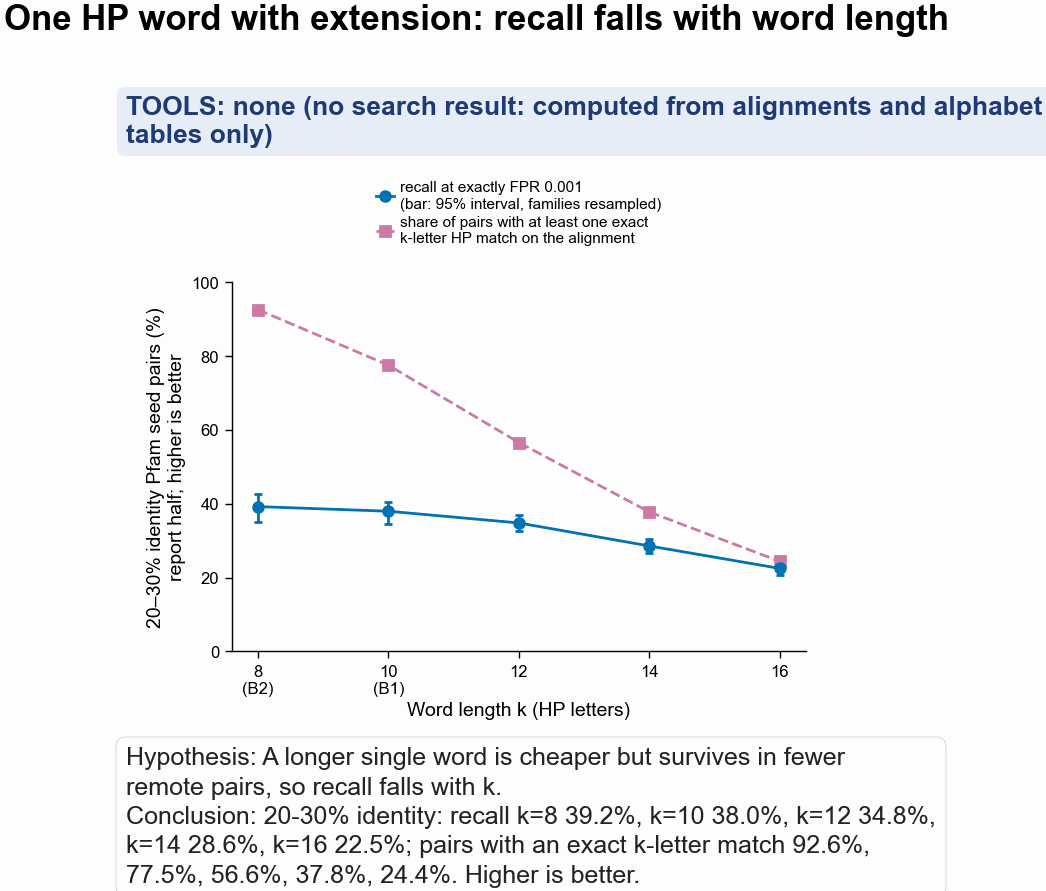

In [11]:
# k-size slope of one exact word with extension
words4 = (
    t4.filter(pl.col("family") == "one word")
    .with_columns(pl.col("name").str.slice(4).cast(int).alias("k"))
    .sort("k")
)
lr_rep = (
    d4.filter(pl.col("kind") == "real")
    .sort("pair_index")["longest_run"]
    .to_numpy()[rep4]
)
in2030 = bin4[rep4] == b2030
share_k = {k: float((lr_rep[in2030] >= k).mean()) for k in lp.SINGLE_WORDS}
slope = words4.select(
    "k",
    "chance_matches",
    (100 * pl.col("recall")).round(1).alias("recall (%)"),
    (100 * pl.col("recall_lo")).round(1).alias("ci_low"),
    (100 * pl.col("recall_hi")).round(1).alias("ci_high"),
).with_columns(
    pl.Series(
        "share of 20-30% pairs with an exact k-letter match (%)",
        [round(100 * share_k[k], 1) for k in words4["k"]],
    )
)
print(
    f"report half, 20-30% identity, {int(in2030.sum()):_} true pairs; one k-letter word with extension:"
)
print(slope)
fig, axd = plt.subplot_mosaic(
    [["legend"], ["main"]],
    figsize=(pf.ONE_COLUMN_MM * pf.MM, 75 * pf.MM),
    height_ratios=[0.22, 1],
)
C_REC, C_SHARE = pf.OKABE_ITO["blue"], pf.OKABE_ITO["reddish_purple"]
axd["legend"].set_axis_off()
axd["legend"].legend(
    handles=[
        Line2D(
            [],
            [],
            color=C_REC,
            marker="o",
            ms=3.5,
            lw=1,
            label="recall at exactly FPR 0.001\n(bar: 95% interval, families resampled)",
        ),
        Line2D(
            [],
            [],
            color=C_SHARE,
            marker="s",
            ms=3.5,
            lw=1,
            ls="--",
            label="share of pairs with at least one exact\nk-letter HP match on the alignment",
        ),
    ],
    loc="center",
    ncol=1,
    fontsize=5.5,
    frameon=False,
)
ax = axd["main"]
ks = words4["k"].to_numpy()
ax.errorbar(
    ks,
    100 * words4["recall"],
    yerr=[
        100 * (words4["recall"] - words4["recall_lo"]),
        100 * (words4["recall_hi"] - words4["recall"]),
    ],
    color=C_REC,
    marker="o",
    ms=3.5,
    lw=1,
    capsize=1.5,
)
ax.plot(
    ks, [100 * share_k[k] for k in ks], color=C_SHARE, marker="s", ms=3.5, lw=1, ls="--"
)
ax.set_xticks(
    ks, [f"{k}\n(B2)" if k == 8 else (f"{k}\n(B1)" if k == 10 else f"{k}") for k in ks]
)
ax.set_xlabel("Word length k (HP letters)")
ax.set_ylabel("20–30% identity Pfam seed pairs (%)\nreport half; higher is better")
ax.set_ylim(0, 100)
hc.finish_figure(
    fig,
    FIG / "294_single_word_ksize_slope.png",
    tools=hc.NO_TOOL,
    title="One HP word with extension: recall falls with word length",
    hypothesis="A longer single word is cheaper but survives in fewer remote pairs, so recall falls with k.",
    conclusion=(
        f"20-30% identity: recall "
        + ", ".join(f"k={k} {100 * r:.1f}%" for k, r in zip(ks, words4["recall"]))
        + "; pairs with an exact k-letter match "
        + ", ".join(f"{100 * share_k[k]:.1f}%" for k in ks)
        + ". Higher is better."
    ),
    wrap=70,
)

**Model check.** How far is each measured count from what independent HP letters would
give? The model treats every letter of two unrelated proteins as drawn on its own from the
Swiss-Prot class shares. Section 4a does not print those shares, so the next cell counts
them from `uniprot_sprot.fasta.gz`. The model's numbers are a prediction, kept in their own
table and never mixed with the counts.

$$\text{Pr}(\text{agree}) = h^2 + p^2$$

$$\text{Pr}(\text{key match}) = \text{Pr}(\text{agree})^{n_\text{letters}} \times \text{Pr}(\text{gaps agree})$$

$$\mu_\text{model} = n_\text{keys}^2 \times \text{Pr}(\text{key match})$$

where

- $h$: share of Swiss-Prot residues that are hydrophobic (`ACFILMVWY`);
- $p$: share that are polar (`DEGHKNPQRST`); $h + p = 1$, other letters are left out;
- $\text{Pr}(\text{agree})$: chance that two letters drawn at random have the same HP class;
- $n_\text{letters}$: letters in the key, $k$ for one word and $2a$ for two $a$-letter words;
- $\text{Pr}(\text{gaps agree})$: chance that the two keys' gaps agree under the gap rule,
  with every gap 0 to $G$ taken as equally likely: 1 for one word, for a gap not stored and
  for the randstrobe; $1 / (G + 1)$ for a gap stored exactly; $\sum_b (n_b / (G + 1))^2$
  for a gap in bins;
- $G = 32$: the largest gap;
- $n_b$: the number of gap values in bin $b$ (7, 7, 7, 7 and 5);
- $n_\text{keys}$: the number of keys one 131-residue protein holds, the same number the
  counted column uses;
- $\mu_\text{model}$: the predicted chance matches between two unrelated 131-residue
  proteins.

In [12]:
import gzip
from collections import Counter

aa_counts = Counter()
with gzip.open(SPROT_FASTA, "rb") as fh:
    for ln in fh:
        if not ln.startswith(b">"):
            aa_counts.update(ln.strip())
n_h = sum(aa_counts[ord(c)] for c in "ACFILMVWY")
n_p = sum(aa_counts[ord(c)] for c in "DEGHKNPQRST")
h_sp, p_sp = n_h / (n_h + n_p), n_p / (n_h + n_p)
pr_agree = h_sp**2 + p_sp**2
print(
    f"Swiss-Prot ({SPROT_FASTA.name}): {n_h:_} hydrophobic and {n_p:_} polar residues, "
    f"{sum(aa_counts.values()) - n_h - n_p:_} other letters left out"
)
print(
    f"h = {h_sp:.4f}, p = {p_sp:.4f}, Pr(agree) = h^2 + p^2 = {pr_agree:.4f}, so {-np.log2(pr_agree):.3f} bits per HP letter"
)
G4 = lp.DESIGN_GAP_MAX
n_b = np.bincount(np.arange(G4 + 1) // lp.GAP_BIN7)
print(f"gap values per 7-residue bin: {n_b.tolist()}")


def pr_gaps(tr):
    if tr == "exact":
        return 1 / (G4 + 1)
    if tr == "binned7":
        return float(((n_b / (G4 + 1)) ** 2).sum())
    return 1.0


model4 = []
for des, r_ in zip(lp.DESIGNS, cost4.iter_rows(named=True)):
    m, ln, g_, tr = des
    n_letters = ln if m == "word" else 2 * ln
    mu = r_["keys_per_sequence"] ** 2 * pr_agree**n_letters * pr_gaps(tr)
    model4.append(
        {
            "design": d4_label(des),
            "name": r_["design"],
            "chance matches counted on Swiss-Prot": r_["chance_matches"],
            "predicted chance matches (model)": mu,
        }
    )
model4 = (
    pl.DataFrame(model4)
    .with_columns(
        (
            pl.col("chance matches counted on Swiss-Prot")
            / pl.col("predicted chance matches (model)")
        ).alias("counted / predicted")
    )
    .sort(["chance matches counted on Swiss-Prot", "name"])
)
print("Model check (prediction, not a measurement):")
with pl.Config(fmt_str_lengths=80, tbl_width_chars=260):
    print(
        model4.drop("name").with_columns(
            pl.col(
                "chance matches counted on Swiss-Prot",
                "predicted chance matches (model)",
            ).round(1),
            pl.col("counted / predicted").round(2),
        )
    )

Swiss-Prot (uniprot_sprot.fasta.gz): 87_969_604 hydrophobic and 119_643_283 polar residues, 8_930 other letters left out
h = 0.4237, p = 0.5763, Pr(agree) = h^2 + p^2 = 0.5116, so 0.967 bits per HP letter
gap values per 7-residue bin: [7, 7, 7, 7, 5]
Model check (prediction, not a measurement):
shape: (13, 4)
┌───────────────────────────────────────────────────────────┬──────────────────────────────────────┬──────────────────────────────────┬─────────────────────┐
│ design                                                    ┆ chance matches counted on Swiss-Prot ┆ predicted chance matches (model) ┆ counted / predicted │
│ ---                                                       ┆ ---                                  ┆ ---                              ┆ ---                 │
│ str                                                       ┆ f64                                  ┆ f64                              ┆ f64                 │
╞════════════════════════════════════════════════════════

**Verdict for 4d: KILL.** Seven designs give 70 or fewer chance matches, and none of them
comes near +10 points. The best, two 8-letter words with the gap in 7-residue bins, gains
+1.8 points over B2 (95% interval −1.5 to +4.4) at 55 chance matches. Storing the gap
exactly costs recall: two 8-letter words with the exact gap find 32.1% of 20–30% identity
pairs against B2's 39.2% (−7.1, interval −9.5 to −4.6), because an insertion or deletion
between the two words changes the gap and breaks the key. Bins of 7 residues bring the same
two 8-letter words back to 41.0%. Every design whose gain interval lies above 0 (the chosen
key +6.7, two 6-letter words with binned gap +5.5, two 7-letter words with binned gap +3.7)
costs 3 to 55 times B2's chance matches, so its gain could come from matches the per-pair
null never charges for. A longer single word is cheaper but finds fewer pairs: recall falls
from 39.2% at 8 letters to 22.5% at 16, as the share of 20–30% pairs with an exact
k-letter HP match falls from 92.6% to 24.4%. At or below B2's chance cost, no HP key tested
here finds more pairs than B2 with an interval that excludes 0. Independent letters predict every count to
within 1.0 to 1.3 times (the counts are always the higher), except the randstrobe's, which
is 18 times the prediction: its hash rule ties the second word to the first, so two keys
that share a first word often share the whole key (section 5).

**Changes since 4b**

- No number printed in sections 1 to 4c, 5 or 6 moved. The notebook's text output before
  and after 4d was added was compared line by line; only 4d's lines and one new summary
  line in section 6 are new.
- The B2, B1, chosen-key and randstrobe rows of the 4d table are section 4b's numbers: the
  same score columns and the same 1,000 family resamples (seed 2), checked equal resample
  by resample in the first 4d cell.
- The gap-stored keys were rescored with the new `score_pair_designs` and equal the stored
  scores on all 180,000 comparisons. The chance counts of the seven designs that section 5
  also lists equal section 5's to the last digit.
- New code: `linked_pairs_utils.py` gains 7-residue gap bins (`binned7`) and
  `score_pair_designs`; `linked_pairs_on_alignments.py --designs` and
  `linked_pairs_key_spectrum.py --cost-out` write the two new parquet files. The 72 settings
  of sections 2 to 4b are unchanged.

### 4e. Two ceilings: how many pairs carry a seed, and how much the whole alignment can give (added 2026-10-17)

Section 4b's recall comes from a seed and its extension. Two upper bounds limit it, and
neither was measured above.

1. *The seed ceiling.* A seed design can only find a pair whose alignment holds at least one
   exact run of k matching HP classes. If few pairs hold one, no seed design can gain much,
   whatever it scores.
2. *The scoring ceiling.* Even a pair with a seed is missed when its extended score stays
   under the null threshold. If the whole alignment, scored with the best HP matrix, finds
   far more pairs than B3's 47.6%, the missing recall is lost in the scoring, not in the
   index.

**Part 1, the seed ceiling.** For each true pair of the report half and each k in 6, 8, 10,
12, 16 and 24, the pair *carries a k-run* when its alignment has at least k consecutive
columns whose two residues fall in the same HP class, with no gap and no X inside the run.
This is `longest_run >= k`, from the column section 4d stored. Beside each share is the
recall of one k-letter word with extension, from section 4d (k = 8 is B2, k = 10 is B1).
4d ran single words only for k = 8, 10, 12, 14 and 16, so k = 6 and 24 have no recall
beside them; that column is left empty. The share minus the recall is what the scoring step
loses among pairs that do carry a seed.

**Part 2, the scoring ceiling.** Each aligned column of a pair is scored by its two HP
classes, (query class, target class), with a 2×2 log-odds matrix:

$$s(a, b) = \log_2 \frac{\text{Pr}(a, b \mid \text{aligned in a true pair})}{\text{share}(a)\,\text{share}(b)}$$

where

- $a, b$: the HP class (H or P) of the query residue and of the target residue in one column;
- $\text{Pr}(a, b \mid \text{aligned in a true pair})$: the share of aligned columns with
  classes $a$ and $b$, pooled over the report half's true pairs at 20–30% identity. Columns
  with a gap or an X in either sequence are left out. HP and PH are averaged, so the score
  does not depend on which protein is the query;
- $\text{share}(a)$: the share of class $a$ over the same columns, both sequences pooled;
- $s(a, b)$ in bits: above 0 when the two classes are seen together in true pairs more often
  than chance would put them together.

Two scores per comparison, each made from this matrix:

- *Full-alignment score*: the sum of $s$ over every column of the alignment notebook 230
  gives. A gap or X column scores 0 and is skipped. This needs the whole alignment, so no
  search could reach it. It is the most that a score of each column on its own, by its two
  HP classes, can say about a pair on this alignment (a score that looks at neighbouring
  columns could say more).
- *Best-stretch score*: the highest sum over any run of consecutive columns with no gap or X
  inside (a Smith-Waterman on the fixed alignment, no gaps allowed, any start and end). An
  ungapped extension with this matrix from a seed that lands anywhere in the stretch would
  reach this score. Its null, like B2's and B3's, is scored on the one fixed alignment; a
  real search takes the best over every diagonal, which raises the threshold, so this
  recall is optimistic too.

The null is the same as in every other section: each pair's two shuffled targets, drawn by
`lp.comparison_joint_codes` from the same random generator in the same order as notebook
232. The next cell checks this by rescoring B2 from these shuffles. Recall is read at
exactly FPR 0.001, with 1,000 resamples of whole Pfam families (seed 2), as in section 4b.

*Caveat.* The matrix is fitted on the report half and then scores the same report half, so
the two ceilings are slightly optimistic. As a check, the full-alignment ceiling is also
given with the matrix fitted on the selection half.

Table 1. Report half, 30_000 true pairs. Share carrying a k-run (k consecutive aligned columns with matching HP classes, no gap or X inside), and recall of one k-letter word with extension at exactly FPR 0.001 (section 4d). k = 6 and 24: no single-word recall was computed, left empty. Sorted by k, then identity.
shape: (30, 6)
┌─────┬──────────────┬────────────┬────────────────────────┬───────────────────────────────┬─────────────────────────────┐
│ k   ┆ identity_bin ┆ true pairs ┆ share with a k-run (%) ┆ one k-letter word, recall (%) ┆ share minus recall (points) │
│ --- ┆ ---          ┆ ---        ┆ ---                    ┆ ---                           ┆ ---                         │
│ i64 ┆ str          ┆ i64        ┆ f64                    ┆ f64                           ┆ f64                         │
╞═════╪══════════════╪════════════╪════════════════════════╪═══════════════════════════════╪═════════════════════════════╡
│ 6   ┆ <20%         ┆ 3256       ┆ 97.5                

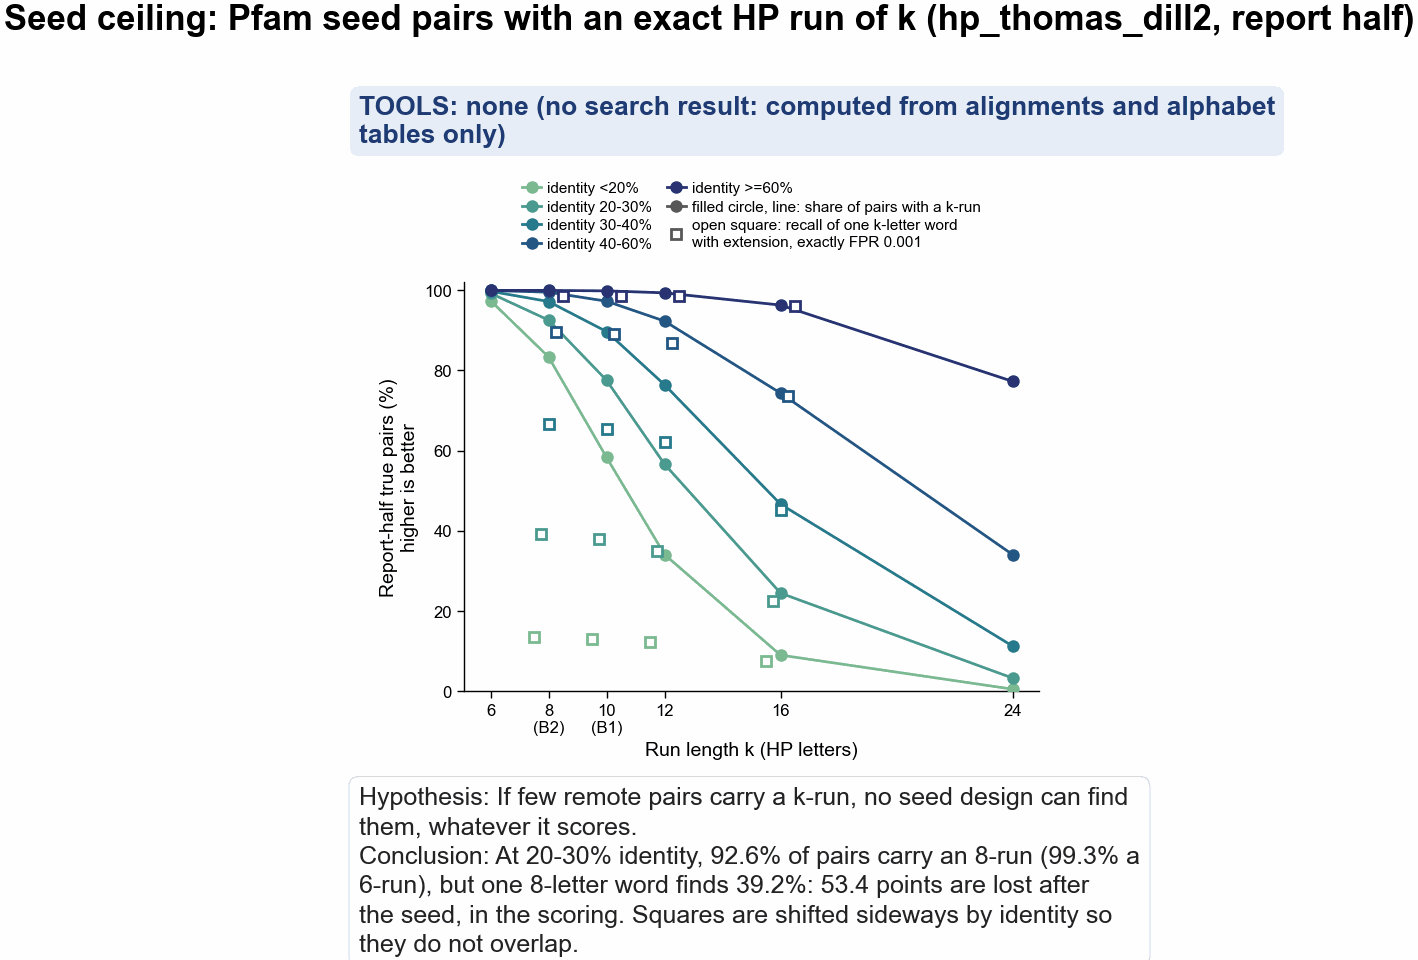

In [13]:
# Part 1: the seed ceiling
K_RUNS = [6, 8, 10, 12, 16, 24]
lr_real = (
    d4.filter(pl.col("kind") == "real").sort("pair_index")["longest_run"].to_numpy()
)
lr_r4e, bin_r4e = lr_real[rep4], bin4[rep4]
assert (bin_r4e == bin_r).all()
t1_rows = []
for k in K_RUNS:
    for i, b in enumerate(BINS):
        in_b = bin_r4e == i
        word = f"word{k}"
        t1_rows.append(
            {
                "k": k,
                "bin_order": i,
                "identity_bin": b,
                "n_pairs": int(in_b.sum()),
                "share": float((lr_r4e[in_b] >= k).mean()),
                "recall": (
                    float(rec4[i, d4_names.index(word)]) if word in d4_names else None
                ),
            }
        )
t1 = (
    pl.DataFrame(t1_rows)
    .sort("k", "bin_order")
    .with_columns((pl.col("share") - pl.col("recall")).alias("lost"))
)
for k in K_RUNS:  # 4d printed the same share at 20-30% identity for k = 8 to 16
    if k in share_k:
        assert (
            t1.filter((pl.col("k") == k) & (pl.col("identity_bin") == "20-30%"))[
                "share"
            ][0]
            == share_k[k]
        )
print(
    f"Table 1. Report half, {int(rep4.sum()):_} true pairs. Share carrying a k-run (k consecutive aligned columns with matching HP classes, "
    "no gap or X inside), and recall of one k-letter word with extension at exactly FPR 0.001 (section 4d). "
    "k = 6 and 24: no single-word recall was computed, left empty. Sorted by k, then identity."
)
print(
    t1.select(
        "k",
        "identity_bin",
        pl.col("n_pairs").alias("true pairs"),
        (100 * pl.col("share")).round(1).alias("share with a k-run (%)"),
        (100 * pl.col("recall")).round(1).alias("one k-letter word, recall (%)"),
        (100 * pl.col("lost")).round(1).alias("share minus recall (points)"),
    )
)
seed8 = t1.filter((pl.col("k") == 8) & (pl.col("identity_bin") == "20-30%")).row(
    0, named=True
)
seed6 = t1.filter((pl.col("k") == 6) & (pl.col("identity_bin") == "20-30%")).row(
    0, named=True
)

import seaborn as sns
from matplotlib.lines import Line2D

BIN_COLOUR = dict(
    zip(BINS, sns.color_palette("crest", as_cmap=True)(np.linspace(0.15, 1, len(BINS))))
)
fig, axd = plt.subplot_mosaic(
    [["legend"], ["main"]],
    figsize=(pf.ONE_COLUMN_MM * pf.MM, 80 * pf.MM),
    height_ratios=[0.2, 1],
)
axd["legend"].set_axis_off()
h1 = [
    Line2D([], [], color=BIN_COLOUR[b], marker="o", ms=3.5, lw=1, label=f"identity {b}")
    for b in BINS
] + [
    Line2D(
        [],
        [],
        color="0.35",
        marker="o",
        ms=3.5,
        lw=1,
        label="filled circle, line: share of pairs with a k-run",
    ),
    Line2D(
        [],
        [],
        color="0.35",
        marker="s",
        ms=3.5,
        mfc="white",
        lw=0,
        label="open square: recall of one k-letter word\nwith extension, exactly FPR 0.001",
    ),
]
axd["legend"].legend(handles=h1, loc="center", ncol=2, fontsize=5.5, frameon=False)
ax = axd["main"]
for i, b in enumerate(BINS):
    s_ = t1.filter(pl.col("identity_bin") == b).sort("k")
    ax.plot(
        s_["k"],
        100 * s_["share"],
        color=BIN_COLOUR[b],
        marker="o",
        ms=3.5,
        lw=1,
        zorder=3,
    )
    w_ = s_.filter(pl.col("recall").is_not_null())
    ax.plot(
        w_["k"] + 0.25 * (i - 2),
        100 * w_["recall"],
        color=BIN_COLOUR[b],
        marker="s",
        ms=3.5,
        mfc="white",
        lw=0,
        zorder=4,
    )
ax.set_xticks(
    K_RUNS,
    [f"{k}\n(B2)" if k == 8 else (f"{k}\n(B1)" if k == 10 else f"{k}") for k in K_RUNS],
)
ax.set_xlabel("Run length k (HP letters)")
ax.set_ylabel("Report-half true pairs (%)\nhigher is better")
ax.set_ylim(0, 102)
hc.finish_figure(
    fig,
    FIG / "294_seed_ceiling.png",
    tools=hc.NO_TOOL,
    title="Seed ceiling: Pfam seed pairs with an exact HP run of k (hp_thomas_dill2, report half)",
    hypothesis="If few remote pairs carry a k-run, no seed design can find them, whatever it scores.",
    conclusion=(
        f"At 20-30% identity, {100 * seed8['share']:.1f}% of pairs carry an 8-run ({100 * seed6['share']:.1f}% a 6-run), "
        f"but one 8-letter word finds {100 * seed8['recall']:.1f}%: {100 * seed8['lost']:.1f} points are lost after the seed, in the scoring. "
        "Squares are shifted sideways by identity so they do not overlap."
    ),
    wrap=70,
)

In [14]:
# Part 2: joint HP class codes of every comparison, on 232's shuffles
pf4e = (
    pl.read_parquet(ALN)
    .filter(pl.col("lali") >= 50)
    .sample(n=60_000, seed=0, shuffle=True)
    .with_row_index("pair_index")
    .with_columns(pl.col("pair_index").cast(pl.Int64))
)
same_pairs = pf4e.select("pair_index", "query", "target").join(
    d.filter(pl.col("kind") == "real").select(
        pl.col("pair_index").cast(pl.Int64), "query", "target"
    ),
    on="pair_index",
    suffix="_294",
)
assert same_pairs.height == 60_000
assert (same_pairs["query"] == same_pairs["query_294"]).all() and (
    same_pairs["target"] == same_pairs["target_294"]
).all()
assert (pidx_all == np.arange(60_000)).all()
KIND4E = {"real": 0, "null0": 1, "null1": 2}  # score_arrays' null axis is null0, null1
codes_l, comp_l = [], []
for i, (qaln, taln) in enumerate(pf4e.select("qaln", "taln").iter_rows()):
    for kind, c in lp.comparison_joint_codes(qaln, taln, np.random.default_rng(i), 2):
        codes_l.append(c)
        comp_l.append(np.full(c.size, 3 * i + KIND4E[kind], np.int32))
codes4e, comp4e = np.concatenate(codes_l), np.concatenate(comp_l)
N_COMP = 3 * 60_000
counts4e = lp.joint_counts(codes4e, comp4e, N_COMP).reshape(60_000, 3, 4)

# the null is 232's: B2 rescored from these codes equals the stored B2 on all 180,000 comparisons
b2_re = np.empty(N_COMP)
for j, c in enumerate(codes_l):
    ok = c != lp.NOT_SCORED
    same = ok & ((c == 0) | (c == 3))
    sc = np.where(same, 1.0, -2.0)
    sc[~ok] = se.WALL
    b2_re[j] = se.best_segment_containing_runs(sc, same, 8)
b2_re = b2_re.reshape(60_000, 3)
jb2 = COLS.index("B2_ext")
null_same = (b2_re[:, 0] == real_all[:, jb2]).all() and (
    b2_re[:, 1:] == null_all[:, :, jb2]
).all()
print(
    f"B2 rescored from the joint codes equals the stored B2 on all {N_COMP:,} comparisons (same shuffles as notebook 232): {null_same}"
)
assert null_same
n_scored = counts4e[:, 0].sum(1)
assert (
    counts4e.sum(2) == n_scored[:, None]
).all()  # a shuffle keeps which columns are scored
in_fit = rep & (bin_all == b2030)
fit_rep = counts4e[in_fit, 0].sum(0)
fit_sel = counts4e[is_select & (bin_all == b2030), 0].sum(0)
MAT = lp.logodds_matrix(fit_rep)
MAT_SEL = lp.logodds_matrix(fit_sel)
print(
    f"Matrix fitted on the report half's true pairs at 20-30% identity: {int(in_fit.sum()):_} pairs, {int(fit_rep.sum()):_} aligned columns "
    "with H or P in both sequences (columns with a gap or X in either are left out)"
)
print("Joint probabilities Pr(query class, target class), measured:")
for lab, v in zip(lp.JOINT_LABELS, MAT["pr"]):
    print(f"  Pr({lab[0]}, {lab[1]}) = {v:.4f}")
print(f"  HP and PH averaged for the matrix: {MAT['pr_sym'][1]:.4f}")
print(
    f"Class shares over the same columns, both sequences: share(H) = {MAT['share_h']:.4f}, share(P) = {MAT['share_p']:.4f}"
)
print(
    f"Scores (bits): s(H, H) = {MAT['score'][0]:+.3f}, s(P, P) = {MAT['score'][3]:+.3f}, s(H, P) = s(P, H) = {MAT['score'][1]:+.3f}"
)
print(
    f"Expected score per aligned column of a true pair (relative entropy): {MAT['relative_entropy']:.4f} bits"
)
print(
    f"Selection-half fit, for the check below: s(H, H) = {MAT_SEL['score'][0]:+.3f}, s(P, P) = {MAT_SEL['score'][3]:+.3f}, "
    f"s(H, P) = {MAT_SEL['score'][1]:+.3f}; relative entropy {MAT_SEL['relative_entropy']:.4f} bits"
)

B2 rescored from the joint codes equals the stored B2 on all 180,000 comparisons (same shuffles as notebook 232): True
Matrix fitted on the report half's true pairs at 20-30% identity: 7_512 pairs, 1_182_559 aligned columns with H or P in both sequences (columns with a gap or X in either are left out)
Joint probabilities Pr(query class, target class), measured:
  Pr(H, H) = 0.3116
  Pr(H, P) = 0.1319
  Pr(P, H) = 0.1314
  Pr(P, P) = 0.4251
  HP and PH averaged for the matrix: 0.1317
Class shares over the same columns, both sequences: share(H) = 0.4432, share(P) = 0.5568
Scores (bits): s(H, H) = +0.665, s(P, P) = +0.456, s(H, P) = s(P, H) = -0.906
Expected score per aligned column of a true pair (relative entropy): 0.1623 bits
Selection-half fit, for the check below: s(H, H) = +0.669, s(P, P) = +0.456, s(H, P) = -0.911; relative entropy 0.1634 bits


**Model check.** The relative entropy is the mean score per column that the matrix gives to
the columns it was fitted on. It is predicted from the joint probabilities by

$$D = \sum_{a, b} \text{Pr}(a, b)\, s(a, b)$$

and the mean score of an unrelated pair, whose classes fall together by chance, by

$$D_\text{unrelated} = \sum_{a, b} \text{share}(a)\,\text{share}(b)\, s(a, b)$$

where $\text{Pr}(a, b)$, $\text{share}(a)$ and $s(a, b)$ are as above, and the sums run over
the four class pairs. The measured values are the summed full-alignment scores divided by the
number of scored columns: over the true pairs the matrix was fitted on, and over their
shuffled targets. The first pair must agree up to rounding, since it checks that the scoring
code applies the matrix it was given. The second can differ, because a shuffle keeps each
target's own class shares, not the pooled ones.

In [15]:
full4e = counts4e @ MAT["score"]  # (pairs, real/null0/null1)
cols_fit = n_scored[in_fit].sum()
meas_real = full4e[in_fit, 0].sum() / cols_fit
meas_null = full4e[in_fit, 1:].sum() / (2 * cols_fit)
print(
    "Model check (D and D_unrelated are predictions from the formula; the means are measured):"
)
print(
    f"  true pairs: measured mean score per column {meas_real:.6f} bits, predicted D {MAT['relative_entropy']:.6f}, difference {meas_real - MAT['relative_entropy']:.1e}"
)
print(
    f"  shuffled targets: measured mean score per column {meas_null:.6f} bits, predicted D_unrelated {MAT['expected_unrelated']:.6f}, "
    f"difference {meas_null - MAT['expected_unrelated']:+.4f}"
)

Model check (D and D_unrelated are predictions from the formula; the means are measured):
  true pairs: measured mean score per column 0.162276 bits, predicted D 0.162276, difference 0.0e+00
  shuffled targets: measured mean score per column -0.164239 bits, predicted D_unrelated -0.175354, difference +0.0111


In [16]:
# recall at exactly FPR 0.001 for B2, B3 and the two ceilings, family-resampled as in 4b
full_sel4e = counts4e @ MAT_SEL["score"]
stretch4e = lp.best_stretch_scores(codes4e, comp4e, N_COMP, MAT["score"]).reshape(
    60_000, 3
)
CEIL = {
    "B2": "B2: one 8-letter seed + extension",
    "B3": "B3: 8-letter seed + a second segment",
    "stretch": "best ungapped stretch, log-odds matrix",
    "full": "whole alignment, log-odds matrix (no search can reach it)",
    "full_sel": "whole alignment, matrix fitted on the selection half",
}
real4e = np.column_stack(
    [
        real_r[:, COLS.index("B2_ext")],
        real_r[:, COLS.index("B3_ext")],
        stretch4e[rep, 0],
        full4e[rep, 0],
        full_sel4e[rep, 0],
    ]
)
null4e = np.stack(
    [
        null_r[:, :, COLS.index("B2_ext")],
        null_r[:, :, COLS.index("B3_ext")],
        stretch4e[rep, 1:],
        full4e[rep, 1:],
        full_sel4e[rep, 1:],
    ],
    axis=-1,
)
thr4e, w4e, rec4e = lp.recall_at_exact_fpr(real4e, null4e, bin_r, FPR)
boot4e = lp.bootstrap_recall_by_group(real4e, null4e, bin_r, fam_r, FPR, N_BOOT, seed=2)
lo4e, hi4e = np.percentile(boot4e, 2.5, axis=0), np.percentile(boot4e, 97.5, axis=0)
J4E = {n: i for i, n in enumerate(CEIL)}
same_as_4b = all(
    np.array_equal(boot4e[:, :, J4E[n]], boot_n[:, :, JN[n]])
    and np.array_equal(rec4e[:, J4E[n]], rec_n[:, JN[n]])
    for n in ["B2", "B3"]
)
print(
    f"B2 and B3 give section 4b's recall and bootstrap resamples exactly: {same_as_4b}"
)
assert same_as_4b
t2 = pl.DataFrame(
    [
        {
            "score": CEIL[n],
            "threshold": thr4e[j],
            "recall": rec4e[b2030, j],
            "ci_low": lo4e[b2030, j],
            "ci_high": hi4e[b2030, j],
        }
        for n, j in J4E.items()
    ]
)
print(
    f"Table 2. Report half, 20-30% identity, {int((bin_r == b2030).sum()):_} true pairs; recall at exactly FPR 0.001, "
    "95% interval with Pfam families resampled. Threshold in each score's own units (log-odds scores in bits)."
)
with pl.Config(fmt_str_lengths=80, tbl_width_chars=200):
    print(
        t2.select(
            "score",
            pl.col("threshold").round(2),
            pl.format(
                "{} [{} to {}]",
                *[(100 * pl.col(c)).round(1) for c in ["recall", "ci_low", "ci_high"]],
            ).alias("recall at 20-30% (%)"),
        )
    )


def paired4e(a, b):
    g = rec4e[b2030, J4E[a]] - rec4e[b2030, J4E[b]]
    l_, h_ = np.percentile(
        boot4e[:, b2030, J4E[a]] - boot4e[:, b2030, J4E[b]], [2.5, 97.5]
    )
    return g, l_, h_


print("Paired differences at 20-30% identity (points, same resamples):")
for a_, b_ in [
    ("stretch", "B2"),
    ("stretch", "B3"),
    ("full", "B3"),
    ("full_sel", "full"),
]:
    g, l_, h_ = paired4e(a_, b_)
    print(f"  {a_} minus {b_}: {100 * g:+.1f} [{100 * l_:+.1f} to {100 * h_:+.1f}]")
print("Every identity bin, recall at exactly FPR 0.001 (%), [95% interval]:")
for n, j in J4E.items():
    print(
        f"  {n:9s}"
        + "  ".join(
            f"{b} {100 * rec4e[i, j]:.1f} [{100 * lo4e[i, j]:.1f}-{100 * hi4e[i, j]:.1f}]"
            for i, b in enumerate(BINS)
        )
    )

B2 and B3 give section 4b's recall and bootstrap resamples exactly: True
Table 2. Report half, 20-30% identity, 7_512 true pairs; recall at exactly FPR 0.001, 95% interval with Pfam families resampled. Threshold in each score's own units (log-odds scores in bits).
shape: (5, 3)
┌───────────────────────────────────────────────────────────┬───────────┬──────────────────────┐
│ score                                                     ┆ threshold ┆ recall at 20-30% (%) │
│ ---                                                       ┆ ---       ┆ ---                  │
│ str                                                       ┆ f64       ┆ str                  │
╞═══════════════════════════════════════════════════════════╪═══════════╪══════════════════════╡
│ B2: one 8-letter seed + extension                         ┆ 22.0      ┆ 39.2 [35.0 to 42.6]  │
│ B3: 8-letter seed + a second segment                      ┆ 30.0      ┆ 47.6 [41.3 to 51.3]  │
│ best ungapped stretch, log-odds matrix  

In [17]:
# does the full-alignment ceiling come from long alignments? Recall by alignment-length tercile at 20-30% identity,
# each score at its threshold above (set on the whole report half); scored columns = columns with H or P in both sequences
in23 = bin_r == b2030
len23 = n_scored[rep][in23]
cuts = np.quantile(len23, [1 / 3, 2 / 3])
terc = np.digitize(
    len23, cuts, right=True
)  # 0: <= first cut, 1: <= second cut, 2: above


def rate_at(x, j):
    # the exact-FPR rule of 4b: strictly above the threshold, plus the called share of ties
    return float(
        (x > thr4e[j]).mean()
        + w4e[j] * ((x >= thr4e[j]).mean() - (x > thr4e[j]).mean())
    )


rows_t = []
for t_ in range(3):
    m = terc == t_
    row = {
        "tercile": ["short", "middle", "long"][t_],
        "scored columns": f"{len23[m].min()}-{len23[m].max()}",
        "true pairs": int(m.sum()),
    }
    for n in ["B2", "B3", "stretch", "full"]:
        j = J4E[n]
        row[f"{n} recall (%)"] = round(100 * rate_at(real4e[in23][m, j], j), 1)
    row["full: null rate"] = round(
        rate_at(null4e[in23][m, :, J4E["full"]].ravel(), J4E["full"]), 5
    )
    rows_t.append(row)
print(
    "Report half, 20-30% identity, by number of scored columns (thresholds and tie weights from the whole report half; no intervals):"
)
print(pl.DataFrame(rows_t))
lr23 = lr_r4e[in23]
fullcall = (
    (real4e[in23, J4E["full"]] >= thr4e[J4E["full"]])
    if w4e[J4E["full"]] == 1.0
    else (real4e[in23, J4E["full"]] > thr4e[J4E["full"]])
)
assert w4e[J4E["full"]] in (
    0.0,
    1.0,
)  # no fractional ties, so "called" is a plain yes/no per pair
assert np.isclose(fullcall.mean(), rec4e[b2030, J4E["full"]])
cross = (
    pl.DataFrame({"carries an 8-run": lr23 >= 8, "full alignment called": fullcall})
    .group_by("carries an 8-run", "full alignment called")
    .agg(pl.len().alias("true pairs"))
    .with_columns((100 * pl.col("true pairs") / in23.sum()).round(1).alias("share (%)"))
    .sort("carries an 8-run", "full alignment called", descending=True)
)
print(
    "20-30% identity, report half: pairs with and without an 8-run, against the whole-alignment ceiling:"
)
print(cross)

b2v, b3v, stv, fuv = (rec4e[b2030, J4E[n]] for n in ["B2", "B3", "stretch", "full"])
no_seed = 1 - seed8["share"]
verdict_4e_line = (
    f"Section 4e: at 20-30% identity, {100 * seed8['share']:.1f}% of pairs carry an 8-run, so of the {100 * (1 - b2v):.1f} points between B2 ({100 * b2v:.1f}%) and 100%, "
    f"{100 * no_seed:.1f} are pairs with no 8-letter seed and {100 * (seed8['share'] - b2v):.1f} are pairs with a seed that the score leaves below the threshold. "
    f"Scoring the whole alignment with the log-odds matrix finds {100 * fuv:.1f}% [{100 * lo4e[b2030, J4E['full']]:.1f} to {100 * hi4e[b2030, J4E['full']]:.1f}]; "
    f"the best ungapped stretch {100 * stv:.1f}% [{100 * lo4e[b2030, J4E['stretch']]:.1f} to {100 * hi4e[b2030, J4E['stretch']]:.1f}], below B3's {100 * b3v:.1f}%."
)
print(verdict_4e_line)
print(
    f"Of those {100 * (1 - b2v):.1f} points, the whole alignment recovers {100 * (fuv - b2v):.1f} and {100 * (1 - fuv):.1f} stay out of its reach; "
    f"pairs with a 6-run but no 8-run: {100 * (seed6['share'] - seed8['share']):.1f} points."
)

Report half, 20-30% identity, by number of scored columns (thresholds and tie weights from the whole report half; no intervals):
shape: (3, 8)
┌─────────┬────────────────┬────────────┬───────────────┬───────────────┬────────────────────┬─────────────────┬─────────────────┐
│ tercile ┆ scored columns ┆ true pairs ┆ B2 recall (%) ┆ B3 recall (%) ┆ stretch recall (%) ┆ full recall (%) ┆ full: null rate │
│ ---     ┆ ---            ┆ ---        ┆ ---           ┆ ---           ┆ ---                ┆ ---             ┆ ---             │
│ str     ┆ str            ┆ i64        ┆ f64           ┆ f64           ┆ f64                ┆ f64             ┆ f64             │
╞═════════╪════════════════╪════════════╪═══════════════╪═══════════════╪════════════════════╪═════════════════╪═════════════════╡
│ short   ┆ 50-100         ┆ 2526       ┆ 22.2          ┆ 26.1          ┆ 23.4               ┆ 69.2            ┆ 0.00099         │
│ middle  ┆ 101-162        ┆ 2504       ┆ 34.2          ┆ 44.5         

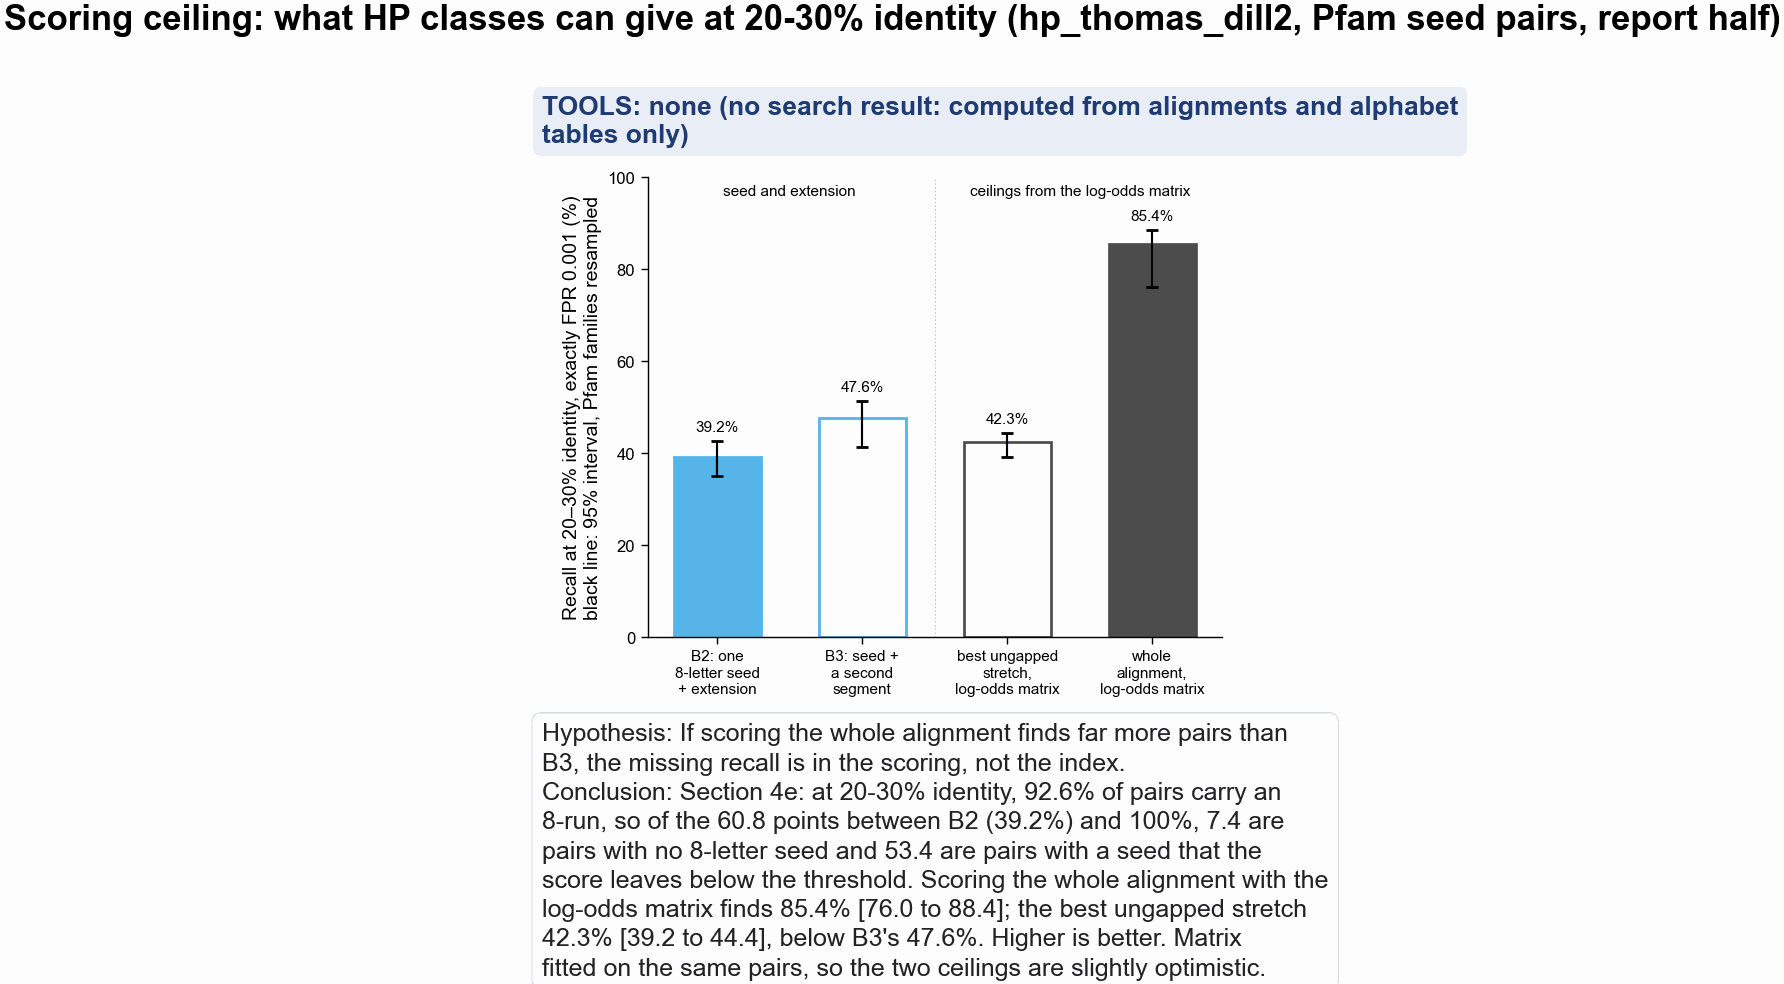

In [18]:
# the four recalls of Table 2 as bars at 20-30% identity
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 72, layout=None)
BAR4E = [
    ("B2", COLOR["B2"], True),
    ("B3", COLOR["B2"], False),
    ("stretch", "0.3", False),
    ("full", "0.3", True),
]
XLAB = {
    "B2": "B2: one\n8-letter seed\n+ extension",
    "B3": "B3: seed +\na second\nsegment",
    "stretch": "best ungapped\nstretch,\nlog-odds matrix",
    "full": "whole\nalignment,\nlog-odds matrix",
}
for x_, (n, col, filled) in enumerate(BAR4E):
    j = J4E[n]
    v = 100 * rec4e[b2030, j]
    ax.bar(x_, v, width=0.6, color=col if filled else "white", edgecolor=col, lw=1)
    ax.errorbar(
        x_,
        v,
        yerr=[[v - 100 * lo4e[b2030, j]], [100 * hi4e[b2030, j] - v]],
        color="black",
        lw=0.8,
        capsize=2,
    )
    ax.text(
        x_,
        100 * hi4e[b2030, j] + 1.5,
        f"{v:.1f}%",
        ha="center",
        va="bottom",
        fontsize=5.5,
    )
ax.set_xticks(range(len(BAR4E)), [XLAB[n] for n, _, _ in BAR4E], fontsize=5.5)
ax.set_ylabel(
    "Recall at 20–30% identity, exactly FPR 0.001 (%)\nblack line: 95% interval, Pfam families resampled"
)
ax.set_ylim(0, 100)
ax.axvline(1.5, color="0.7", lw=0.5, ls=":")
ax.text(0.5, 96, "seed and extension", ha="center", fontsize=5.5)
ax.text(2.5, 96, "ceilings from the log-odds matrix", ha="center", fontsize=5.5)
hc.finish_figure(
    fig,
    FIG / "294_scoring_ceiling.png",
    tools=hc.NO_TOOL,
    title="Scoring ceiling: what HP classes can give at 20-30% identity (hp_thomas_dill2, Pfam seed pairs, report half)",
    hypothesis="If scoring the whole alignment finds far more pairs than B3, the missing recall is in the scoring, not the index.",
    conclusion=verdict_4e_line
    + " Higher is better. Matrix fitted on the same pairs, so the two ceilings are slightly optimistic.",
    wrap=70,
)

**Verdict for 4e: most missing pairs carry a seed; what they lack is a score added up across gaps.** All numbers
are for the report half at 20–30% identity, 7,512 true pairs.

- *Seed ceiling.* 92.6% of pairs carry an 8-run and 99.3% a 6-run, yet one 8-letter word
  with extension finds 39.2%. Of the 60.8 points between B2 and 100%, 7.4 are pairs with no
  8-letter seed at all and 53.4 are pairs that have a seed but score below the threshold. A
  design that gains only by finding a seed in pairs that have no 8-run can add at most 7.4
  points (6.7 for 6-letter seeds), below 10, and fewer once its own threshold is set. So
  seeds in new pairs alone cannot give the 10 points; a gain that large has to come from how
  pairs that already carry a seed are scored (B3's second segment is one such change).
- *Scoring ceiling.* Summing the 2×2 log-odds score over each whole alignment finds 85.4%
  (95% interval 76.0 to 88.4), 37.8 points above B3 (30.1 to 42.5). It recovers 46.2 of the
  60.8 points; the other 14.6 stay out of reach even with the whole alignment. With the
  matrix fitted on the selection half instead, the ceiling is again 85.4% (difference
  +0.0, −0.2 to +0.5), so fitting on the same pairs does not inflate it noticeably.
- *Not only long alignments.* In the shortest third (50–100 scored columns) the whole
  alignment finds 69.2%, against 22.2% for B2 and 26.1% for B3; in the longest third
  (163–1,775 columns) 97.7%. 0.00099 of the shortest third's shuffled targets pass the
  threshold, against 0 of the longest third's.
- *One ungapped stretch is not enough.* The best-scoring stretch under the same matrix
  finds 42.3% (39.2 to 44.4): 3.1 points above B2 (0.5 to 5.7) and 5.3 below B3 (−8.4 to
  −0.1). A better matrix for one ungapped extension gains little. The whole-alignment recall
  comes from adding up weak evidence (0.162 bits per column on average) over many columns
  and across gaps.
- *Of the 7.4% of pairs with no 8-run,* the whole alignment still finds 2.9 points; 4.5
  points have neither a seed nor a whole-alignment score above the threshold.
- *Model check.* The mean score per column of the fitted columns equals the predicted
  relative entropy, 0.1623 bits (difference 0). Over the shuffled targets the measured mean
  is −0.1642 bits against −0.1754 predicted from the pooled class shares (+0.0111). A
  shuffle keeps its own target's class shares, and in a true pair those are close to the
  query's, so a shuffled target agrees with its query a little more often than the pooled
  shares predict.

*What this does not show.* The whole-alignment score is given Pfam's alignment of each pair,
and each shuffled target is scored on those same columns without being realigned. A real
gapped search would also look for the best alignment of an unrelated pair, which raises the
null scores and the threshold. So 85.4% is an upper bound that no search reaches. The KILL
of sections 4b and 4d stands: those sections measured the gains, and this section says where
the rest of the recall would have to come from, namely scoring across gaps (chaining or
gapped extension), not the index.

**Changes since 4d**

- No number printed in sections 1 to 4d, 5 or 6 moved; the notebook's text output before
  and after 4e was added was compared line by line, and only 4e's lines and one new summary
  line in section 6 are new.
- B2 rescored from the new joint class codes equals the stored B2 on all 180,000
  comparisons, so the shuffled targets are notebook 232's. B2's and B3's recall and 1,000
  resamples equal section 4b's exactly.
- New code: `linked_pairs_utils.py` gains `joint_codes`, `comparison_joint_codes`,
  `joint_counts`, `logodds_matrix` and `best_stretch_scores`, tested against brute force in
  `tests/test_linked_pairs_utils.py`. No new parquet file: 4e reads notebook 230's alignments
  and recomputes the shuffles.

### 4f. A null that keeps local HP patterns, and kmerseek's own chaining (added 2026-10-17)

Two things the earlier sections left untested.

**Part 1, an unrelated-protein null.** Every null in sections 4a to 4e shuffles the target's
residues along its alignment row. A shuffle keeps the target's composition and gap columns.
The concern was that it breaks up runs of hydrophobic residues and alternating H/P patterns
(membrane stretches, amphipathic helices), which unrelated real proteins keep; if HP keys
score such patterns, the shuffled null would be too easy for them.

The second null keeps those patterns. For each true pair, two null targets are built:

- take a Pfam seed sequence from a family in a *different Pfam clan* (a clan is Pfam's
  group of families with a shared origin; a family in no clan counts as its own clan),
  from the same table of notebook 230's seed alignments, so the composition comes from the
  same source;
- cut it to the true target's number of H/P residues, starting at a random position;
- put those residues into the true target's alignment row in order, so the gap columns
  (and the rare X columns, which the scoring treats as gaps) are the true target's. A
  source sequence's own X, B or Z letters also score as gaps (481 letters in 227 of the
  null targets).

The query is unchanged. Each null target is scored exactly as the true target is
(`lp.score_pair`). The draws use one random generator seeded with 292, the split's seed,
in pair order (`scripts/linked_pairs_on_alignments.py --unrelated-null`). A target longer
than every candidate from another clan is skipped and counted, not padded. Two null targets
per pair, as in 232, so the threshold rests on about the same number of null comparisons
(60,000 per half; 59,994 in the report half after the skips). The threshold rule (exactly FPR 0.001), the bootstrap (1,000 resamples of
whole Pfam families, seed 2) and the five scores are section 4b's, so the shuffled-target
column below is section 4b's numbers and the two columns use the same resamples.

In [19]:
# Part 1: the unrelated-protein null
UNREL = Path(
    "/Users/olga/data/pfam/294_unrelated_protein_null_scores.parquet"
)  # linked_pairs_on_alignments.py --unrelated-null
PFAM_SEED = Path("/Users/olga/data/pfam/Pfam-A.seed.gz")
F_NAMES = ["B1", "B2", "B3", "linked", "randstrobe"]
F_LABEL = {
    "B1": "B1: one 10-letter seed",
    "B2": "B2: one 8-letter seed",
    "B3": "B3: 8-letter seed + second segment",
    "linked": "chosen linked pair",
    "randstrobe": "randstrobe (one key per position)",
}
assert [NEW[n] for n in F_NAMES] == [
    "B1_ext",
    "B2_ext",
    "B3_ext",
    "all_a6_g32_none_ext",
    "rand_a6_g32_none_ext",
]
un = pl.read_parquet(UNREL).sort("pair_index", "kind")
assert (
    un.height == 120_000
    and (un["pair_index"].to_numpy().reshape(-1, 2) == np.arange(60_000)[:, None]).all()
)
clans4f = lp.pfam_clans(PFAM_SEED)
cand_names, cand_seqs, cand_clans, cand_lens = lp.unrelated_candidates(
    pl.read_parquet(ALN), clans4f
)
built = un.filter(pl.col("skipped").is_null())
print(
    f"candidate proteins: {cand_names.size:_} distinct Pfam seed sequences (gaps removed) from {np.unique(cand_clans).size:_} clans, "
    f"a family with no clan counted as its own"
)
print(
    f"null targets built: {built.height:_} of 120,000; skipped: {un.height - built.height} "
    f"({un.filter(pl.col('skipped').is_not_null())['pair_index'].n_unique()} pairs)"
)
print(
    un.filter(pl.col("skipped").is_not_null())
    .group_by("skipped")
    .agg(pl.len(), pl.col("n_residues").min().alias("shortest skipped target"))
    .sort("skipped")
)
print(
    f"longest candidate {cand_lens.max():_} residues; the null targets came from {built['source'].n_unique():_} distinct candidates"
)
checks4f = {
    "every null target comes from another clan": (
        built["source_clan"] != built["family_clan"]
    ).all(),
    "the pair's clan is its family's clan": (
        un["family_clan"] == un["family"].replace_strict(clans4f)
    ).all(),
    "the pairs are section 1's pairs": un.filter(pl.col("kind") == "unrel0")
    .select("pair_index", "query", "target")
    .equals(
        d.filter(pl.col("kind") == "real")
        .sort("pair_index")
        .select(pl.col("pair_index").cast(pl.Int64), "query", "target")
    ),
}
# rebuild 300 null targets from the stored draw and rescore them: the stored scores are lp.score_pair's
aln4f = pf4e.select("pair_index", "qaln", "taln")
seq_of = dict(zip(zip(cand_names, cand_clans), cand_seqs))
chk = (
    built.sample(n=300, seed=4).join(aln4f, on="pair_index").sort("pair_index", "kind")
)
same4f = 0
for r in chk.iter_rows(named=True):
    src = seq_of[(r["source"], r["source_clan"])]
    row = lp.place_in_gaps(r["taln"], src[r["offset"] : r["offset"] + r["n_residues"]])
    (sc_,) = lp.score_pair(r["qaln"], row, np.random.default_rng(0), 0)
    same4f += all(sc_[NEW[n]] == r[NEW[n]] for n in F_NAMES)
checks4f[
    "300 null targets rebuilt from the stored draw rescore to the stored scores"
] = (same4f == 300)
for k_, v_ in checks4f.items():
    print(f"  {k_}: {v_}")
assert all(checks4f.values())

# what differs between the two kinds of null target: HP runs, H share, and agreement with the query on aligned columns
TAB4F = lp.TABLES[lp.ALPHABET]


def hp_codes(rowstr):
    return TAB4F[np.frombuffer(rowstr.encode(), np.uint8)]


def longest_h_run(c):
    h = (c[c != lp.GAP] == 0).astype(
        np.int8
    )  # the sequence's own residues, gaps and X left out
    edges = np.diff(np.r_[0, h, 0])
    return int(
        (np.flatnonzero(edges == -1) - np.flatnonzero(edges == 1)).max(initial=0)
    )


desc_ = []
rep2030_ids = set(pidx_all[rep & (bin_all == b2030)].tolist())
u0 = built.filter(pl.col("kind") == "unrel0").select(
    "pair_index", "source", "source_clan", "offset", "n_residues"
)
for r in (
    aln4f.filter(pl.col("pair_index").is_in(list(rep2030_ids)))
    .join(u0, on="pair_index")
    .iter_rows(named=True)
):
    cq = hp_codes(r["qaln"])
    rows3 = [
        r["taln"],
        lp.shuffled_target_rows(r["taln"], r["pair_index"], 1)[0],
        lp.place_in_gaps(
            r["taln"],
            seq_of[(r["source"], r["source_clan"])][
                r["offset"] : r["offset"] + r["n_residues"]
            ],
        ),
    ]
    out_ = []
    for row in rows3:
        ct = hp_codes(row)
        both = (cq != lp.GAP) & (ct != lp.GAP)
        out_ += [
            longest_h_run(ct),
            float((ct[ct != lp.GAP] == 0).mean()),
            float((cq[both] == ct[both]).mean()),
            abs(
                float((cq[cq != lp.GAP] == 0).mean())
                - float((ct[ct != lp.GAP] == 0).mean())
            ),
        ]
    desc_.append(out_)
desc_ = np.array(desc_)
print(
    f"Report-half pairs at 20-30% identity with a first unrelated-protein target: {desc_.shape[0]:_}. Per target, mean over pairs "
    "(true target; its first shuffle; its first unrelated-protein target):"
)
for j_, lab_ in enumerate(
    [
        "longest run of H residues",
        "share of H residues",
        "share of aligned columns whose HP class agrees with the query",
        "|query H share - target H share|",
    ]
):
    print(
        f"  {lab_}: "
        + "; ".join(f"{desc_[:, 4 * k + j_].mean():.3f}" for k in range(3))
    )
print(
    f"  targets with an H run of 8 or more: "
    + "; ".join(f"{(desc_[:, 4 * k] >= 8).mean():.3f}" for k in range(3))
)

# null scores for the report half, (pairs, 2, scores); a skipped null target is NaN and left out of the threshold
un_arr = np.stack(
    [
        un.filter(pl.col("kind") == f"unrel{k}")
        .sort("pair_index")
        .select([NEW[n] for n in F_NAMES])
        .to_numpy()
        .astype(float)
        for k in range(2)
    ],
    axis=1,
)
idx5 = [COLS.index(NEW[n]) for n in F_NAMES]
rr5, ns5, nu5 = real_r[:, idx5], null_r[:, :, idx5], un_arr[rep]
print(
    f"report half: {int((~np.isnan(nu5[:, :, 0])).sum()):_} unrelated-protein null comparisons, {ns5[:, :, 0].size:_} shuffled-target ones"
)
thr_u, w_u, rec_u = lp.recall_at_exact_fpr(rr5, nu5, bin_r, FPR)
boot_u = lp.bootstrap_recall_by_group(rr5, nu5, bin_r, fam_r, FPR, N_BOOT, seed=2)
lo_u, hi_u = np.percentile(boot_u, 2.5, axis=0), np.percentile(boot_u, 97.5, axis=0)
J5 = [JN[n] for n in F_NAMES]
rec_s, boot_s, lo_s, hi_s, thr_s5 = (
    rec_n[:, J5],
    boot_n[:, :, J5],
    lo_n[:, J5],
    hi_n[:, J5],
    thr_n[J5],
)
# the shuffled-target column is section 4b's: recomputing it from the same scores gives the same numbers
again = lp.recall_at_exact_fpr(rr5, ns5, bin_r, FPR)
assert np.array_equal(again[2], rec_s) and np.array_equal(again[0], thr_s5)
diff_b = boot_u[:, b2030] - boot_s[:, b2030]
d_lo5, d_hi5 = np.percentile(diff_b, [2.5, 97.5], axis=0)
fmt = lambda v, l, h: f"{100 * v:.1f} [{100 * l:.1f} to {100 * h:.1f}]"
t4f = (
    pl.DataFrame(
        [
            {
                "order": k,
                "design": F_LABEL[n],
                "threshold, shuffled": thr_s5[k],
                "threshold, unrelated": thr_u[k],
                "recall (%), shuffled-target null (sections 4a-4e)": fmt(
                    rec_s[b2030, k], lo_s[b2030, k], hi_s[b2030, k]
                ),
                "recall (%), unrelated-protein null": fmt(
                    rec_u[b2030, k], lo_u[b2030, k], hi_u[b2030, k]
                ),
                "unrelated minus shuffled (points)": fmt(
                    rec_u[b2030, k] - rec_s[b2030, k], d_lo5[k], d_hi5[k]
                ),
            }
            for k, n in enumerate(F_NAMES)
        ]
    )
    .sort("order")
    .drop("order")
)
print(
    f"Table 1. Report half, 20-30% identity, {int((bin_r == b2030).sum()):_} true pairs. Recall at exactly FPR 0.001 per comparison, "
    "on each pair's own alignment; 95% intervals from the same 1,000 family resamples (seed 2) under both nulls. Thresholds in score units."
)
with pl.Config(fmt_str_lengths=60, tbl_width_chars=260):
    print(t4f)
print("Every identity bin, recall (%) shuffled-target null -> unrelated-protein null:")
for k, n in enumerate(F_NAMES):
    print(
        f"  {n:11s}"
        + "  ".join(
            f"{b} {100 * rec_s[i, k]:.1f} -> {100 * rec_u[i, k]:.1f}"
            for i, b in enumerate(BINS)
        )
    )

# the 4b decision under the new null: same paired gains, same resamples
best_u = "B1" if rec_u[b2030, 0] >= rec_u[b2030, 1] else "B2"


def paired_u(a, b):
    ia, ib = F_NAMES.index(a), F_NAMES.index(b)
    g = rec_u[b2030, ia] - rec_u[b2030, ib]
    l_, h_ = np.percentile(boot_u[:, b2030, ia] - boot_u[:, b2030, ib], [2.5, 97.5])
    return g, l_, h_


gains_u = []
for a_, b_, lab, decides in COMPARE:
    g, l_, h_ = paired_u(a_, best_u if b_ == best_n else b_)
    gains_u.append(
        {
            "comparison": lab.replace(
                "better single seed", f"better single seed ({best_u})"
            ),
            "gain": round(100 * g, 1),
            "ci_low": round(100 * l_, 1),
            "ci_high": round(100 * h_, 1),
            "call_vs_10_points": (
                call(l_, h_)
                if decides
                else (
                    "control: interval excludes 0"
                    if l_ > 0 or h_ < 0
                    else "control: interval includes 0"
                )
            ),
        }
    )
gains_u = pl.DataFrame(gains_u)
print(
    "Paired gains at 20-30% identity under the unrelated-protein null (points, exactly FPR 0.001, families resampled):"
)
with pl.Config(fmt_str_lengths=80, tbl_width_chars=200):
    print(gains_u)
VERDICT_4F = gains_u["call_vs_10_points"][0]
moves = rec_u[b2030] - rec_s[b2030]
verdict_4f1_line = (
    f"Section 4f part 1: against the unrelated-protein null, recall at 20-30% identity moves by "
    + ", ".join(f"{n} {100 * mv:+.1f}" for n, mv in zip(F_NAMES, moves))
    + f" points; the chosen linked pair's gain over {best_u} is {gains_u['gain'][0]:+.1f} ({gains_u['ci_low'][0]:+.1f} to {gains_u['ci_high'][0]:+.1f}): {VERDICT_4F}."
)
print(verdict_4f1_line)

candidate proteins: 256_761 distinct Pfam seed sequences (gaps removed) from 16_389 clans, a family with no clan counted as its own
null targets built: 119_990 of 120,000; skipped: 10 (5 pairs)
shape: (1, 3)
┌─────────────────────────────────┬─────┬─────────────────────────┐
│ skipped                         ┆ len ┆ shortest skipped target │
│ ---                             ┆ --- ┆ ---                     │
│ str                             ┆ u32 ┆ i64                     │
╞═════════════════════════════════╪═════╪═════════════════════════╡
│ no other-clan candidate long e… ┆ 10  ┆ 2074                    │
└─────────────────────────────────┴─────┴─────────────────────────┘
longest candidate 2_619 residues; the null targets came from 79_016 distinct candidates


  every null target comes from another clan: True
  the pair's clan is its family's clan: True
  the pairs are section 1's pairs: True
  300 null targets rebuilt from the stored draw rescore to the stored scores: True


Report-half pairs at 20-30% identity with a first unrelated-protein target: 7_512. Per target, mean over pairs (true target; its first shuffle; its first unrelated-protein target):
  longest run of H residues: 5.278; 5.553; 5.216
  share of H residues: 0.435; 0.435; 0.427
  share of aligned columns whose HP class agrees with the query: 0.739; 0.515; 0.508
  |query H share - target H share|: 0.033; 0.033; 0.073
  targets with an H run of 8 or more: 0.115; 0.133; 0.106
report half: 59_994 unrelated-protein null comparisons, 60_000 shuffled-target ones


Table 1. Report half, 20-30% identity, 7_512 true pairs. Recall at exactly FPR 0.001 per comparison, on each pair's own alignment; 95% intervals from the same 1,000 family resamples (seed 2) under both nulls. Thresholds in score units.
shape: (5, 6)
┌────────────────────────────────────┬─────────────────────┬──────────────────────┬───────────────────────────────────────────────────┬────────────────────────────────────┬───────────────────────────────────┐
│ design                             ┆ threshold, shuffled ┆ threshold, unrelated ┆ recall (%), shuffled-target null (sections 4a-4e) ┆ recall (%), unrelated-protein null ┆ unrelated minus shuffled (points) │
│ ---                                ┆ ---                 ┆ ---                  ┆ ---                                               ┆ ---                                ┆ ---                               │
│ str                                ┆ f64                 ┆ f64                  ┆ str                                    

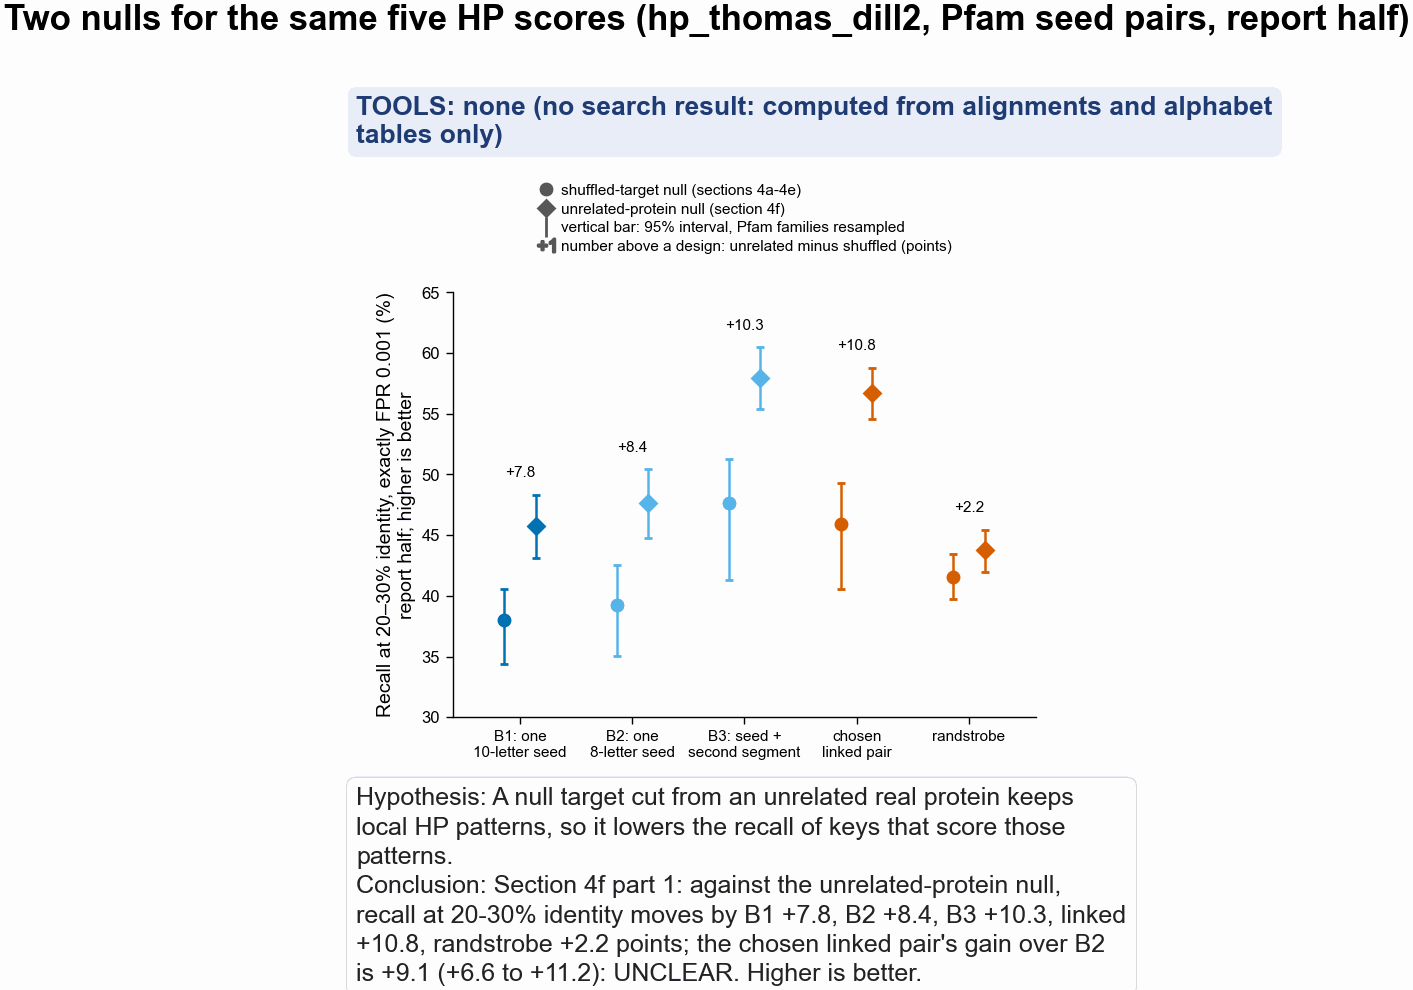

In [20]:
# Table 1 as a figure: five designs, one mark per null
fig, axd = plt.subplot_mosaic(
    [["legend"], ["main"]],
    figsize=(pf.ONE_COLUMN_MM * pf.MM, 80 * pf.MM),
    height_ratios=[0.2, 1],
)
NULL_MARK = {
    "shuffled": ("o", "shuffled-target null (sections 4a-4e)"),
    "unrelated": ("D", "unrelated-protein null (section 4f)"),
}
axd["legend"].set_axis_off()
axd["legend"].legend(
    handles=[
        Line2D([], [], color="0.35", marker=mk, ms=4, lw=0, label=lab)
        for mk, lab in NULL_MARK.values()
    ]
    + [
        Line2D(
            [],
            [],
            color="0.35",
            marker="|",
            ms=7,
            lw=0,
            label="vertical bar: 95% interval, Pfam families resampled",
        ),
        Line2D(
            [],
            [],
            color="0.35",
            marker="$+1$",
            ms=6,
            lw=0,
            label="number above a design: unrelated minus shuffled (points)",
        ),
    ],
    loc="center",
    ncol=1,
    fontsize=5.5,
    frameon=False,
)
ax = axd["main"]
F_COLOUR = {
    "B1": COLOR["B1"],
    "B2": COLOR["B2"],
    "B3": COLOR["B2"],
    "linked": COLOR["linked"],
    "randstrobe": COLOR["linked"],
}
for k, n in enumerate(F_NAMES):
    for dx, (key, rec_, lo_, hi_) in [
        (-0.14, ("shuffled", rec_s, lo_s, hi_s)),
        (0.14, ("unrelated", rec_u, lo_u, hi_u)),
    ]:
        v = 100 * rec_[b2030, k]
        ax.errorbar(
            k + dx,
            v,
            yerr=[[v - 100 * lo_[b2030, k]], [100 * hi_[b2030, k] - v]],
            color=F_COLOUR[n],
            marker=NULL_MARK[key][0],
            ms=4,
            lw=0.9,
            capsize=1.5,
        )
    ax.text(
        k,
        100 * max(hi_s[b2030, k], hi_u[b2030, k]) + 1.2,
        f"{100 * moves[k]:+.1f}",
        ha="center",
        va="bottom",
        fontsize=5.5,
    )
ax.set_xticks(
    range(len(F_NAMES)),
    [
        "B1: one\n10-letter seed",
        "B2: one\n8-letter seed",
        "B3: seed +\nsecond segment",
        "chosen\nlinked pair",
        "randstrobe",
    ],
    fontsize=5.5,
)
ax.set_xlim(-0.6, len(F_NAMES) - 0.4)
ax.set_ylim(30, 65)
ax.set_ylabel(
    "Recall at 20–30% identity, exactly FPR 0.001 (%)\nreport half; higher is better"
)
hc.finish_figure(
    fig,
    FIG / "294_null_comparison.png",
    tools=hc.NO_TOOL,
    title="Two nulls for the same five HP scores (hp_thomas_dill2, Pfam seed pairs, report half)",
    hypothesis="A null target cut from an unrelated real protein keeps local HP patterns, so it lowers the recall of keys that score those patterns.",
    conclusion=verdict_4f1_line + " Higher is better.",
    wrap=70,
)

**Part 2, kmerseek's own chaining.** B3 (section 4b) showed that the linked key's gain
comes from a second extended segment, not a second exact word. kmerseek can already join
extended regions: `--chain-max-gap G --chain-max-shift D` chains regions at most G residues
apart on the query and at most D diagonals apart (a net insertion or deletion of up to D
residues), scored with Karlin–Altschul sum statistics. Does that give B3's gain?

*Set-up* (`scripts/294_kmerseek_chaining_inputs.py` writes the inputs,
`scripts/294_kmerseek_chaining.sbatch` runs kmerseek on Sherlock):

- kmerseek v0.4.0, the version pinned in the repo's pipelines (image
  `docker.io/olgabot/kmerseek:0.4.0-rc5`, built from tag `v0.4.0`), `hp_thomas_dill2`,
  k = 8, scaled 1, extension with mismatch penalty 2 (this notebook's) and kmerseek's
  default X-drop of 8 (the notebook's extension has no X-drop).
- Queries: the report half's true pairs at 20–30% identity. Database: their targets,
  indexed together. A second database holds every target shuffled once, with notebook
  232's first shuffle of that pair, indexed the same way.
- Three searches of each database: no chaining; chaining up to 32 residues apart on one
  diagonal (`--chain-max-shift 0`); and up to 32 apart across a shift of up to 32
  (`--chain-max-shift 32`). The gap of 32 is B3's window.
- All six searches use one E-value rule: `--ka-k` set to the closed-form K at the real
  database's match probability, with the closed-form lambda per pair, so the cutoff taken
  from the shuffled database applies to the real one.
- *Found*: the query's best E-value against its own target is at or below the cutoff. The
  *cutoff* is the E-value at which 0.1% of all query–shuffled-target comparisons (every
  query against every shuffled target) score at or below it. The interval resamples whole
  Pfam families (1,000 times, seed 3); each resample recomputes the cutoff from the drawn
  queries' null comparisons.

This is the first number in the notebook that pays for chance hits off the alignment's
diagonal: kmerseek searches every diagonal of every query–target comparison, and the false
positives are counted against a whole database. Sections 4a to 4e score each pair only on
its own alignment. So the two kinds of recall sit in separate columns of Table 2, and the
comparison favours B2 and B3.

*Rule, written before any kmerseek number was seen.* The gain is already in kmerseek if
kmerseek with `--chain-max-shift 32` gains over kmerseek without chaining at least as much
as B3 gains over B2 (+8.4 points): the paired gain's 95% interval reaches +8.4 or above. It
is not if the whole interval lies below +8.4.

In [21]:
# Part 2: kmerseek's own chaining (Sherlock; the cell reads the results if they exist)
import json
import os

CHAIN_DIR = Path(
    os.environ.get("NB294_CHAINING_DIR", "/Users/olga/data/pfam/294_chaining")
)
CHAIN_RES = CHAIN_DIR / "results"
chain_info = json.loads((CHAIN_DIR / "inputs.json").read_text())
pairs_c = pl.read_csv(CHAIN_DIR / "pairs.tsv", separator="\t").sort("pair_index")
want_pairs = np.sort(pidx_all[rep & (bin_all == b2030)])
assert np.array_equal(
    pairs_c["pair_index"].to_numpy(), want_pairs
), "the chaining inputs are not this notebook's report-half 20-30% pairs"
N_DB = chain_info["n_targets"]
print(
    f"kmerseek inputs: {pairs_c.height:_} report-half pairs at 20-30% identity, {chain_info['n_queries']:_} distinct queries; "
    f"the database holds {N_DB:_} target proteins ({chain_info['n_target_residues']:_} residues), the shuffled database the same {N_DB:_} shuffled"
)
CHAINS4F = {
    "none": "kmerseek, no chaining",
    "shift0": "kmerseek, --chain-max-shift 0",
    "shift32": "kmerseek, --chain-max-shift 32",
}
chain_files = {
    (db_, ch): CHAIN_RES / f"kmerseek_{db_}_{ch}.csv.gz"
    for db_ in ["real", "shuffled"]
    for ch in CHAINS4F
}
CHAIN_RAN = all(f.exists() for f in chain_files.values())
if not CHAIN_RAN:
    print(
        "kmerseek chaining not run yet: submit scripts/294_kmerseek_chaining.sbatch on Sherlock"
    )
    verdict_4f2_line = "Section 4f part 2: kmerseek chaining not run yet, so whether the gain is already in kmerseek is not known."
else:
    settings = {}
    for (db_, ch), f in chain_files.items():
        settings[(db_, ch)] = dict(
            ln.split("=", 1)
            for ln in Path(str(f).replace(".csv.gz", ".settings.txt"))
            .read_text()
            .splitlines()
        )
    ka_ks = {s["ka_k"] for s in settings.values()}
    assert len(ka_ks) == 1, f"the six searches used different K: {ka_ks}"
    E_KEEP = float(next(iter(settings.values()))["e_keep"])
    share_c = pairs_c.group_by("query").len().rename({"len": "share"})
    pc = pairs_c.with_row_index("p").join(share_c, on="query").sort("p")
    share_arr = pc["share"].to_numpy()
    fam_c = pc["family"].to_numpy()
    own_e, null_pe = {}, {}
    for ch in CHAINS4F:
        real_best = lp.read_kmerseek_best_evalue(chain_files[("real", ch)])
        own = pc.join(
            real_best.rename({"query_name": "query", "target_name": "target"}),
            on=["query", "target"],
            how="left",
        ).sort("p")
        own_e[ch] = own["region_evalue"].fill_null(np.inf).to_numpy()
        nul = lp.read_kmerseek_best_evalue(chain_files[("shuffled", ch)])
        assert nul["target_name"].str.starts_with("shuffled_").all()
        nul = (
            nul.rename({"query_name": "query"})
            .join(pc.select("p", "query"), on="query")
            .sort("region_evalue", "p", "target_name")
        )
        null_pe[ch] = (nul["p"].to_numpy(), nul["region_evalue"].to_numpy())
        print(
            f"{CHAINS4F[ch]}: {settings[('real', ch)]['rows_kept']} real and {settings[('shuffled', ch)]['rows_kept']} shuffled rows kept "
            f"(E <= {E_KEEP:g}); own-target rows found for {int(np.isfinite(own_e[ch]).sum()):_} of {pc.height:_} pairs"
        )
    res4f2 = {}
    for ch in CHAINS4F:
        cut, ach, rec = lp.evalue_cutoff_recall(
            own_e[ch], *null_pe[ch], share_arr, N_DB, FPR
        )
        assert cut < E_KEEP
        res4f2[ch] = {"cutoff": cut, "fpr": ach, "recall": rec, "boot": []}
    for m in lp.group_multiplicities(fam_c, N_BOOT, seed=3):
        for ch in CHAINS4F:
            res4f2[ch]["boot"].append(
                lp.evalue_cutoff_recall(
                    own_e[ch], *null_pe[ch], share_arr, N_DB, FPR, m
                )[2]
            )
    for ch in CHAINS4F:
        res4f2[ch]["boot"] = np.array(res4f2[ch]["boot"])
        res4f2[ch]["lo"], res4f2[ch]["hi"] = np.percentile(
            res4f2[ch]["boot"], [2.5, 97.5]
        )
    rows_t2 = [
        {
            "order": 0,
            "score": "B2: one 8-letter seed + extension",
            "recall per comparison on the pair's own alignment, shuffled target (%)": fmt(
                rec_n[b2030, JN["B2"]], lo_n[b2030, JN["B2"]], hi_n[b2030, JN["B2"]]
            ),
            "recall over the whole database, shuffled database (%)": "",
            "cutoff": f"score > {thr_n[JN['B2']]:.0f} (section 4b)",
        },
        {
            "order": 1,
            "score": "B3: 8-letter seed + second segment",
            "recall per comparison on the pair's own alignment, shuffled target (%)": fmt(
                rec_n[b2030, JN["B3"]], lo_n[b2030, JN["B3"]], hi_n[b2030, JN["B3"]]
            ),
            "recall over the whole database, shuffled database (%)": "",
            "cutoff": f"score > {thr_n[JN['B3']]:.0f} (section 4b)",
        },
    ]
    for o_, ch in enumerate(CHAINS4F, start=2):
        r_ = res4f2[ch]
        rows_t2.append(
            {
                "order": o_,
                "score": CHAINS4F[ch],
                "recall per comparison on the pair's own alignment, shuffled target (%)": "",
                "recall over the whole database, shuffled database (%)": fmt(
                    r_["recall"], r_["lo"], r_["hi"]
                ),
                "cutoff": f"E <= {r_['cutoff']:.3g} (FPR {r_['fpr']:.5f})",
            }
        )
    print(
        f"Table 2. Report half, 20-30% identity, {pc.height:_} true pairs; database of {N_DB:_} target proteins. "
        "95% intervals with Pfam families resampled (4b: seed 2, kmerseek: seed 3). The two recall columns use different false-positive rates and are not one scale."
    )
    with pl.Config(fmt_str_lengths=70, tbl_width_chars=300):
        print(pl.DataFrame(rows_t2).sort("order").drop("order"))
    g_b = res4f2["shift32"]["boot"] - res4f2["none"]["boot"]
    g32 = res4f2["shift32"]["recall"] - res4f2["none"]["recall"]
    g_lo, g_hi = np.percentile(g_b, [2.5, 97.5])
    g0_b = res4f2["shift32"]["boot"] - res4f2["shift0"]["boot"]
    B3_GAIN = rec_n[b2030, JN["B3"]] - rec_n[b2030, JN["B2"]]
    print(
        f"kmerseek --chain-max-shift 32 minus no chaining: {100 * g32:+.1f} points [{100 * g_lo:+.1f} to {100 * g_hi:+.1f}]; "
        f"minus --chain-max-shift 0: {100 * (res4f2['shift32']['recall'] - res4f2['shift0']['recall']):+.1f} "
        f"[{100 * np.percentile(g0_b, 2.5):+.1f} to {100 * np.percentile(g0_b, 97.5):+.1f}]; B3 minus B2 (4b): {100 * B3_GAIN:+.1f}"
    )
    IN_KMERSEEK = "is" if g_hi >= B3_GAIN else "is not"
    verdict_4f2_line = (
        f"Section 4f part 2: the index change {IN_KMERSEEK} already in kmerseek. Chaining across a shift of up to 32 gains "
        f"{100 * g32:+.1f} points over no chaining ({100 * g_lo:+.1f} to {100 * g_hi:+.1f}), against B3's {100 * B3_GAIN:+.1f} over B2."
    )
    # figure: four bars
    fig, ax = pf.figure(pf.ONE_COLUMN_MM, 72, layout=None)
    BARS = [
        (
            "B2",
            rec_n[b2030, JN["B2"]],
            lo_n[b2030, JN["B2"]],
            hi_n[b2030, JN["B2"]],
            COLOR["B2"],
            True,
        ),
        (
            "B3",
            rec_n[b2030, JN["B3"]],
            lo_n[b2030, JN["B3"]],
            hi_n[b2030, JN["B3"]],
            COLOR["B2"],
            False,
        ),
        (
            "shift0",
            res4f2["shift0"]["recall"],
            res4f2["shift0"]["lo"],
            res4f2["shift0"]["hi"],
            "0.3",
            False,
        ),
        (
            "shift32",
            res4f2["shift32"]["recall"],
            res4f2["shift32"]["lo"],
            res4f2["shift32"]["hi"],
            "0.3",
            True,
        ),
    ]
    for x_, (n, v, l_, h_, col, filled) in enumerate(BARS):
        ax.bar(
            x_,
            100 * v,
            width=0.6,
            color=col if filled else "white",
            edgecolor=col,
            lw=1,
        )
        ax.errorbar(
            x_,
            100 * v,
            yerr=[[100 * (v - l_)], [100 * (h_ - v)]],
            color="black",
            lw=0.8,
            capsize=2,
        )
        ax.text(
            x_,
            100 * h_ + 1.5,
            f"{100 * v:.1f}%",
            ha="center",
            va="bottom",
            fontsize=5.5,
        )
    ax.axhline(
        100 * res4f2["none"]["recall"], xmin=0.5, xmax=1.0, color="0.3", ls="--", lw=0.8
    )
    ax.legend(
        handles=[
            Line2D(
                [],
                [],
                color="0.3",
                ls="--",
                lw=0.8,
                label=f"kmerseek without chaining: {100 * res4f2['none']['recall']:.1f}%",
            )
        ],
        loc="lower right",
        bbox_to_anchor=(1.0, 1.06),
        frameon=False,
        fontsize=5.5,
    )
    ax.axvline(1.5, color="0.7", lw=0.5, ls=":")
    ax.text(
        0.5,
        101,
        "per comparison, own alignment",
        ha="center",
        va="bottom",
        fontsize=5.5,
        clip_on=False,
    )
    ax.text(
        2.5,
        101,
        f"whole database ({N_DB:,} targets)",
        ha="center",
        va="bottom",
        fontsize=5.5,
        clip_on=False,
    )
    ax.set_xticks(
        range(4),
        [
            "B2: one\n8-letter seed",
            "B3: seed +\nsecond segment",
            "kmerseek\n--chain-max-shift 0",
            "kmerseek\n--chain-max-shift 32",
        ],
        fontsize=5.5,
    )
    ax.set_ylim(0, 100)
    ax.set_ylabel(
        "Recall at 20–30% identity, FPR 0.001 (%)\nblack line: 95% interval, Pfam families resampled"
    )
    hc.finish_figure(
        fig,
        FIG / "294_kmerseek_chaining.png",
        tools=f"kmerseek v0.4.0 (olgabot/kmerseek:0.4.0-rc5), hp_thomas_dill2, k=8, extension penalty 2, X-drop 8, --chain-max-gap 32; B2 and B3 from section 4b",
        title="kmerseek's own chaining against B2 and B3 (Pfam seed pairs, report half, 20-30% identity)",
        hypothesis="kmerseek's chaining across shifts already gives B3's gain from a second extended segment.",
        conclusion=verdict_4f2_line
        + " Higher is better. Left pair: false positives per comparison on the pair's own alignment; right pair: over every query-target comparison of the database.",
        wrap=70,
    )
print(verdict_4f2_line)

kmerseek inputs: 7_512 report-half pairs at 20-30% identity, 7_404 distinct queries; the database holds 7_384 target proteins (1_260_658 residues), the shuffled database the same 7_384 shuffled
kmerseek chaining not run yet: submit scripts/294_kmerseek_chaining.sbatch on Sherlock
Section 4f part 2: kmerseek chaining not run yet, so whether the gain is already in kmerseek is not known.


**Verdict for 4f, part 1.** The unrelated-protein null pushes recall up, not down. At 20–30%
identity, recall rises by 7.8 points for B1 (95% interval 4.5 to 11.8), 8.4 for B2 (4.5 to
12.9), 10.3 for B3 (6.3 to 16.6), 10.8 for the chosen linked pair (7.2 to 16.4) and 2.2 for
the randstrobe (0.1 to 4.1). Every threshold is 1 to 4 score units lower, so the shuffled
target is the stricter null, not the easier one. The concern behind this null does not hold: the
unrelated-protein targets have the true targets' hydrophobic runs (the longest run averages
5.2 against 5.3 residues; 10.6% and 11.5% hold a run of 8 or more), and the shuffles have
slightly longer ones, not shorter (5.6; 13.3%). The two nulls also differ in composition: a
shuffle keeps the true target's hydrophobic share, which is close to the query's (mean
difference 0.033), while an unrelated protein's differs by 0.073 on average. Which of the
two differences sets the shuffled null's higher thresholds was not tested. Under the new null the chosen linked pair gains +9.1 points over B2
(6.6 to 11.2). The interval crosses 10, so by section 4b's rule it is unclear, not a KILL.
The linked pair still does no better than B3 (−1.2, −2.5 to +0.2), and B3 gains +10.3 over
B2 (7.8 to 12.6), so the gain still comes from the second extended segment, not the second
exact word. The randstrobe, the one-key-per-position version an index can afford, falls
3.9 points below B2 (−6.6 to −1.2). The KILL of section 4b holds against the shuffled-target
null, the stricter of the two, and is unclear against the unrelated-protein null.

**Verdict for 4f, part 2.** Not run yet. The inputs are written and the Sherlock job is
`scripts/294_kmerseek_chaining.sbatch`; until its results are copied to
`~/data/pfam/294_chaining/results/`, the cell above prints "kmerseek chaining not run yet"
and draws no figure. The database holds 7,384 target proteins (1,260,658 residues) for the
7,512 report-half pairs at 20–30% identity, with 7,404 distinct queries. Whether the index
change is already in kmerseek is not known until the job has run; the cell prints that line
from the data once it has.

**Changes since 4e**

- No number printed in sections 1 to 4e, 5 or 6 moved. The notebook's text output before
  and after 4f was added was compared line by line; only 4f's lines and new summary lines
  in section 6 are new.
- The shuffled-target column of Table 1 is section 4b's numbers (rechecked by recomputing
  them from the same scores), and the unrelated-protein column uses the same 1,000 family
  resamples, so their difference is a paired one.
- New code: `linked_pairs_utils.py` gains `select_half_ids`, `pfam_clans`,
  `unrelated_candidates`, `draw_unrelated`, `place_in_gaps`, `shuffled_target_rows`,
  `read_kmerseek_best_evalue`, `evalue_cutoff_recall` and `group_multiplicities`, and
  `recall_at_exact_fpr` leaves out a NaN null score (no earlier section has one, so their
  numbers are unchanged). Brute-force tests in `tests/test_linked_pairs_utils.py`.
  `linked_pairs_on_alignments.py --unrelated-null` writes
  `~/data/pfam/294_unrelated_protein_null_scores.parquet` (30 s on 12 processes);
  `scripts/294_kmerseek_chaining_inputs.py` writes `~/data/pfam/294_chaining/`;
  `scripts/294_kmerseek_chaining.sbatch` is the Sherlock job.

## 5. Bits, measured on Swiss-Prot

How often does a key match by chance? For each setting, every key in Swiss-Prot
(`uniprot_sprot.fasta.gz`, 572,970 proteins, encoded in `hp_thomas_dill2`) is counted, and
the chance that two keys drawn at random are equal is the sum over keys of p(key)². Its
−log2 is the measured number of bits. The prediction drawn as a line assumes one bit per HP
letter, plus log2 of the number of gap values the key stores. The y-axis is the expected
number of chance key matches between two unrelated sequences of 131 residues (the median
domain length of the pairs above), over every pair of positions, not one diagonal.

Key frequencies are counted directly from Swiss-Prot. The project's stored Swiss-Prot
spectra (`~/data/kmerseek-kmer-spectra/sprot.hp_thomas_dill.k*.spectrum.csv.gz`) start at
15 letters and list 72,533 distinct HP 15-mers, more than the 32,768 two letters allow, so
they use a different encoding. Only keys that fit inside 131 residues are counted.

valid HP 15-mers counted in Swiss-Prot: 199_555_063; median pair length 131
single words:
shape: (4, 4)
┌────────┬────────────────┬───────────────┬─────────────────────────┐
│ anchor ┆ predicted_bits ┆ measured_bits ┆ expected_chance_matches │
│ ---    ┆ ---            ┆ ---           ┆ ---                     │
│ i64    ┆ f64            ┆ f64           ┆ f64                     │
╞════════╪════════════════╪═══════════════╪═════════════════════════╡
│ 6      ┆ 6.0            ┆ 5.79          ┆ 278.84                  │
│ 7      ┆ 7.0            ┆ 6.75          ┆ 140.02                  │
│ 8      ┆ 8.0            ┆ 7.71          ┆ 70.43                   │
│ 10     ┆ 10.0           ┆ 9.62          ┆ 17.94                   │
└────────┴────────────────┴───────────────┴─────────────────────────┘
shape: (72, 9)
┌──────┬────────┬─────────┬───────────┬───────────────────┬────────────────┬───────────────┬──────────────────────────┬─────────────────────────┐
│ mode ┆ anchor ┆ gap_max ┆ treatme

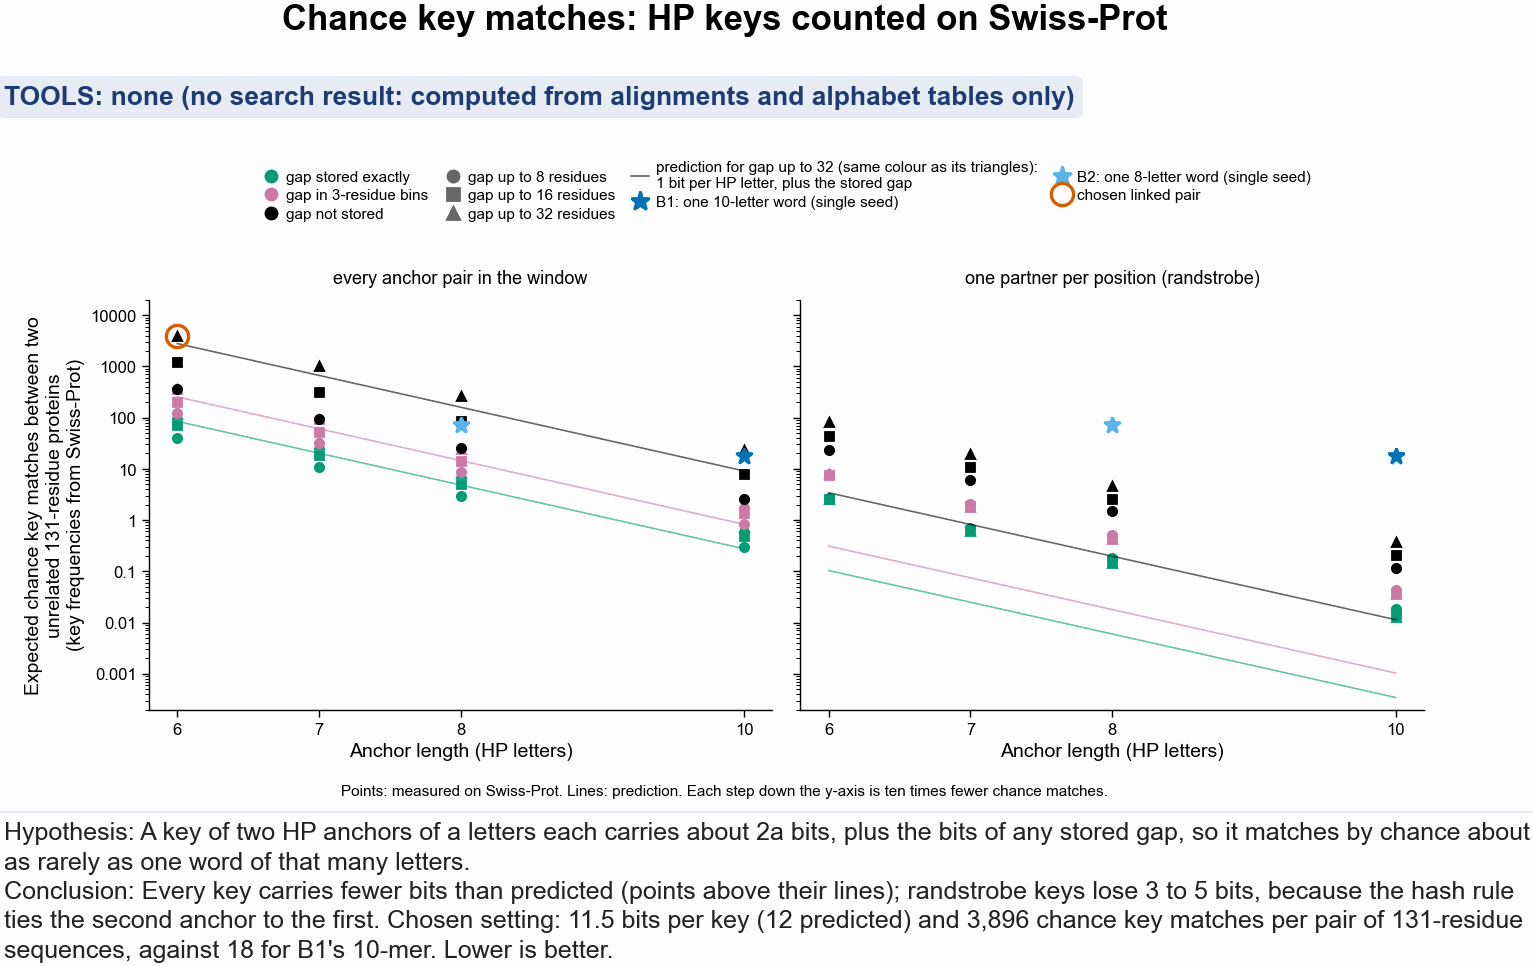

In [22]:
spec = pl.read_parquet(SPECTRUM)
check = spec.filter(pl.col("mode") == "check")
spec = spec.filter(pl.col("mode") != "check").with_columns(
    (pl.col("keys_per_sequence") ** 2 * (2.0 ** -pl.col("predicted_bits"))).alias(
        "predicted_chance_matches"
    ),
    (pl.col("predicted_bits") - pl.col("measured_bits")).alias(
        "bits_short_of_prediction"
    ),
)
L_MED = spec["median_length"][0]
print(
    f"valid HP 15-mers counted in Swiss-Prot: {int(check['rate'][0]):_}; median pair length {L_MED:.0f}"
)
words = spec.filter(pl.col("mode") == "word").select(
    "anchor", "predicted_bits", "measured_bits", "expected_chance_matches"
)
print("single words:")
print(words.with_columns(pl.col("measured_bits", "expected_chance_matches").round(2)))
tabl = (
    spec.filter(pl.col("mode") != "word")
    .select(
        "mode",
        "anchor",
        "gap_max",
        "treatment",
        "keys_per_sequence",
        "predicted_bits",
        "measured_bits",
        "bits_short_of_prediction",
        "expected_chance_matches",
    )
    .sort("mode", "gap_max", "treatment", "anchor")
)
print(
    tabl.with_columns(
        pl.col(
            "keys_per_sequence",
            "predicted_bits",
            "measured_bits",
            "bits_short_of_prediction",
        ).round(2),
        pl.col("expected_chance_matches").round(3),
    )
)
ch = spec.filter(
    (pl.col("mode") == m_c)
    & (pl.col("anchor") == a_c)
    & (pl.col("gap_max") == g_c)
    & (pl.col("treatment") == t_c)
).row(0, named=True)
w10 = words.filter(pl.col("anchor") == 10).row(0, named=True)
w8 = words.filter(pl.col("anchor") == 8).row(0, named=True)
print(
    f"chosen {CHOSEN}: {ch['measured_bits']:.1f} bits per key measured (prediction {ch['predicted_bits']:.1f}); "
    f"{ch['expected_chance_matches']:.1f} chance key matches per comparison of two {L_MED:.0f}-residue sequences; "
    f"B1's 10-mer {w10['measured_bits']:.1f} bits, {w10['expected_chance_matches']:.1f}; B2's 8-mer {w8['measured_bits']:.1f} bits, {w8['expected_chance_matches']:.1f}"
)

fig, axd = plt.subplot_mosaic(
    [["legend", "legend"], ["all", "rand"]],
    figsize=(pf.TWO_COLUMN_MM * pf.MM, 85 * pf.MM),
    height_ratios=[0.28, 1],
    sharey=False,
)
from matplotlib.lines import Line2D

handles = (
    [
        Line2D([], [], color=COLOR[tr], marker="o", lw=0, ms=4, label=TREAT_LABEL[tr])
        for tr in lp.TREATMENTS
    ]
    + [
        Line2D(
            [], [], color="0.4", marker=mk, lw=0, ms=4, label=f"gap up to {g} residues"
        )
        for g, mk in zip(lp.GAP_MAXES, ["o", "s", "^"])
    ]
    + [
        Line2D(
            [],
            [],
            color="0.4",
            lw=0.6,
            label="prediction for gap up to 32 (same colour as its triangles):\n1 bit per HP letter, plus the stored gap",
        )
    ]
    + [
        Line2D(
            [],
            [],
            color=COLOR[n],
            marker="*",
            ms=7,
            lw=0,
            label=f"{n}: one {a_}-letter word (single seed)",
        )
        for n, a_ in [("B1", 10), ("B2", 8)]
    ]
    + [
        Line2D(
            [],
            [],
            marker="o",
            ms=8,
            mfc="none",
            mec=COLOR["linked"],
            mew=1.2,
            lw=0,
            label="chosen linked pair",
        )
    ]
)
axd["legend"].set_axis_off()
axd["legend"].legend(handles=handles, loc="center", ncol=4, fontsize=5.5, frameon=False)
for mode in lp.MODES:
    ax = axd[mode]
    for tr in lp.TREATMENTS:
        for g, mk in zip(lp.GAP_MAXES, ["o", "s", "^"]):
            s_ = spec.filter(
                (pl.col("mode") == mode)
                & (pl.col("treatment") == tr)
                & (pl.col("gap_max") == g)
            ).sort("anchor")
            if g == max(lp.GAP_MAXES):
                ax.plot(
                    s_["anchor"],
                    s_["predicted_chance_matches"],
                    color=COLOR[tr],
                    lw=0.6,
                    alpha=0.6,
                )
            ax.plot(
                s_["anchor"],
                s_["expected_chance_matches"],
                color=COLOR[tr],
                marker=mk,
                ms=3,
                lw=0,
            )
    for name, a_ in [("B1", 10), ("B2", 8)]:
        r_ = words.filter(pl.col("anchor") == a_)
        ax.plot(
            r_["anchor"],
            r_["expected_chance_matches"],
            marker="*",
            ms=6,
            lw=0,
            color=COLOR[name],
        )
    if mode == m_c:
        ax.plot(
            [a_c],
            [ch["expected_chance_matches"]],
            marker="o",
            ms=8,
            mfc="none",
            mec=COLOR["linked"],
            mew=1.2,
            lw=0,
        )
    ax.set_yscale("log")
    ax.set_ylim(2e-4, 2e4)
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.set_xticks(lp.ANCHOR_LENGTHS)
    ax.set_xlabel("Anchor length (HP letters)")
    ax.set_title(MODE_LABEL[mode], fontsize=6.5)
axd["all"].set_ylabel(
    "Expected chance key matches between two\nunrelated 131-residue proteins\n(key frequencies from Swiss-Prot)"
)
axd["rand"].set_yticklabels([])
fig.text(
    0.5,
    -0.02,
    "Points: measured on Swiss-Prot. Lines: prediction. Each step down the y-axis is ten times fewer chance matches.",
    ha="center",
    fontsize=5.5,
)
hc.finish_figure(
    fig,
    FIG / "294_chance_key_matches_swissprot.png",
    tools=hc.NO_TOOL,
    title="Chance key matches: HP keys counted on Swiss-Prot",
    hypothesis="A key of two HP anchors of a letters each carries about 2a bits, plus the bits of any stored gap, so it matches by chance about as rarely as one word of that many letters.",
    conclusion=(
        f"Every key carries fewer bits than predicted (points above their lines); randstrobe keys lose 3 to 5 bits, because the hash rule ties the second anchor to the first. "
        f"Chosen setting: {ch['measured_bits']:.1f} bits per key ({ch['predicted_bits']:.0f} predicted) and {ch['expected_chance_matches']:,.0f} chance key matches per pair of {L_MED:.0f}-residue sequences, "
        f"against {w10['expected_chance_matches']:.0f} for B1's 10-mer. Lower is better."
    ),
    footer_y=-0.06,
    wrap=140,
)

## 6. Summary and what this does not show

In [23]:
print(verdict_pre_line)
print(verdict_line)
print(verdict_4d_line)
print(verdict_4e_line)
print()
print("Report half, recall at exactly FPR 0.001 (95% interval, families resampled):")
for n in NEW:
    j = JN[n]
    print(
        f"  {n:13s} {NEW[n]:28s} "
        + "  ".join(
            f"{b} {100 * rec_n[i, j]:.1f} [{100 * lo_n[i, j]:.1f}-{100 * hi_n[i, j]:.1f}]"
            for i, b in enumerate(BINS)
        )
    )
print()
import gzip

with gzip.open(SPROT_FASTA, "rb") as fh:
    n_sprot = sum(1 for ln in fh if ln.startswith(b">"))
print(f"Swiss-Prot proteins in {SPROT_FASTA.name}: {n_sprot:_}")
print(
    f"False pairs per query at 0.001 per comparison against Swiss-Prot: {FPR * n_sprot:.0f}"
)
print()
print(verdict_4f1_line)
print(verdict_4f2_line)

Rule set before the run: NEITHER PASS NOR KILL. At 20-30% identity the chosen setting finds 43.5% [39.3-47.4] of true pairs, B2 37.9% [33.7-41.9]: +5.6 points, +10 needed. KILL needs no setting to beat the baselines in any bin; 9 setting-bin cases do by a paired bootstrap. Report, and leave the index as it is.
Verdict (rule set after the first run): KILL. At 20-30% identity and exactly FPR 0.001 the chosen setting finds +6.7 points more true pairs than B2 (95% interval +3.2 to +8.9, families resampled); the whole interval is below the 10-point cut-off. Against B3, the same 8-letter seed plus a second segment with no second exact word, the gain is -1.7 (-3.0 to +0.5).
Section 4d verdict: KILL. 7 designs are cheaper than B2; the best of them, two 8-letter words, gap in 7-residue bins, gains +1.8 points over B2 (95% interval -1.5 to +4.4) at 55.0 chance matches. The largest gain of any design, +6.7 (+3.2 to +8.9), is two 6-letter words, gap not stored (chosen key), at 3,896 chance matches

Swiss-Prot proteins in uniprot_sprot.fasta.gz: 572_970
False pairs per query at 0.001 per comparison against Swiss-Prot: 573

Section 4f part 1: against the unrelated-protein null, recall at 20-30% identity moves by B1 +7.8, B2 +8.4, B3 +10.3, linked +10.8, randstrobe +2.2 points; the chosen linked pair's gain over B2 is +9.1 (+6.6 to +11.2): UNCLEAR.
Section 4f part 2: kmerseek chaining not run yet, so whether the gain is already in kmerseek is not known.


Every number below is printed by a cell above. Recall: higher is better. Chance key
matches: lower is better.

1. **Gate 1 passed.** This notebook's code gives notebook 232's score on all 180,000
   comparisons and its seed-10 recall in every identity bin: 11.9%, 35.5%, 63.5%, 88.2% and
   98.6%.
2. **By the rule set before the run: neither PASS nor KILL** (section 4a). The chosen
   setting (every pair of 6-letter HP anchors up to 32 residues apart, gap not stored)
   gains 5.6 points over the 8-letter seed at 20–30% identity, short of 10, but the KILL
   condition holds under only one of its three readings.
3. **By the rule set after the run: KILL** (section 4b; set on 2026-10-15 after seeing
   section 4a, so not a pre-registered test). At exactly FPR 0.001 with families
   resampled, the gain is 6.7 points (95% interval 3.2 to 8.9): a gain of 10 points is
   ruled out. The one-key-per-position version an index can afford gains 2.4 (−0.7 to 6.4).
4. **The second exact word adds nothing.** B3, the same 8-letter seed plus the best second
   segment within 32 residues, finds 47.6% at 20–30% identity against the linked key's
   45.9% (linked minus B3: −1.7, interval −3.0 to 0.5). B3 gains 8.4 points over the plain
   8-letter seed (4.0 to 10.9); that interval crosses 10, so by the same rule B3 is
   unclear, not shown to be worth 10 points either. So what helps is extending into a
   second segment across an insertion, which needs no change to the index. kmerseek already chains matches across
   small shifts (`--chain-max-shift`); whether that gives the same gain was not tested here.
5. **Against phmmer and MMseqs2** (section 4c, notebook 233's runs on the same pairs). At
   20–30% identity phmmer finds 75.4% and MMseqs2 55.2%, against 43.5% for the linked HP key
   and 46.2% for B3. These HP values are at 232's threshold, so they are lower than the
   exact-FPR values in item 4. The HP scores also get Pfam's alignment for free and the more
   lenient threshold, so the comparison favours them. Of the 3,266 pairs the linked key
   finds there, 139 are found by neither aligner. Under 20% identity the
   HP scores (15.3% linked, 17.1% B3) sit above MMseqs2 (8.4%) but below phmmer (18.8%);
   that bin is defined by identical residues, which by construction favours an alphabet that
   ignores them, and the HP threshold is the lenient one. phmmer's E-values assume a
   database of 20,000 sequences and MMseqs2's one of 116,176, so part of the gap between
   the two aligners may come from that. FoldSeek was not run on these sequences.
6. **The cost.** The chosen key gives about 3,896 chance key matches between two unrelated
   131-residue proteins, against 70 for B2's 8-letter word and 18 for B1's 10-letter word
   (section 5), 55 times B2's.
7. **Bits, measured on Swiss-Prot.** Every HP key carries fewer bits than one per letter.
   Keys built from every anchor pair fall 0.5 to 1.6 bits short of that prediction.
   Randstrobe keys fall 2.8 to 5.2 bits short, because the hash rule ties the second anchor
   to the first.
8. **Not a membrane effect.** The 709 report-half pairs at 20–30% identity found only by the
   linked key are no more hydrophobic than the other 6,803 (median 43% of query residues in
   `ACFILMVWY` in both), and no family has more than 2 of them.
9. **Not shown here.** All numbers are per comparison, on each pair's own alignment, against
   a null that shuffles residues. Section 4f tests a null built from unrelated real proteins
   instead, which keeps their local HP patterns; the shuffled null turns out the stricter
   of the two. A false-positive rate of 0.001 per comparison is about 573 false pairs per
   query against Swiss-Prot's 572,970 proteins (counted in section 6). Not tested:
   database false positives, chance key matches off the alignment's diagonal, SCOPe pairs, other alphabets and mismatch
   scores, a full-alphabet BLAST ceiling on the same pairs, and three anchors.
10. **Key designs at their chance cost: KILL** (section 4d, added 2026-10-17). Of the seven
   designs with 70 or fewer chance matches between two unrelated 131-residue proteins, the
   best (two 8-letter words, gap in 7-residue bins, 55 chance matches) gains +1.8 points
   over B2 (−1.5 to +4.4). Storing the gap exactly loses recall (two 8-letter words: −7.1);
   the designs whose gain interval lies above 0 cost 3 to 55 times B2's chance matches. The chance matches
   are counted on Swiss-Prot; recall is still scored on each pair's own alignment.
11. **Two ceilings: most missing pairs carry a seed** (section 4e, added 2026-10-17). At
   20–30% identity 92.6% of pairs carry an exact 8-letter HP match, but B2 finds 39.2%, so
   53.4 of the 60.8 missing points are pairs with a seed that score too low, and only 7.4
   have no seed. Scoring the whole alignment with a 2×2 HP log-odds matrix finds 85.4%
   (76.0 to 88.4), 37.8 points above B3; the best single ungapped stretch finds 42.3%. This
   is an upper bound: the whole alignment is given, and the shuffled targets are not
   realigned.
12. **An unrelated-protein null raises every recall** (section 4f, added 2026-10-17). Null
   targets cut from Pfam seed sequences of another clan, in the true target's gap pattern,
   give lower thresholds than shuffled targets: at 20–30% identity B2 goes from 39.2% to
   47.7% and the linked pair from 45.9% to 56.8%. The linked pair's gain over B2 becomes
   +9.1 (6.6 to 11.2), unclear rather than KILL; linked minus B3 stays near 0 (−1.2, −2.5
   to +0.2). The shuffles hold slightly longer hydrophobic runs than the true or the
   unrelated targets, and a composition closer to the query's; which of the two raises the
   shuffled null's thresholds was not tested.
13. **kmerseek's own chaining: not run yet** (section 4f part 2). The Sherlock job and its
   inputs are ready; the database holds 7,384 target proteins.